# Why Error Mitigation Does Not Help Quantum-Kernel SVMs: An Equal-Shot-Budget Analysis and a Noise-Calibrated Alternative

**Research notebook (v2): complete, executable, simulation-only.**
Earlier working title: *A Noise-Aware Hybrid Quantum Support Vector Machine for Robust Classification on Near-Term Quantum Devices.*

A literature check (Oct 2026) showed that adaptive shot allocation for quantum-kernel SVMs and shot-noise-derived regularisation
are already published (AQKA, arXiv:2605.14672; Miroszewski, arXiv:2605.22275; ShofaR, arXiv:2210.06971). This version therefore
reframes the study around what is *not* in that literature: an exact analysis of what diagonal-based error mitigation does to a
quantum-kernel SVM, a direct test of that analysis, and a fair equal-shot-budget comparison against the prior adaptive methods.

### Contributions (claims are stated relative to prior work; see §13)
| # | Contribution | Relation to prior work |
|---|---|---|
| **C1** | **Hidden-ridge theorem.** Under global depolarizing noise, fixing the noisy kernel's diagonal to 1 (standard practice) makes the QSVM *identical* to an ideal-kernel SVM with an explicit ridge $r=(1-\Lambda)(1-1/d)/\Lambda$ and box constraint $\Lambda C$. Diagonal-based mitigation removes exactly this ridge. | Sharpens Heyraud et al. (PRA 2022), who showed via a purity-based generalisation bound that decoherence acts as *implicit* regularisation; they give no exact equivalence, use Tr[ρρ′] kernels, and do not fix the diagonal. |
| **C2** | **Direct test of C1** (§8b): exact under global noise; quantified under local gate noise, non-unital T1/T2 noise and finite shots, against a no-ridge control. | New experiment. |
| **C3** | **Equal-shot-budget benchmark** with a fair protocol: every method measures its test kernel only on its own support vectors; prior adaptive allocators (AQKA-Bernoulli, AQKA-SVM, a margin-aware Neyman rule after Miroszewski 2026) are included. Includes equivalence (TOST) tests for "mitigation does not improve accuracy". | Benchmark; prior methods are re-implemented from the papers. |
| **C4** | **Noise-calibrated explicit ridge** (NA-QSVM): propagate shot noise through mitigation (variance ×1/Λ²), set the ridge from the resulting spectral-norm scale, guarantee PSD. | Close to ShofaR's shot-noise diagonal shift (2210.06971); the new element is calibrating *after* mitigation. Presented as a practical alternative, not a headline claim. |

### Ground rules
* **No result is typed by hand.** Every number, table and figure is computed when the notebook runs; §12 is generated from the numbers.
* **Established, prior-work and proposed components are labelled separately** (table below, §3).
* **No quantum-advantage claim.** A tuned classical RBF-SVM on the same inputs is always reported.
* **Replication.** v1 used evaluation seeds 1000–1009. This v2 run uses *fresh* seeds 2000–2009, so v1 findings are re-tested out of sample.
  The v2 additions (fair test protocol, prior-work baselines, hidden-ridge test, TOST) were designed after seeing v1 results; this is disclosed.

| Component | Status | Where |
|---|---|---|
| Fidelity kernel, ZZ feature map, QSVM with precomputed kernel | Established | §3.1, `simulators.py` |
| Binomial finite-shot model | Established (exact statistics) | §3.2, `shots.py` |
| PSD repair (clip / flip / shift); depolarizing mitigation (average, split channel) | Established baselines (Higham 1988; Chen et al. 2009; Hubregtsen et al. 2022) | §3.3, `kernels.py` |
| Adaptive train-kernel shot allocation: AQKA-Bernoulli, AQKA-SVM, margin-aware Neyman | **Prior work**, re-implemented as baselines | §3.6, `methods.py` |
| Hidden-ridge theorem and its test | **This work (C1, C2)** | §3.4, §8b, `hidden_ridge.py` |
| NA-QSVM noise-calibrated ridge | **This work (C4)**; overlaps ShofaR in spirit | §3.5, `methods.py` |

### Contents
1. Setup  2. Configuration  3. Theory  4. Source code  5. Self-checks  6. Bandwidth calibration  7. Worked example
8. Main experiment  8b. Hidden-ridge test  9. Results  10. Statistical tests  11. Ablations  12. Auto-generated findings
13. Literature checklist  14. Limitations  15. Save everything and build the ZIP

## 1. Setup and environment

The cell below installs missing packages (Colab or a fresh Jupyter environment). If Qiskit cannot be
installed (no internet), the notebook continues with the NumPy reference simulator, which implements
the *same* circuits and noise channels. Section 5 cross-checks the two to machine precision whenever
Qiskit is present. Set `NAQSVM_SKIP_INSTALL=1` to skip installation.

In [1]:
import os, sys, subprocess, importlib, time, json, warnings, platform

REQUIRED = {"numpy": "numpy", "scipy": "scipy", "pandas": "pandas", "sklearn": "scikit-learn",
            "matplotlib": "matplotlib", "qiskit": "qiskit>=1.0", "qiskit_aer": "qiskit-aer>=0.14"}

def ensure_packages():
    missing = [pip for mod, pip in REQUIRED.items() if importlib.util.find_spec(mod) is None]
    if not missing:
        print("All packages present."); return
    if os.environ.get("NAQSVM_SKIP_INSTALL") == "1":
        print("Missing (installation skipped by NAQSVM_SKIP_INSTALL=1):", missing); return
    print("Installing:", missing)
    try:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
    except Exception as exc:
        print("pip install failed:", repr(exc))
        print("Continuing; Qiskit-dependent parts fall back to the NumPy reference simulator.")
    importlib.invalidate_caches()

ensure_packages()

All packages present.


In [2]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline
try:
    from IPython.display import display, Markdown
except Exception:                       # plain Python fallback (keeps a host-provided display if any)
    display = globals().get("display", print)
    Markdown = globals().get("Markdown", lambda s: s)

warnings.filterwarnings("ignore", category=UserWarning, module="sklearn")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

OUT = "noise_aware_qsvm_research"           # everything is written below this folder
for sub in ["src/naqsvm", "configs", "results", "figures", "tables"]:
    os.makedirs(os.path.join(OUT, sub), exist_ok=True)
sys.path.insert(0, os.path.abspath(os.path.join(OUT, "src")))
print("Python", sys.version.split()[0], "|", platform.platform())
print("Output folder:", os.path.abspath(OUT))

Python 3.13.2 | macOS-26.6.2-arm64-arm-64bit-Mach-O
Output folder: /Users/atultripathi/Library/CloudStorage/OneDrive-manit.ac.in/IEEE_ACCESS_2/noise_aware_qsvm_research


## 2. Configuration

`RUN_MODE = "FULL"` runs the full grid:
4 datasets × 10 seeds (2000–2009) × 5 noise settings × 4 shot budgets × 20 methods
(6 established + 3 prior-adaptive + 1 proposed + 7 ablations/variants + 3 references),
followed by the hidden-ridge test (§8b). `RUN_MODE = "QUICK"` is a smoke test that runs in a few minutes.

Rough FULL runtime: about 40 min with the NumPy simulator on a laptop CPU, and longer with Qiskit Aer, mostly from building
~1.5 M small circuits. After the Section 5 cross-check passes you can set `GRID_BACKEND = "numpy"` for speed; the
probabilities are identical.

**Protocol notes.** Bandwidth is calibrated on pilot seeds 100–102 (Section 6). The NA-QSVM configuration is unchanged from v1.
All methods use the same total shot budget and the same support-vector-restricted test protocol (`sv_test_all=True`).

In [3]:
RUN_MODE = os.environ.get("NAQSVM_MODE", "FULL")     # "FULL" or "QUICK"
GRID_BACKEND = os.environ.get("NAQSVM_BACKEND", "auto")  # "auto" (Aer if importable), "aer", "numpy"

## 3. Theory and the proposed method

### 3.1 Fidelity quantum kernel (established)
For a data-encoding unitary $U(\mathbf{x})$ on $n$ qubits (here the ZZ feature map of Havlíček et al.,
$n=4$, two repetitions, linear entanglement),
$$k(\mathbf{x},\mathbf{x}') = |\langle\psi(\mathbf{x}')|\psi(\mathbf{x})\rangle|^2
= \Pr\big[\,0\cdots0 \;\big|\; U(\mathbf{x}')^\dagger U(\mathbf{x})|0\cdots0\rangle\big].$$
The QSVM is a standard soft-margin SVM with this precomputed kernel. The compute–uncompute circuit has
24 CNOTs and 16 Hadamards; the phase gates are virtual (noise-free).

### 3.2 Finite-shot model (established, exact)
With $S_e$ shots on entry $e$, the number of all-zero outcomes is $n_e\sim\mathrm{Binomial}(S_e,p_e)$, where
$p_e$ is the exact (noisy) all-zero probability. $\hat k_e=n_e/S_e$ is unbiased with
$\operatorname{Var}\hat k_e = p_e(1-p_e)/S_e$. We compute $p_e$ exactly (density matrix) once per circuit and
then sample counts. This is mathematically identical to running $S_e$ shots, and Section 5 checks it against
Aer shot sampling.

### 3.3 Noise model, mitigation and PSD repair (established)
Under global depolarizing noise with survival probability $\Lambda$ and $d=2^n$:
$\;p = \Lambda k + (1-\Lambda)/d$. Since $k(\mathbf{x},\mathbf{x})=1$, the diagonal circuits identify
$\Lambda = (p_{xx}-1/d)/(1-1/d)$, and the inverse is $k = (p-1/d)/\Lambda + 1/d$ (Hubregtsen et al., 2022;
"average" uses the mean diagonal; "split channel" uses per-point rates $\Lambda_{ij}=\sqrt{\Lambda_i\Lambda_j}$).
The simulated noise is *local* (per-gate depolarizing, or non-unital T1/T2 relaxation, plus readout error), so the
global model is deliberately misspecified, as it would be on hardware. Finite-shot estimates are generally indefinite;
the established repairs are eigenvalue clipping (the Frobenius-nearest PSD matrix, which Qiskit's
`enforce_psd` applies), flipping, and shifting by $|\lambda_{\min}|$.

### 3.4 Theorem 1: the hidden ridge (contribution C1)
**Lemma (SVM invariances).** For a soft-margin SVM with intercept, (i) $K\to K+c\,\mathbf{1}\mathbf{1}^\top$ leaves the dual
solution and decision function unchanged, because the constraint $\sum_i\alpha_i y_i=0$ cancels the extra term
$c(\sum_i\alpha_iy_i)^2$; (ii) $\mathrm{SVM}(sK, C)\equiv\mathrm{SVM}(K, sC)$ for $s>0$, via the substitution $\alpha=\beta/s$.
Both hold for each one-vs-one sub-problem of a multiclass SVM.

**Theorem 1.** Suppose the measured kernel obeys the global depolarizing model $p_{ij}=\Lambda k_{ij}+(1-\Lambda)/d$ and the
diagonal is fixed to 1. Then
$$K_{\text{raw}}=\Lambda\big(K+r\,I\big)+\tfrac{1-\Lambda}{d}\,\mathbf{1}\mathbf{1}^\top,\qquad r=\frac{(1-\Lambda)(1-1/d)}{\Lambda},$$
and, since a test row is $\Lambda k(\mathbf{x}_i,\mathbf{x})+(1-\Lambda)/d$, the SVM trained on $K_{\text{raw}}$ with box constraint $C$ has
**exactly the same decision function** as the SVM trained on $K+rI$ with box constraint $\Lambda C$.
*Proof.* Off the diagonal both sides equal $\Lambda k_{ij}+(1-\Lambda)/d$; on the diagonal the right side is
$\Lambda+\Lambda r+(1-\Lambda)/d=1$. Apply the Lemma. ∎

**Consequences.** (a) The standard noisy QSVM silently trains with a noise-dependent ridge ($r\approx1$ at $\Lambda=0.48$,
$r\approx2.8$ at $\Lambda=0.25$). (b) Diagonal-based mitigation, $K_c=(K_{\text{raw}}-1/d)/\Lambda+1/d$ with diag $=1$, removes exactly
this ridge and rescales $C$ by $1/\Lambda$. With $C$ tuned, mitigation can therefore change the classifier only through the ridge,
and removing a ridge that was protecting against noise can *hurt*. (c) Mitigation also amplifies shot noise:
$\operatorname{Var}(K_c)=\operatorname{Var}(\hat k)/\Lambda^2$. Real noise is local, not global, so Theorem 1 is an approximation there;
§8b measures how good it is.

**Relation to prior work.** Heyraud et al. (PRA 106, 052421, 2022) show that decoherence lowers the kernel trace (average purity),
which tightens a Rademacher bound; they call this implicit regularisation. Their kernel is Tr[ρ(x)ρ(x′)] with its diagonal left at the
purity, and the model is least squares. Theorem 1 is an exact equivalence for the fidelity-kernel hinge-loss QSVM with the
diag = 1 convention, and it names the mechanism by which mitigation acts.

### 3.5 Practical alternative (C4): NA-QSVM, an explicit noise-calibrated ridge
Given a budget of $S$ shots per kernel entry ($B_{\text{tr}}=S\,N(N+1)/2$, $B_{\text{va}}=S\,N_{\text{va}}(N+1)$,
$B_{\text{te}}=S\,N_{\text{te}}(N+1)$, the same totals the uniform baselines use):

1. **Calibration.** Measure the $N$ diagonal circuits with $S$ shots each; pooled estimate
   $\hat\Lambda=\mathrm{clip}\big((\overline{\hat p_{ii}}-1/d)/(1-1/d),\,0.05,\,1\big)$. Training data only.
2. **Adaptive measurement** (pilot + Neyman). A pilot of $s_0=\lfloor 0.25\,B_{\text{off}}/M\rfloor$ shots per off-diagonal
   entry gives $\tilde p_e=(n_e+1)/(s_0+2)$. The remaining $R$ shots minimise
   $\sum_e\operatorname{Var}\hat k_e=\sum_e v_e/S_e$ subject to $\sum_e S_e=R$. The Lagrangian gives
   $S_e\propto\sqrt{v_e}$, and the optimum $(\sum_e\sqrt{v_e})^2/R\le M\sum_e v_e/R$ is never worse than uniform
   (Cauchy–Schwarz; Neyman 1934). **Prior work (AQKA) already allocates kernel shots adaptively; this step is not claimed as new.**
3. **Mitigation** with $\hat\Lambda$ (established), diag $=1$.
4. **Uncertainty propagation.** $\hat V_{ij}=\tilde p_{ij}(1-\tilde p_{ij})/(S_{ij}\hat\Lambda^2)$. Noise scale
   $\hat\rho=2\max_i\big(\sum_j\hat V_{ij}\big)^{1/2}$, the leading term of $\mathbb{E}\|E\|_2$ for symmetric random
   matrices with independent entries (Bandeira & van Handel, 2016).
5. **Noise-aware ridge.** $K_r=K_c+c\,\hat\rho\,I$ with $c\in\{0,0.25,0.5,1,2\}$ chosen with $C$ on validation
   ($c=0$ first, so a ridge is kept only if it strictly improves validation).
   *Proposition.* If $K\succeq0$ and $K_c=K+E$ with $E$ symmetric, then $c\hat\rho\ge\|E\|_2\Rightarrow K_r\succeq0$.
   *Proof.* For unit $v$: $v^\top K_r v\ge 0-\|E\|_2+c\hat\rho\ge0$. ∎
   Because $\hat\rho$ only estimates $\|E\|_2$, PSD is **verified numerically** for every training kernel, and any
   residual negative eigenvalue is clipped (recorded in `selected_kernel_needed_clip`).
6. **Validation.** The validation kernel is measured with the same two-phase rule and mitigated with $\hat\Lambda$.
7. **Support-vector-restricted test measurement.** $f(\mathbf{x})=\sum_{i\in SV}\alpha_iy_ik(\mathbf{x}_i,\mathbf{x})+b$
   needs only $|SV|$ columns (a standard SVM fact). **In v2 every method uses this protocol** (the test budget is spent on that
   method's own SV columns), so it no longer favours NA-QSVM. The *shot-saving* variant keeps $S$ per entry and reports the reduced total.

### 3.6 Prior adaptive-allocation baselines (re-implemented)
* **AQKA-Bernoulli** (Xu et al. 2026, "bernoulli-only" baseline): warm-up 20%, then shots $\propto\sqrt{\hat k(1-\hat k)}$. This is the
  same rule as NA-QSVM's step 2, which is why that step is not claimed.
* **AQKA-SVM** (Xu et al. 2026, Prop. 4 with the paper's defaults): warm-up 20%, 4 rounds, 20% uniform exploration, sensitivity
  floor 5% of the maximum; target $s_{ij}\propto|\eta_i\eta_j|\sqrt{k_{ij}(1-k_{ij})}$ with dual coefficients $\eta$ refit each round on the
  PSD-projected estimate.
* **Margin-aware Neyman (Miroszewski-style approximation).** Built only from the published ingredients of Miroszewski (2026):
  margin sensitivity $|\alpha_i\alpha_j|$, the margin-violation probability $P_i=\Pr(y_i\hat f(x_i)\le1)$ (Gaussian approximation using
  $\operatorname{Var}\hat f_i=\sum_j\eta_j^2\operatorname{Var}\hat K_{ij}$), and the Bernoulli variance. *How* they are combined here
  ($u_i=|\eta_i|+P_i\,\overline{|\eta_{SV}|}$, $S_{ij}\propto u_iu_j\sqrt{v_{ij}}$) is **our approximation, not the official ShotWise
  algorithm**. Replace it with ShotWise when the code is available.

All three use the raw kernel (diag = 1) with PSD clipping, as in the AQKA paper, the same total budget, a uniform validation kernel,
and the shared SV-restricted test protocol.

**What is evaluated.** Accuracy, macro-F1 and balanced accuracy (test split, used once); kernel-matrix error
(relative off-diagonal Frobenius error to the ideal kernel, and 1 − centered alignment); minimum eigenvalue before and after
repair; classical post-processing runtime; and total measurement shots (train + validation + test).

## 4. Source code

Each module is written to `noise_aware_qsvm_research/src/naqsvm/` with `%%writefile`, so the package that
produced the results is saved verbatim and included in the ZIP.

### 4.0 Package

In [4]:
%%writefile noise_aware_qsvm_research/src/naqsvm/__init__.py
"""naqsvm: Noise-aware, shot-adaptive quantum kernel SVM research code.

Modules
-------
config      experiment configuration dataclasses
simulators  fidelity-kernel circuits; exact noisy probabilities via Qiskit Aer
            (density matrix) or a NumPy density-matrix reference simulator
data        datasets, leakage-safe splits and preprocessing
shots       finite-shot (binomial) measurement model and shot-allocation rules
kernels     kernel post-processing (PSD repair, depolarizing mitigation) and metrics
methods     end-to-end classifiers: baselines, proposed method, ablations
experiment  experiment grid runner with caching, logging and error handling
stats       confidence intervals and paired statistical tests
plots       figures
"""
__version__ = "1.0.0"

Writing noise_aware_qsvm_research/src/naqsvm/__init__.py


### 4.1 `config.py`: every experimental setting in one serialisable object

In [5]:
%%writefile noise_aware_qsvm_research/src/naqsvm/config.py
"""Experiment configuration (all knobs in one serialisable place)."""
from __future__ import annotations

import json
from dataclasses import dataclass, field, asdict
from typing import Dict, List, Optional


@dataclass
class NoiseSpec:
    """A noise level for the kernel circuits.

    kind = 'none'          : no gate noise, no readout error (finite-shot noise only)
    kind = 'depolarizing'  : local depolarizing error after every H (p1) and CX (p2),
                             plus symmetric per-qubit readout error (readout)
    kind = 'global'        : analytic GLOBAL depolarizing channel with survival probability p1
                             (p = p1*k + (1-p1)/d). Used only in the hidden-ridge check.
    kind = 'thermal'       : T1/T2 thermal relaxation after H (t_1q) and CX (t_2q)
                             on every involved qubit, plus readout error.
                             Used to test model mismatch (non-unital noise).
    """
    name: str
    kind: str = "depolarizing"
    p1: float = 0.0
    p2: float = 0.0
    readout: float = 0.0
    t1: float = 50e-6
    t2: float = 50e-6
    t_1q: float = 50e-9
    t_2q: float = 400e-9


@dataclass
class ExperimentConfig:
    mode: str = "FULL"                       # 'QUICK' (smoke test) or 'FULL'
    datasets: List[str] = field(default_factory=lambda: ["iris", "wine", "breast_cancer", "synthetic"])
    # v1 evaluation used seeds 1000-1009; this v2 study uses FRESH seeds 2000-2009 (replication).
    seeds: List[int] = field(default_factory=lambda: list(range(2000, 2010)))
    shots_per_entry: List[int] = field(default_factory=lambda: [16, 64, 256, 1024])
    noise_levels: List[NoiseSpec] = field(default_factory=lambda: [
        NoiseSpec("noise-free", kind="none"),
        NoiseSpec("low", p1=0.001, p2=0.01, readout=0.01),
        NoiseSpec("medium", p1=0.002, p2=0.03, readout=0.02),
        NoiseSpec("high", p1=0.005, p2=0.06, readout=0.04),
        NoiseSpec("thermal (mismatch)", kind="thermal", t1=40e-6, t2=30e-6,
                  t_1q=50e-9, t_2q=500e-9, readout=0.02),
    ])
    # data
    n_train: int = 60
    n_val: int = 30
    n_test: int = 60
    n_qubits: int = 4                        # = number of PCA components
    angle_scale: float = 0.1                 # default bandwidth: features mapped to [0, angle_scale*pi]
    # bandwidth calibration (Sec. 5 of the notebook): chosen per dataset on VALIDATION splits of
    # pilot seeds that are disjoint from the evaluation seeds, using the ideal kernel only.
    bandwidth_grid: List[float] = field(default_factory=lambda: [0.025, 0.05, 0.1, 0.2, 0.5])
    pilot_seeds: List[int] = field(default_factory=lambda: [100, 101, 102])
    angle_scale_by_dataset: Dict[str, float] = field(default_factory=dict)
    # feature map (Havlicek-style ZZ map, linear entanglement)
    reps: int = 2
    entanglement: str = "linear"
    # hyper-parameter grids (selected on the validation split only)
    C_grid: List[float] = field(default_factory=lambda: [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0])
    ridge_grid: List[float] = field(default_factory=lambda: [0.0, 0.25, 0.5, 1.0, 2.0])
    rbf_gamma_grid: List[float] = field(default_factory=lambda: [0.01, 0.1, 1.0, 10.0, "scale"])
    # proposed method
    pilot_fraction: float = 0.25             # fraction of off-diagonal budget spent on the pilot
    lambda_floor: float = 0.05               # lower clip for estimated depolarizing survival prob.
    # v2 fair protocol: every method measures its test kernel only on its support-vector columns
    sv_test_all: bool = True
    # hidden-ridge experiment (Sec. 8b): global-depolarizing survival levels and shot settings
    hidden_ridge_global_lams: List[float] = field(default_factory=lambda: [0.8, 0.5, 0.25])
    hidden_ridge_shots: List[int] = field(default_factory=lambda: [0, 1024, 64])   # 0 = exact
    hidden_ridge_C: float = 1.0
    equivalence_margin: float = 0.01          # TOST margin (balanced accuracy) for "no improvement" claims
    # simulation
    sim_backend: str = "auto"                # 'auto' | 'aer' | 'numpy'
    sim_chunk: int = 1500
    # bookkeeping
    out_dir: str = "noise_aware_qsvm_research"
    selection_metric: str = "balanced_accuracy"

    def to_dict(self) -> Dict:
        return asdict(self)

    def save(self, path: str) -> None:
        with open(path, "w") as f:
            json.dump(self.to_dict(), f, indent=2, default=str)


def quick_config(**overrides) -> ExperimentConfig:
    """Small grid that runs in a couple of minutes (smoke test)."""
    cfg = ExperimentConfig(
        mode="QUICK",
        datasets=["iris", "breast_cancer"],
        seeds=[0, 1],
        hidden_ridge_shots=[0, 256],
        shots_per_entry=[32, 256],
        noise_levels=[NoiseSpec("noise-free", kind="none"),
                      NoiseSpec("medium", p1=0.002, p2=0.03, readout=0.02)],
        n_train=40, n_val=20, n_test=40,
    )
    for k, v in overrides.items():
        setattr(cfg, k, v)
    return cfg

Writing noise_aware_qsvm_research/src/naqsvm/config.py


### 4.2 `simulators.py`: kernel circuit, Qiskit Aer backend, NumPy reference simulator

In [6]:
%%writefile noise_aware_qsvm_research/src/naqsvm/simulators.py
"""Fidelity quantum-kernel circuits and exact (infinite-shot) noisy probabilities.

Kernel definition (established; Havlicek et al. 2019, Schuld & Killoran 2019):
    k(x, y) = |<psi(y)|psi(x)>|^2 = Pr[ measure 0...0 on U(y)^dagger U(x)|0...0> ]
estimated on hardware with the compute-uncompute circuit.

Two interchangeable backends compute p = Pr[0...0] *exactly* (density matrix):
  * 'aer'   : Qiskit Aer AerSimulator(method='density_matrix') + NoiseModel
  * 'numpy' : a vectorised NumPy density-matrix simulator of the *same* gate list
              and the *same* noise channels (reference implementation; used when
              Qiskit cannot be installed, and cross-checked against Aer otherwise).

Finite-shot measurement is simulated separately (shots.py) as Binomial(S, p).
This is exact, not an approximation: S i.i.d. shots of the same circuit each
return 0...0 with probability p, so the number of 0...0 outcomes ~ Binomial(S, p).
The notebook validates this against Aer shot-based sampling.

Readout error (symmetric, per qubit, flip prob e) is applied analytically:
    p_obs(0...0) = sum_s P(s) (1-e)^(n-|s|) e^|s|      (|s| = Hamming weight)
which is what Aer's ReadoutError produces for the all-zero outcome.
"""
from __future__ import annotations

import time
import warnings
from typing import List, Tuple

import numpy as np

from .config import NoiseSpec

# ----------------------------------------------------------------------------
# Circuit template: one source of truth for both backends
# ----------------------------------------------------------------------------
# Each op: (gate, qubits, angle_spec). angle_spec is None for h/cx, else
# ('single', side, q)        -> angle = sign * 2 * v[q]
# ('pair',   side, i, j)     -> angle = sign * 2 * (pi - v[i]) * (pi - v[j])
# where side='x' (forward, sign=+1) or 'y' (inverse, sign=-1).


def _pairs(n: int, entanglement: str) -> List[Tuple[int, int]]:
    if entanglement == "linear":
        return [(i, i + 1) for i in range(n - 1)]
    if entanglement == "full":
        return [(i, j) for i in range(n) for j in range(i + 1, n)]
    raise ValueError(f"unknown entanglement {entanglement!r}")


def zz_feature_map_ops(n: int, reps: int, entanglement: str, side: str = "x"):
    """Gate list of the ZZ feature map U(v) (same structure as Qiskit's ZZFeatureMap)."""
    ops = []
    for _ in range(reps):
        for q in range(n):
            ops.append(("h", (q,), None))
        for q in range(n):
            ops.append(("p", (q,), ("single", side, q)))
        for (i, j) in _pairs(n, entanglement):
            ops.append(("cx", (i, j), None))
            ops.append(("p", (j,), ("pair", side, i, j)))
            ops.append(("cx", (i, j), None))
    return ops


def kernel_circuit_ops(n: int, reps: int, entanglement: str):
    """U(y)^dagger U(x): forward map on x, then the inverse map on y."""
    fwd = zz_feature_map_ops(n, reps, entanglement, side="x")
    inv = []
    for (g, qs, spec) in reversed(zz_feature_map_ops(n, reps, entanglement, side="y")):
        inv.append((g, qs, spec))  # H and CX are self-inverse; P angles get sign -1 via side='y'
    return fwd + inv


def op_angles(spec, X: np.ndarray, Y: np.ndarray) -> np.ndarray:
    """Vectorised angles for a batch of (x, y) pairs."""
    kind, side = spec[0], spec[1]
    V = X if side == "x" else Y
    sign = 1.0 if side == "x" else -1.0
    if kind == "single":
        return sign * 2.0 * V[:, spec[2]]
    return sign * 2.0 * (np.pi - V[:, spec[2]]) * (np.pi - V[:, spec[3]])


def count_gates(n: int, reps: int, entanglement: str):
    ops = kernel_circuit_ops(n, reps, entanglement)
    return {g: sum(1 for o in ops if o[0] == g) for g in ("h", "p", "cx")}


# ----------------------------------------------------------------------------
# Ideal kernel (statevector, exact)
# ----------------------------------------------------------------------------
_H = np.array([[1, 1], [1, -1]], dtype=complex) / np.sqrt(2)


def feature_statevectors(X: np.ndarray, reps: int, entanglement: str) -> np.ndarray:
    """|psi(x)> for each row of X, shape (B, 2**n). Vectorised NumPy statevector."""
    B, n = X.shape
    psi = np.zeros((B,) + (2,) * n, dtype=complex)
    psi[(slice(None),) + (0,) * n] = 1.0
    for (g, qs, spec) in zz_feature_map_ops(n, reps, entanglement, side="x"):
        if g == "h":
            psi = np.moveaxis(np.tensordot(psi, _H, axes=([1 + qs[0]], [1])), -1, 1 + qs[0])
        elif g == "p":
            th = op_angles(spec, X, X)
            idx = [slice(None)] * (n + 1)
            idx[1 + qs[0]] = 1
            psi[tuple(idx)] *= np.exp(1j * th).reshape((B,) + (1,) * (n - 1))
        elif g == "cx":
            c, t = qs
            idx = [slice(None)] * (n + 1)
            idx[1 + c] = 1
            sub = psi[tuple(idx)]                      # control = 1 block
            tax = 1 + t - (1 if t > c else 0)          # target axis inside the block
            psi[tuple(idx)] = np.flip(sub, axis=tax).copy()
    return psi.reshape(B, 2 ** n)


def ideal_kernel(XA: np.ndarray, XB: np.ndarray, reps: int, entanglement: str) -> np.ndarray:
    SA = feature_statevectors(XA, reps, entanglement)
    SB = feature_statevectors(XB, reps, entanglement)
    return np.abs(SA.conj() @ SB.T) ** 2


# ----------------------------------------------------------------------------
# NumPy density-matrix reference simulator (batched over circuit instances)
# ----------------------------------------------------------------------------
class NumpyDensityMatrixSimulator:
    """Exact density-matrix simulation of the kernel circuit for many (x, y) pairs.

    Noise channels (applied after the gate, as in Qiskit Aer noise models):
      depolarizing (Qiskit convention): E(rho) = (1-p) rho + p Tr_q(rho) (x) I/2^k
      thermal relaxation (T1, T2, gate time t, zero excited-state population):
          rho00 += g rho11, rho11 *= (1-g), rho01 *= exp(-t/T2), g = 1-exp(-t/T1)
    """

    def __init__(self, n: int, reps: int, entanglement: str, noise: NoiseSpec):
        self.n, self.reps, self.ent, self.noise = n, reps, entanglement, noise
        self.ops = kernel_circuit_ops(n, reps, entanglement)
        if noise.kind == "thermal" and noise.t2 > 2 * noise.t1:
            raise ValueError("thermal relaxation requires T2 <= 2*T1")

    # rho has shape (B, 2,..,2 [rows n], 2,..,2 [cols n])
    def _move(self, rho, qs):
        n = self.n
        src = [1 + q for q in qs] + [1 + n + q for q in qs]
        dst = list(range(rho.ndim - 2 * len(qs), rho.ndim))
        return np.moveaxis(rho, src, dst), src, dst

    def _back(self, rho, src, dst):
        return np.moveaxis(rho, dst, src)

    def _h(self, rho, q):
        r, s, d = self._move(rho, (q,))
        r = np.einsum("ab,...bc,dc->...ad", _H, r, _H.conj(), optimize=True)
        return self._back(r, s, d)

    def _p(self, rho, q, th):
        r, s, d = self._move(rho, (q,))
        r = r.copy()
        ph = np.exp(1j * th).reshape((-1,) + (1,) * (r.ndim - 3))
        r[..., 1, 0] *= ph
        r[..., 0, 1] *= ph.conj()
        return self._back(r, s, d)

    def _cx(self, rho, c, t):
        r, s, d = self._move(rho, (c, t))     # last axes: [rc, rt, cc, ct]
        r = r.copy()
        r[..., 1, :, :, :] = r[..., 1, ::-1, :, :].copy()
        r[..., :, :, 1, :] = r[..., :, :, 1, ::-1].copy()
        return self._back(r, s, d)

    def _depol1(self, rho, q, p):
        if p <= 0:
            return rho
        r, s, d = self._move(rho, (q,))
        tr = r[..., 0, 0] + r[..., 1, 1]
        out = (1 - p) * r
        out[..., 0, 0] += 0.5 * p * tr
        out[..., 1, 1] += 0.5 * p * tr
        return self._back(out, s, d)

    def _depol2(self, rho, a, b, p):
        if p <= 0:
            return rho
        r, s, d = self._move(rho, (a, b))     # [ra, rb, ca, cb]
        tr = sum(r[..., i, j, i, j] for i in (0, 1) for j in (0, 1))
        out = (1 - p) * r
        for i in (0, 1):
            for j in (0, 1):
                out[..., i, j, i, j] += 0.25 * p * tr
        return self._back(out, s, d)

    def _thermal1(self, rho, q, t):
        nz = self.noise
        g = 1.0 - np.exp(-t / nz.t1)
        f = np.exp(-t / nz.t2)
        r, s, d = self._move(rho, (q,))
        out = r.copy()
        out[..., 0, 0] = r[..., 0, 0] + g * r[..., 1, 1]
        out[..., 1, 1] = (1 - g) * r[..., 1, 1]
        out[..., 0, 1] = f * r[..., 0, 1]
        out[..., 1, 0] = f * r[..., 1, 0]
        return self._back(out, s, d)

    def _noise_after(self, rho, g, qs):
        nz = self.noise
        if nz.kind == "depolarizing":
            if g == "h":
                rho = self._depol1(rho, qs[0], nz.p1)
            elif g == "cx":
                rho = self._depol2(rho, qs[0], qs[1], nz.p2)
        elif nz.kind == "thermal":
            if g == "h":
                rho = self._thermal1(rho, qs[0], nz.t_1q)
            elif g == "cx":
                rho = self._thermal1(rho, qs[0], nz.t_2q)
                rho = self._thermal1(rho, qs[1], nz.t_2q)
        return rho

    def basis_probabilities(self, X: np.ndarray, Y: np.ndarray) -> np.ndarray:
        B, n = X.shape
        D = 2 ** n
        rho = np.zeros((B,) + (2,) * (2 * n), dtype=complex)
        rho[(slice(None),) + (0,) * (2 * n)] = 1.0
        for (g, qs, spec) in self.ops:
            if g == "h":
                rho = self._h(rho, qs[0])
            elif g == "p":
                rho = self._p(rho, qs[0], op_angles(spec, X, Y))
            elif g == "cx":
                rho = self._cx(rho, qs[0], qs[1])
            rho = self._noise_after(rho, g, qs)
        diag = np.real(np.diagonal(rho.reshape(B, D, D), axis1=1, axis2=2))
        return np.clip(diag, 0.0, 1.0)


def apply_readout_all_zero(P: np.ndarray, n: int, e: float) -> np.ndarray:
    """Pr[observe 0...0] given true basis probabilities P (B, 2**n), symmetric flip e."""
    if e <= 0:
        return P[:, 0].copy()
    w = np.array([bin(s).count("1") for s in range(2 ** n)])
    weights = (1 - e) ** (n - w) * e ** w
    return P @ weights


# ----------------------------------------------------------------------------
# Qiskit / Aer backend
# ----------------------------------------------------------------------------
def qiskit_available() -> bool:
    try:
        import qiskit  # noqa: F401
        import qiskit_aer  # noqa: F401
        return True
    except Exception:
        return False


def build_qiskit_circuit(x: np.ndarray, y: np.ndarray, reps: int, entanglement: str,
                         measure: bool = False):
    """The same kernel circuit as a qiskit.QuantumCircuit (gates h, p, cx)."""
    from qiskit import QuantumCircuit
    n = len(x)
    qc = QuantumCircuit(n)
    X, Y = x[None, :], y[None, :]
    for (g, qs, spec) in kernel_circuit_ops(n, reps, entanglement):
        if g == "h":
            qc.h(qs[0])
        elif g == "p":
            qc.p(float(op_angles(spec, X, Y)[0]), qs[0])
        elif g == "cx":
            qc.cx(qs[0], qs[1])
    if measure:
        qc.measure_all()
    return qc


def build_aer_noise_model(noise: NoiseSpec, include_readout: bool = False):
    """Qiskit Aer NoiseModel matching NumpyDensityMatrixSimulator."""
    if noise.kind == "none" and not (include_readout and noise.readout > 0):
        return None
    from qiskit_aer.noise import (NoiseModel, depolarizing_error,
                                  thermal_relaxation_error, ReadoutError)
    nm = NoiseModel(basis_gates=["h", "p", "cx"])
    if noise.kind == "depolarizing":
        if noise.p1 > 0:
            nm.add_all_qubit_quantum_error(depolarizing_error(noise.p1, 1), ["h"])
        if noise.p2 > 0:
            nm.add_all_qubit_quantum_error(depolarizing_error(noise.p2, 2), ["cx"])
    elif noise.kind == "thermal":
        e1 = thermal_relaxation_error(noise.t1, noise.t2, noise.t_1q)
        e2 = thermal_relaxation_error(noise.t1, noise.t2, noise.t_2q)
        nm.add_all_qubit_quantum_error(e1, ["h"])
        nm.add_all_qubit_quantum_error(e2.expand(e2), ["cx"])
    if include_readout and noise.readout > 0:
        e = noise.readout
        nm.add_all_qubit_readout_error(ReadoutError([[1 - e, e], [e, 1 - e]]))
    return nm


def aer_basis_probabilities(X, Y, reps, entanglement, noise: NoiseSpec, chunk=1000):
    from qiskit_aer import AerSimulator
    nm = build_aer_noise_model(noise, include_readout=False)
    sim = AerSimulator(method="density_matrix", noise_model=nm) if nm is not None \
        else AerSimulator(method="density_matrix")
    B, n = X.shape
    out = np.empty((B, 2 ** n))
    for s in range(0, B, chunk):
        circs = []
        for b in range(s, min(B, s + chunk)):
            qc = build_qiskit_circuit(X[b], Y[b], reps, entanglement)
            qc.save_probabilities(label="probs")
            circs.append(qc)
        res = sim.run(circs, shots=1).result()
        for k in range(len(circs)):
            out[s + k] = np.asarray(res.data(k)["probs"], dtype=float)
    return np.clip(out, 0.0, 1.0)


def aer_shot_counts_all_zero(X, Y, reps, entanglement, noise: NoiseSpec, shots: int, seed: int):
    """Real shot-based Aer sampling (with readout error) -> counts of '0...0'."""
    from qiskit_aer import AerSimulator
    nm = build_aer_noise_model(noise, include_readout=True)
    kw = dict(method="density_matrix", seed_simulator=seed)
    sim = AerSimulator(noise_model=nm, **kw) if nm is not None else AerSimulator(**kw)
    circs = [build_qiskit_circuit(X[b], Y[b], reps, entanglement, measure=True) for b in range(len(X))]
    res = sim.run(circs, shots=shots).result()
    n = X.shape[1]
    key = "0" * n
    return np.array([res.get_counts(k).get(key, 0) for k in range(len(circs))])


# ----------------------------------------------------------------------------
# Unified front end
# ----------------------------------------------------------------------------
def resolve_backend(requested: str) -> str:
    if requested == "numpy":
        return "numpy"
    ok = qiskit_available()
    if requested == "aer" and not ok:
        raise RuntimeError("sim_backend='aer' requested but qiskit/qiskit-aer are not importable")
    return "aer" if ok else "numpy"


def exact_all_zero_probability(X, Y, reps, entanglement, noise: NoiseSpec,
                               backend: str = "numpy", chunk: int = 1500):
    """Exact Pr[observe 0...0] (incl. readout error) for each pair (X[b], Y[b]).

    Returns (p, backend_used, seconds). If the Aer backend raises, falls back to
    the NumPy reference simulator and reports it (never silently).
    """
    t0 = time.perf_counter()
    n = X.shape[1]
    if noise.kind == "global":
        # synthetic GLOBAL depolarizing channel on the whole kernel circuit (analytic):
        # p = Lam * k_ideal + (1 - Lam)/d. Used only to verify the hidden-ridge identity exactly.
        S1 = feature_statevectors(X, reps, entanglement)
        S2 = feature_statevectors(Y, reps, entanglement)
        k = np.abs(np.sum(S2.conj() * S1, axis=1)) ** 2
        return np.clip(noise.p1 * k + (1 - noise.p1) / 2 ** n, 0, 1), "analytic", time.perf_counter() - t0
    used = backend
    if backend == "aer":
        try:
            P = aer_basis_probabilities(X, Y, reps, entanglement, noise, chunk=chunk)
        except Exception as exc:  # pragma: no cover - depends on installed qiskit
            warnings.warn(f"Aer simulation failed ({exc!r}); falling back to NumPy reference simulator.")
            used = "numpy(fallback)"
            backend = "numpy"
    if backend == "numpy":
        sim = NumpyDensityMatrixSimulator(n, reps, entanglement, noise)
        P = np.vstack([sim.basis_probabilities(X[s:s + chunk], Y[s:s + chunk])
                       for s in range(0, len(X), chunk)]) if len(X) else np.zeros((0, 2 ** n))
    p = apply_readout_all_zero(P, n, noise.readout if noise.kind != "none" else 0.0)
    return np.clip(p, 0.0, 1.0), used, time.perf_counter() - t0

Writing noise_aware_qsvm_research/src/naqsvm/simulators.py


### 4.3 `data.py`: datasets and leakage-safe splits

In [7]:
%%writefile noise_aware_qsvm_research/src/naqsvm/data.py
"""Datasets, leakage-safe splits and preprocessing.

Leakage rules enforced here:
  * train / validation / test index sets are disjoint (asserted);
  * every fitted transform (StandardScaler -> PCA -> MinMaxScaler) is fitted on the
    TRAINING split only and then applied to validation and test;
  * the test split is touched exactly once per method (final evaluation).
All datasets ship with scikit-learn (no download required).
"""
from __future__ import annotations

from dataclasses import dataclass

import numpy as np
from sklearn import datasets as skd
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler


def load_dataset(name: str):
    if name == "iris":
        d = skd.load_iris()
        return d.data, d.target
    if name == "wine":
        d = skd.load_wine()
        return d.data, d.target
    if name == "breast_cancer":
        d = skd.load_breast_cancer()
        return d.data, d.target
    if name == "synthetic":
        # fixed generator seed: the *dataset* is fixed, the split varies with the seed
        X, y = skd.make_classification(n_samples=400, n_features=8, n_informative=4,
                                       n_redundant=2, n_classes=2, class_sep=1.0,
                                       flip_y=0.03, random_state=12345)
        return X, y
    if name == "digits_3v8":
        d = skd.load_digits()
        m = np.isin(d.target, [3, 8])
        return d.data[m], (d.target[m] == 8).astype(int)
    raise ValueError(f"unknown dataset {name!r}")


@dataclass
class Split:
    idx_train: np.ndarray
    idx_val: np.ndarray
    idx_test: np.ndarray


def make_split(y: np.ndarray, n_train: int, n_val: int, n_test: int, seed: int) -> Split:
    """Stratified, seed-controlled train/val/test sub-sampling without overlap."""
    idx = np.arange(len(y))
    tr, rest = train_test_split(idx, train_size=n_train, stratify=y, random_state=seed)
    n_val = min(n_val, len(rest) - 2)
    va, rest2 = train_test_split(rest, train_size=n_val, stratify=y[rest], random_state=seed + 1000)
    if n_test < len(rest2):
        te, _ = train_test_split(rest2, train_size=n_test, stratify=y[rest2], random_state=seed + 2000)
    else:
        te = rest2
    s = Split(np.sort(tr), np.sort(va), np.sort(te))
    assert not (set(s.idx_train) & set(s.idx_val)), "train/val overlap"
    assert not (set(s.idx_train) & set(s.idx_test)), "train/test overlap"
    assert not (set(s.idx_val) & set(s.idx_test)), "val/test overlap"
    return s


@dataclass
class Prepared:
    # quantum inputs (angles)
    A_train: np.ndarray
    A_val: np.ndarray
    A_test: np.ndarray
    # classical inputs
    Z_train: np.ndarray      # standardized + PCA (same information as the quantum input)
    Z_val: np.ndarray
    Z_test: np.ndarray
    F_train: np.ndarray      # standardized full feature set
    F_val: np.ndarray
    F_test: np.ndarray
    y_train: np.ndarray
    y_val: np.ndarray
    y_test: np.ndarray
    explained_variance: float


def prepare(X, y, split: Split, n_components: int, angle_scale: float, seed: int) -> Prepared:
    Xtr, Xva, Xte = X[split.idx_train], X[split.idx_val], X[split.idx_test]
    sc = StandardScaler().fit(Xtr)                         # fit on train only
    Ftr, Fva, Fte = sc.transform(Xtr), sc.transform(Xva), sc.transform(Xte)
    k = min(n_components, Xtr.shape[1])
    pca = PCA(n_components=k, random_state=seed).fit(Ftr)  # fit on train only
    Ztr, Zva, Zte = pca.transform(Ftr), pca.transform(Fva), pca.transform(Fte)
    if k < n_components:                                   # pad (not used by default datasets)
        pad = lambda Z: np.hstack([Z, np.zeros((len(Z), n_components - k))])
        Ztr, Zva, Zte = pad(Ztr), pad(Zva), pad(Zte)
    mm = MinMaxScaler(feature_range=(0.0, angle_scale * np.pi)).fit(Ztr)  # fit on train only
    return Prepared(mm.transform(Ztr), mm.transform(Zva), mm.transform(Zte),
                    Ztr, Zva, Zte, Ftr, Fva, Fte,
                    y[split.idx_train], y[split.idx_val], y[split.idx_test],
                    float(np.sum(pca.explained_variance_ratio_)))

Writing noise_aware_qsvm_research/src/naqsvm/data.py


### 4.4 `shots.py`: finite-shot measurement and allocation

In [8]:
%%writefile noise_aware_qsvm_research/src/naqsvm/shots.py
"""Finite-shot measurement model and shot-allocation rules.

Measurement model (exact): each kernel entry e is a Bernoulli experiment with
success probability p_e = Pr[0...0]; with S_e shots the count n_e ~ Binomial(S_e, p_e)
and k_hat_e = n_e / S_e is unbiased with Var = p_e (1 - p_e) / S_e.

Allocation rules
----------------
uniform  : S_e = B / M for all M entries (largest-remainder rounding; sum == B exactly).
neyman   : two-phase. Phase 1 spends a pilot of s0 shots on every entry. Phase 2 spends
           the rest R = B - M s0 to minimise  sum_e w_e Var(k_hat_e)  =  sum_e w_e v_e / S_e
           subject to sum_e S_e = B. Lagrange / Cauchy-Schwarz gives S_e ∝ sqrt(w_e v_e)
           (Neyman 1934 optimal allocation). v_e is estimated from the pilot with the
           Laplace-smoothed proportion p~ = (n+1)/(s0+2) so zero counts still get shots.
           w_e = 1 minimises the expected squared Frobenius error of the kernel estimate.
Note: pooling pilot and phase-2 counts after a data-dependent allocation introduces an
O(1/S) bias; the kernel-error metrics reported in the experiments include it.
"""
from __future__ import annotations

from dataclasses import dataclass
from typing import Callable, Optional

import numpy as np


def largest_remainder(weights: np.ndarray, total: int) -> np.ndarray:
    """Integer vector proportional to weights that sums exactly to total."""
    weights = np.asarray(weights, dtype=float)
    if total <= 0 or len(weights) == 0:
        return np.zeros(len(weights), dtype=np.int64)
    if not np.all(np.isfinite(weights)) or weights.sum() <= 0:
        weights = np.ones_like(weights)
    raw = total * weights / weights.sum()
    base = np.floor(raw).astype(np.int64)
    rem = int(total - base.sum())
    if rem > 0:
        order = np.argsort(-(raw - base), kind="stable")
        base[order[:rem]] += 1
    return base


@dataclass
class Measurement:
    counts: np.ndarray   # number of 0...0 outcomes per entry
    shots: np.ndarray    # shots spent per entry

    @property
    def estimate(self) -> np.ndarray:
        with np.errstate(invalid="ignore", divide="ignore"):
            return np.where(self.shots > 0, self.counts / np.maximum(self.shots, 1), np.nan)

    @property
    def variance(self) -> np.ndarray:
        """Plug-in variance of k_hat with Laplace smoothing (never exactly zero)."""
        pt = (self.counts + 1.0) / (self.shots + 2.0)
        return pt * (1 - pt) / np.maximum(self.shots, 1)

    @property
    def total_shots(self) -> int:
        return int(self.shots.sum())


def measure_uniform(p: np.ndarray, budget: int, rng: np.random.Generator) -> Measurement:
    S = largest_remainder(np.ones(len(p)), budget)
    return Measurement(rng.binomial(S, np.clip(p, 0, 1)), S)


def measure_two_phase(p: np.ndarray, budget: int, rng: np.random.Generator,
                      pilot_fraction: float = 0.25,
                      weight_fn: Optional[Callable[[Measurement], np.ndarray]] = None) -> Measurement:
    """Pilot + Neyman allocation. weight_fn(pilot_measurement) -> importance weights w_e."""
    M = len(p)
    if M == 0:
        return Measurement(np.zeros(0, dtype=np.int64), np.zeros(0, dtype=np.int64))
    s0 = int(max(1, np.floor(pilot_fraction * budget / M)))
    if s0 * M > budget:                          # budget too small for a pilot: uniform
        return measure_uniform(p, budget, rng)
    S1 = np.full(M, s0, dtype=np.int64)
    n1 = rng.binomial(S1, np.clip(p, 0, 1))
    pilot = Measurement(n1, S1)
    pt = (n1 + 1.0) / (s0 + 2.0)
    v = pt * (1 - pt)
    w = np.ones(M) if weight_fn is None else np.asarray(weight_fn(pilot), dtype=float)
    S2 = largest_remainder(np.sqrt(np.maximum(w * v, 1e-12)), budget - s0 * M)
    n2 = rng.binomial(S2, np.clip(p, 0, 1))
    return Measurement(n1 + n2, S1 + S2)


def neyman_efficiency(p: np.ndarray) -> float:
    """Oracle variance ratio Var_neyman / Var_uniform at equal budget (<= 1).

    sum v/S with S ∝ sqrt(v) gives (sum sqrt v)^2 / B; uniform gives M sum v / B.
    """
    v = np.clip(p, 0, 1) * (1 - np.clip(p, 0, 1))
    if v.sum() <= 0:
        return 1.0
    return float(np.sum(np.sqrt(v)) ** 2 / (len(v) * v.sum()))

Writing noise_aware_qsvm_research/src/naqsvm/shots.py


### 4.5 `kernels.py`: PSD repair, mitigation, kernel metrics

In [9]:
%%writefile noise_aware_qsvm_research/src/naqsvm/kernels.py
"""Kernel post-processing and kernel-quality metrics.

ESTABLISHED operations (not claimed as contributions):
  * eigenvalue clipping  = Frobenius-nearest PSD matrix (Higham 1988); this is what
    Qiskit's FidelityQuantumKernel(enforce_psd=True) does to training kernels;
  * eigenvalue flipping and diagonal shifting (indefinite-kernel literature,
    e.g. Chen et al., JMLR 2009);
  * depolarizing-noise mitigation from the measured diagonal ("average" and
    "split channel" strategies, Hubregtsen et al., PRA 2022). Implemented here from
    the noise model stated in that paper, not copied from any library.

Model behind the mitigation (d = 2**n):
    global depolarizing with survival prob. Lam :  k_obs = Lam * k + (1 - Lam) / d
    since k(x, x) = 1:                             Lam  = (k_obs(x,x) - 1/d) / (1 - 1/d)
    inverse:                                       k    = (k_obs - 1/d) / Lam + 1/d
"""
from __future__ import annotations

import numpy as np


def symmetrize(K: np.ndarray) -> np.ndarray:
    return 0.5 * (K + K.T)


def min_eig(K: np.ndarray) -> float:
    return float(np.linalg.eigvalsh(symmetrize(K))[0])


def psd_clip(K: np.ndarray) -> np.ndarray:
    w, V = np.linalg.eigh(symmetrize(K))
    return symmetrize((V * np.clip(w, 0.0, None)) @ V.T)


def psd_flip(K: np.ndarray) -> np.ndarray:
    w, V = np.linalg.eigh(symmetrize(K))
    return symmetrize((V * np.abs(w)) @ V.T)


def psd_shift(K: np.ndarray) -> np.ndarray:
    lam = min_eig(K)
    return K + max(0.0, -lam) * np.eye(len(K))


def is_psd(K: np.ndarray, tol: float = 1e-9) -> bool:
    return min_eig(K) >= -tol * max(1.0, np.abs(K).max())


def survival_from_diag(diag_obs: np.ndarray, d: int, floor: float = 0.05) -> np.ndarray:
    lam = (np.asarray(diag_obs, dtype=float) - 1.0 / d) / (1.0 - 1.0 / d)
    return np.clip(lam, floor, 1.0)


def mitigate(K_obs: np.ndarray, lam, d: int) -> np.ndarray:
    """Invert global depolarizing noise. lam: scalar or array broadcastable to K_obs."""
    return (K_obs - 1.0 / d) / lam + 1.0 / d


# ---------------------------------------------------------------------------
# metrics
# ---------------------------------------------------------------------------
def offdiag(K: np.ndarray) -> np.ndarray:
    return K[~np.eye(len(K), dtype=bool)]


def rel_fro_error_offdiag(K: np.ndarray, K_ref: np.ndarray) -> float:
    a, b = offdiag(K), offdiag(K_ref)
    return float(np.linalg.norm(a - b) / max(np.linalg.norm(b), 1e-15))


def centered_alignment(K1: np.ndarray, K2: np.ndarray) -> float:
    """Centered kernel alignment (Cortes, Mohri & Rostamizadeh, JMLR 2012).

    Invariant to positive rescaling and to adding a constant matrix, so it measures
    *shape* agreement with the ideal kernel, not calibration.
    """
    n = len(K1)
    H = np.eye(n) - np.ones((n, n)) / n
    A, B = H @ K1 @ H, H @ K2 @ H
    den = np.linalg.norm(A) * np.linalg.norm(B)
    return float(np.sum(A * B) / den) if den > 0 else float("nan")

Writing noise_aware_qsvm_research/src/naqsvm/kernels.py


### 4.6 `methods.py`: established baselines, prior adaptive allocators, NA-QSVM and ablations

In [10]:
%%writefile noise_aware_qsvm_research/src/naqsvm/methods.py
"""Classifiers compared in the study.

Families
--------
reference   : ideal (noise-free, infinite-shot) QSVM; classical RBF-SVM (4-D PCA input and
              full standardized input). References, not competitors for robustness claims.
established : standard QSVM variants that post-process ONE shared uniform-shot measurement
              record (raw, PSD clip, flip, shift, depolarizing mitigation 'average' and
              'split channel' + clip).
prior-adaptive : adaptive train-kernel shot allocation from prior work, re-implemented from the
              papers: AQKA Bernoulli-only and AQKA-SVM (Xu et al. 2026), and a margin-aware Neyman
              rule approximating Miroszewski (2026) from its published equations.
proposed    : NA-QSVM (noise-aware, shot-adaptive) - see `run_na_qsvm`.
ablation    : NA-QSVM with one component removed or changed.

Budget accounting (per shot level S = shots per entry):
    train budget  B_tr = S * N(N+1)/2     (all unique train entries incl. diagonal)
    val budget    B_va = S * N_val (N+1)  (cross entries + one diagonal per val point)
    test budget   B_te = S * N_test (N+1)
Established methods spend these uniformly (S per entry). Methods that do not use the
diagonal circuits (raw/clip/flip/shift) are charged only for what they use, so their
reported totals are ~2/(N+1) lower. NA-QSVM spends exactly B_tr + B_va + B_te
unless the 'shot-saving' variant is selected.
"""
from __future__ import annotations

import time
import warnings
from dataclasses import dataclass
from typing import Dict, List, Optional, Tuple

import numpy as np
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from sklearn.svm import SVC

from . import kernels as kx
from .shots import Measurement, largest_remainder, measure_two_phase, measure_uniform

ESTABLISHED = ["QSVM-raw", "QSVM-clip", "QSVM-flip", "QSVM-shift",
               "QSVM-mitig(avg)+clip", "QSVM-mitig(split)+clip"]
PROPOSED = "NA-QSVM (proposed)"

# name -> options. The PROPOSED configuration was fixed before running the full grid.
NA_VARIANTS: Dict[str, dict] = {
    PROPOSED: dict(mitigate=True, alloc="neyman", ridge="tuned", sv_test=True, test_budget="equal"),
    "Abl: uniform shots": dict(mitigate=True, alloc="uniform", ridge="tuned", sv_test=True, test_budget="equal"),
    "Abl: no noise-aware ridge": dict(mitigate=True, alloc="neyman", ridge="none", sv_test=True, test_budget="equal"),
    "Abl: no mitigation": dict(mitigate=False, alloc="neyman", ridge="tuned", sv_test=True, test_budget="equal"),
    "Abl: no SV-restricted test": dict(mitigate=True, alloc="neyman", ridge="tuned", sv_test=False, test_budget="equal"),
    "Abl: ridge c=1 (untuned)": dict(mitigate=True, alloc="neyman", ridge="fixed1", sv_test=True, test_budget="equal"),
    "Abl: SV-weighted train alloc": dict(mitigate=True, alloc="neyman_sv", ridge="tuned", sv_test=True, test_budget="equal"),
    "Variant: shot-saving (SV test, S/entry)": dict(mitigate=True, alloc="neyman", ridge="tuned", sv_test=True, test_budget="per_entry"),
}


@dataclass
class QProblem:
    """Exact (infinite-shot) probabilities for one dataset/seed/noise level."""
    P_tr: np.ndarray        # (N, N) symmetric; diagonal = Pr[0..0] of the x_i,x_i circuit
    P_va: np.ndarray        # (Nv, N)
    P_va_diag: np.ndarray   # (Nv,)
    P_te: np.ndarray        # (Nt, N)
    P_te_diag: np.ndarray   # (Nt,)
    K_tr: np.ndarray        # ideal kernels
    K_va: np.ndarray
    K_te: np.ndarray
    y_tr: np.ndarray
    y_va: np.ndarray
    y_te: np.ndarray
    d: int


# ---------------------------------------------------------------------------
# SVM helpers
# ---------------------------------------------------------------------------
def _scores(y_true, y_pred) -> Dict[str, float]:
    return dict(accuracy=accuracy_score(y_true, y_pred),
                macro_f1=f1_score(y_true, y_pred, average="macro"),
                balanced_accuracy=balanced_accuracy_score(y_true, y_pred))


def _fit(K, y, C):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        return SVC(kernel="precomputed", C=C, max_iter=200000).fit(K, y)


def select_and_fit(train_kernels: List[Tuple[dict, np.ndarray]], K_va_fn, y_tr, y_va,
                   C_grid, metric="balanced_accuracy"):
    """Grid search on the validation split only.

    train_kernels: list of (params, K_train) candidates (e.g. different ridge levels).
    K_va_fn(params) -> validation kernel. Ties keep the first candidate in grid order
    (C ascending; for NA-QSVM ridge multiplier c ascending, so c > 0 must strictly win).
    """
    best = None
    n_fail = 0
    for params, Ktr in train_kernels:
        Kva = K_va_fn(params)
        for C in C_grid:
            try:
                m = _fit(Ktr, y_tr, C)
                s = _scores(y_va, m.predict(Kva))[metric]
            except Exception:
                n_fail += 1
                continue
            if best is None or s > best[0] + 1e-12:
                best = (s, dict(params, C=C), m, Ktr)
    if best is None:
        raise RuntimeError("all SVM fits failed")
    return best[2], best[1], best[0], best[3], n_fail


def _kernel_metrics(K_used, K_ideal) -> dict:
    return dict(kernel_rel_fro_err=kx.rel_fro_error_offdiag(K_used, K_ideal),
                kernel_alignment_gap=1.0 - kx.centered_alignment(K_used, K_ideal))


def _fill_sym(N, iu, values, diag=1.0):
    K = np.zeros((N, N))
    K[iu] = values
    K = K + K.T
    np.fill_diagonal(K, diag)
    return K


# ---------------------------------------------------------------------------
# Reference methods
# ---------------------------------------------------------------------------
def run_ideal_qsvm(prob: QProblem, cfg) -> dict:
    t0 = time.perf_counter()
    m, params, vs, Ktr, nf = select_and_fit([({}, prob.K_tr)], lambda p: prob.K_va,
                                            prob.y_tr, prob.y_va, cfg.C_grid, cfg.selection_metric)
    sc = _scores(prob.y_te, m.predict(prob.K_te))
    return dict(method="Ideal QSVM (exact, noise-free)", family="reference", **sc,
                val_score=vs, chosen=str(params), total_shots=np.nan, train_shots=np.nan,
                val_shots=np.nan, test_shots=np.nan, runtime_s=time.perf_counter() - t0,
                n_sv=len(m.support_), min_eig_before=kx.min_eig(prob.K_tr),
                min_eig_after=kx.min_eig(Ktr), **_kernel_metrics(Ktr, prob.K_tr))


def run_rbf(Ztr, Zva, Zte, ytr, yva, yte, cfg, name) -> dict:
    t0 = time.perf_counter()
    best = None
    for g in cfg.rbf_gamma_grid:
        for C in cfg.C_grid:
            try:
                with warnings.catch_warnings():
                    warnings.simplefilter("ignore", ConvergenceWarning)
                    m = SVC(kernel="rbf", C=C, gamma=g, max_iter=200000).fit(Ztr, ytr)
                s = _scores(yva, m.predict(Zva))[cfg.selection_metric]
            except Exception:
                continue
            if best is None or s > best[0] + 1e-12:
                best = (s, dict(C=C, gamma=g), m)
    sc = _scores(yte, best[2].predict(Zte))
    return dict(method=name, family="reference", **sc, val_score=best[0], chosen=str(best[1]),
                total_shots=0, train_shots=0, val_shots=0, test_shots=0,
                runtime_s=time.perf_counter() - t0, n_sv=len(best[2].support_))


# ---------------------------------------------------------------------------
# Established QSVM variants on one shared uniform measurement record
# ---------------------------------------------------------------------------
def uniform_record(prob: QProblem, S: int, rng: np.random.Generator) -> dict:
    """Shared train/validation record (and, for the v1 protocol, the full test kernel)."""
    N = len(prob.P_tr)
    iu_off = np.triu_indices(N, 1)
    rec = dict(
        tr_off=measure_uniform(prob.P_tr[iu_off], S * len(iu_off[0]), rng),
        tr_diag=measure_uniform(np.diag(prob.P_tr), S * N, rng),
        va=measure_uniform(prob.P_va.ravel(), S * prob.P_va.size, rng),
        va_diag=measure_uniform(prob.P_va_diag, S * len(prob.P_va_diag), rng),
        te=measure_uniform(prob.P_te.ravel(), S * prob.P_te.size, rng),
        te_diag=measure_uniform(prob.P_te_diag, S * len(prob.P_te_diag), rng),
    )
    rec["iu_off"] = iu_off
    return rec


def measure_test_sv(prob: QProblem, model, S: int, rng, with_diag: bool):
    """Fair test protocol (v2): every method spends the test budget S*Nt*(N+1) on the
    support-vector columns of its own final model (standard SVM property). Methods that
    need per-point diagonals (split-channel mitigation) spend S*Nt of it on those.
    Returns (K_test_raw with non-SV columns = 0, test_diag_estimates or None, shots)."""
    N = len(prob.P_tr)
    Nt = prob.P_te.shape[0]
    cols = np.sort(model.support_)
    B = S * Nt * (N + 1)
    diag_est, shots = None, 0
    if with_diag:
        md = measure_uniform(prob.P_te_diag, S * Nt, rng)
        diag_est, shots, B = md.estimate, md.total_shots, B - S * Nt
    m = measure_uniform(prob.P_te[:, cols].ravel(), B, rng)
    K = np.zeros((Nt, N))
    K[:, cols] = m.estimate.reshape(Nt, len(cols))
    return K, diag_est, shots + m.total_shots, cols


def run_established(prob: QProblem, rec: dict, cfg, sampling_time: float,
                    S: Optional[int] = None, rng: Optional[np.random.Generator] = None) -> List[dict]:
    """Established post-processing of the shared record. If cfg.sv_test_all (v2 protocol),
    each method measures its own SV-restricted test kernel with the full test budget."""
    sv_all = bool(getattr(cfg, "sv_test_all", False)) and S is not None and rng is not None
    N, d = len(prob.P_tr), prob.d
    Nv, Nt = prob.P_va.shape[0], prob.P_te.shape[0]
    K_raw = _fill_sym(N, rec["iu_off"], rec["tr_off"].estimate, 1.0)
    Kva_raw = rec["va"].estimate.reshape(Nv, N)
    diag_tr = rec["tr_diag"].estimate
    lam_avg = float(kx.survival_from_diag(diag_tr.mean(), d, cfg.lambda_floor))
    lam_tr = kx.survival_from_diag(diag_tr, d, cfg.lambda_floor)
    lam_va = kx.survival_from_diag(rec["va_diag"].estimate, d, cfg.lambda_floor)

    ident = lambda K, lam_rows: K
    avg_te = lambda K, lam_rows: kx.mitigate(K, lam_avg, d)
    split_te = lambda K, lam_rows: kx.mitigate(K, np.sqrt(np.outer(lam_rows, lam_tr)), d)

    def build(name):
        # returns K_before, K_train, K_val, test_map, uses_diag, lambda_hat
        if name == "QSVM-raw":
            return K_raw, K_raw, Kva_raw, ident, False, np.nan
        if name == "QSVM-clip":
            return K_raw, kx.psd_clip(K_raw), Kva_raw, ident, False, np.nan
        if name == "QSVM-flip":
            return K_raw, kx.psd_flip(K_raw), Kva_raw, ident, False, np.nan
        if name == "QSVM-shift":
            return K_raw, kx.psd_shift(K_raw), Kva_raw, ident, False, np.nan
        if name == "QSVM-mitig(avg)+clip":
            Km = kx.mitigate(K_raw, lam_avg, d); np.fill_diagonal(Km, 1.0)
            return Km, kx.psd_clip(Km), kx.mitigate(Kva_raw, lam_avg, d), avg_te, True, lam_avg
        if name == "QSVM-mitig(split)+clip":
            Km = kx.mitigate(K_raw, np.sqrt(np.outer(lam_tr, lam_tr)), d); np.fill_diagonal(Km, 1.0)
            return (Km, kx.psd_clip(Km), kx.mitigate(Kva_raw, np.sqrt(np.outer(lam_va, lam_tr)), d),
                    split_te, True, float(lam_tr.mean()))
        raise ValueError(name)

    rows = []
    for name in ESTABLISHED:
        try:
            t0 = time.perf_counter()
            K_before, Ktr, Kva, te_map, uses_diag, lam = build(name)
            m, params, vs, Ktr_used, nf = select_and_fit([({}, Ktr)], lambda p: Kva, prob.y_tr,
                                                         prob.y_va, cfg.C_grid, cfg.selection_metric)
            tr_shots = rec["tr_off"].total_shots + (rec["tr_diag"].total_shots if uses_diag else 0)
            va_shots = rec["va"].total_shots + (rec["va_diag"].total_shots if uses_diag else 0)
            if sv_all:
                split = name == "QSVM-mitig(split)+clip"
                Kte_raw, te_diag, te_shots, _ = measure_test_sv(prob, m, S, rng, with_diag=split)
                lam_te = kx.survival_from_diag(te_diag, d, cfg.lambda_floor) if split else None
                Kte = te_map(Kte_raw, lam_te)
                Kte[:, np.setdiff1d(np.arange(N), m.support_)] = 0.0
            else:
                Kte_raw = rec["te"].estimate.reshape(Nt, N)
                lam_te = kx.survival_from_diag(rec["te_diag"].estimate, d, cfg.lambda_floor)
                Kte = te_map(Kte_raw, lam_te)
                te_shots = rec["te"].total_shots + (rec["te_diag"].total_shots if name == "QSVM-mitig(split)+clip" else 0)
            sc = _scores(prob.y_te, m.predict(Kte))
            shots = dict(train_shots=tr_shots, val_shots=va_shots, test_shots=te_shots)
            rt = time.perf_counter() - t0 + sampling_time
            rows.append(dict(method=name, family="established", **sc, val_score=vs, chosen=str(params),
                             total_shots=sum(shots.values()), **shots, runtime_s=rt,
                             n_sv=len(m.support_), lambda_hat=lam,
                             min_eig_before=kx.min_eig(K_before), min_eig_after=kx.min_eig(Ktr_used),
                             psd_after=kx.is_psd(Ktr_used), n_failed_fits=nf,
                             **_kernel_metrics(Ktr_used, prob.K_tr), status="ok"))
        except Exception as exc:
            rows.append(dict(method=name, family="established", status=f"failed: {exc!r}"))
    return rows


# ---------------------------------------------------------------------------
# Prior adaptive-allocation methods (re-implemented from the papers)
# ---------------------------------------------------------------------------
ALLOCATION_BASELINES = ["AQKA-Bernoulli+clip", "AQKA-SVM+clip", "MarginNeyman+clip (Miroszewski-style approx.)"]


def margin_info(K: np.ndarray, y: np.ndarray, C: float = 1.0, V: Optional[np.ndarray] = None):
    """Per-point |eta_i| (= |alpha_i y_i|) and margin-violation probability P_i.

    Multiclass problems are handled one-vs-one (as libsvm does); per point the maximum over
    the binary sub-problems is returned. With V (entry variances of K), P_i is the Gaussian
    approximation  P_i = Phi((1 - y_i f_i) / sd_i),  sd_i^2 = sum_j eta_j^2 V_ij
    (Miroszewski 2026, Eqs. 10-11)."""
    from scipy.stats import norm
    N = len(y)
    eta = np.zeros(N)
    P = np.zeros(N)
    classes = np.unique(y)
    for a_i in range(len(classes)):
        for b_i in range(a_i + 1, len(classes)):
            idx = np.where((y == classes[a_i]) | (y == classes[b_i]))[0]
            ypm = np.where(y[idx] == classes[b_i], 1.0, -1.0)
            try:
                m = _fit(K[np.ix_(idx, idx)], ypm, C)
            except Exception:
                eta[idx] = np.maximum(eta[idx], 1.0)
                continue
            e = np.zeros(len(idx))
            e[m.support_] = m.dual_coef_[0]
            eta[idx] = np.maximum(eta[idx], np.abs(e))
            if V is not None:
                f = m.decision_function(K[np.ix_(idx, idx)])
                sd = np.sqrt(np.maximum((e ** 2)[None, :] @ V[np.ix_(idx, idx)].T, 1e-12)).ravel()
                P[idx] = np.maximum(P[idx], norm.cdf((1.0 - ypm * f) / sd))
    return eta, P


def measure_aqka_svm(p, iu, N, y, budget, rng, C=1.0, warm=0.2, rounds=4, explore=0.2, floor=0.05):
    """AQKA SVM acquisition (Xu et al. 2026, Prop. 4 with the paper's defaults: warm-up 0.2,
    T=4 rounds, exploration 0.2, sensitivity floor 5% of max). Target allocation
    s_ij ∝ |eta_i eta_j| sqrt(K_ij(1-K_ij)); eta from an SVM refit on the PSD-projected
    running estimate each round; deterministic largest-remainder fill."""
    M = len(p)
    s0 = int(max(1, np.floor(warm * budget / M)))
    if s0 * M > budget:
        return measure_uniform(p, budget, rng)
    s = np.full(M, s0, dtype=np.int64)
    c = rng.binomial(s, np.clip(p, 0, 1))
    remaining = budget - int(s.sum())
    per_round = remaining // rounds
    for t in range(rounds):
        Bt = per_round if t < rounds - 1 else budget - int(s.sum())
        if Bt <= 0:
            break
        K = kx.psd_clip(_fill_sym(N, iu, c / s, 1.0))
        eta, _ = margin_info(K, y, C)
        g = eta[iu[0]] * eta[iu[1]]
        g = np.maximum(g, floor * g.max()) if g.max() > 0 else np.ones(M)
        pt = (c + 1.0) / (s + 2.0)
        a = g * np.sqrt(pt * (1 - pt))
        need = np.maximum(0.0, budget * a / a.sum() - s)
        n_exploit = int((1 - explore) * Bt)
        add = largest_remainder(need, n_exploit) if need.sum() > 0 else largest_remainder(np.ones(M), n_exploit)
        add = add + largest_remainder(np.ones(M), Bt - int(add.sum()))
        c = c + rng.binomial(add, np.clip(p, 0, 1))
        s = s + add
    return Measurement(c, s)


def measure_margin_neyman(p, iu, N, y, budget, rng, C=1.0, pilot=0.25):
    """Margin-aware Neyman allocation built ONLY from the published ingredients of
    Miroszewski (2026): margin sensitivity |alpha_i alpha_j| (Eq. 7), margin-violation
    probability P_i (Eq. 11, Gaussian approximation via Eq. 10) and the Bernoulli variance.
    The way they are combined here (u_i = |eta_i| + P_i * mean|eta_SV|, S_ij ∝ u_i u_j sqrt(v_ij))
    is OUR approximation, not the official ShotWise algorithm."""
    def weight_fn(pil: Measurement):
        K = kx.psd_clip(_fill_sym(N, iu, pil.estimate, 1.0))
        V = _fill_sym(N, iu, pil.variance, 0.0)
        eta, P = margin_info(K, y, C, V)
        ref = eta[eta > 0].mean() if np.any(eta > 0) else 1.0
        u = eta + P * ref
        return (u[iu[0]] * u[iu[1]]) ** 2 + 1e-12
    return measure_two_phase(p, budget, rng, pilot, weight_fn)


def run_allocation_baseline(prob: QProblem, S: int, rng: np.random.Generator, cfg, name: str) -> dict:
    """Adaptive train-kernel acquisition from prior work, raw kernel (diag = 1) + PSD clip,
    uniform validation kernel, SV-restricted test kernel. Same total budget as every method."""
    t0 = time.perf_counter()
    N = len(prob.P_tr)
    Nv, Nt = prob.P_va.shape[0], prob.P_te.shape[0]
    iu = np.triu_indices(N, 1)
    B_tr = S * (len(iu[0]) + N)                 # no diagonal circuits needed: whole budget off-diagonal
    p = prob.P_tr[iu]
    if name == "AQKA-Bernoulli+clip":
        m_tr = measure_two_phase(p, B_tr, rng, 0.2)
    elif name == "AQKA-SVM+clip":
        m_tr = measure_aqka_svm(p, iu, N, prob.y_tr, B_tr, rng)
    elif name.startswith("MarginNeyman"):
        m_tr = measure_margin_neyman(p, iu, N, prob.y_tr, B_tr, rng, pilot=cfg.pilot_fraction)
    else:
        raise ValueError(name)
    K_before = _fill_sym(N, iu, m_tr.estimate, 1.0)
    Ktr = kx.psd_clip(K_before)
    m_va = measure_uniform(prob.P_va.ravel(), S * Nv * (N + 1), rng)
    Kva = m_va.estimate.reshape(Nv, N)
    m, params, vs, Ktr_used, nf = select_and_fit([({}, Ktr)], lambda q: Kva, prob.y_tr, prob.y_va,
                                                 cfg.C_grid, cfg.selection_metric)
    Kte, _, te_shots, _ = measure_test_sv(prob, m, S, rng, with_diag=False)
    sc = _scores(prob.y_te, m.predict(Kte))
    shots = dict(train_shots=m_tr.total_shots, val_shots=m_va.total_shots, test_shots=te_shots)
    return dict(method=name, family="prior-adaptive", **sc, val_score=vs, chosen=str(params),
                total_shots=sum(shots.values()), **shots, runtime_s=time.perf_counter() - t0,
                n_sv=len(m.support_), lambda_hat=np.nan, min_eig_before=kx.min_eig(K_before),
                min_eig_after=kx.min_eig(Ktr_used), psd_after=kx.is_psd(Ktr_used), n_failed_fits=nf,
                **_kernel_metrics(Ktr_used, prob.K_tr), status="ok")


# ---------------------------------------------------------------------------
# PROPOSED: NA-QSVM
# ---------------------------------------------------------------------------
def noise_spectral_scale(V: np.ndarray) -> float:
    """rho_hat = 2 * max_i sqrt(sum_j V_ij).

    For a symmetric random matrix E with independent centred entries of variance V_ij,
    E||E||_2 <~ 2 sigma + O(sigma_* sqrt(log N)),  sigma = max_i sqrt(sum_j V_ij)
    (Bandeira & van Handel, Ann. Probab. 2016). 2*sigma is used as the noise scale.
    """
    return float(2.0 * np.sqrt(np.max(V.sum(axis=1))))


def run_na_qsvm(prob: QProblem, S: int, rng: np.random.Generator, cfg, opts: dict,
                name: str, family: str, return_kernels: bool = False) -> dict:
    """Noise-aware, shot-adaptive QSVM.

    1. Calibration: S shots on each of the N diagonal circuits -> pooled survival
       estimate Lam_hat (global-depolarizing model). Uses train data only.
    2. Adaptive measurement of off-diagonal train entries: pilot + Neyman allocation
       of the remaining train budget (minimises the expected Frobenius error).
    3. Mitigation: K_c = (K_hat - 1/d)/Lam_hat + 1/d, diag = 1.
    4. Uncertainty propagation: Var(K_c,ij) ~= p~(1-p~)/(S_ij Lam_hat^2)
       (independent shot noise; the shared error of Lam_hat is a global rescaling and is
       absorbed by C - see notebook Sec. 3).
    5. Noise-aware ridge: K_r = K_c + c * rho_hat * I with rho_hat = noise_spectral_scale(Var).
       If c*rho_hat >= ||E||_2 then K_r >= K_ideal + (c rho_hat - ||E||) I is PSD whenever
       the ideal kernel is PSD. c is chosen on the validation split. Any residual negative
       eigenvalue is removed by clipping, so the final training kernel is always PSD (verified).
    6. Validation kernel measured adaptively; (C, c) selected on validation only.
    7. Test: only support-vector columns enter the SVM decision function, so the test
       budget is spent on those columns only (standard SVM property).
    """
    t0 = time.perf_counter()
    N, d = len(prob.P_tr), prob.d
    Nv, Nt = prob.P_va.shape[0], prob.P_te.shape[0]
    iu = np.triu_indices(N, 1)

    # 1) diagonal calibration
    m_diag = measure_uniform(np.diag(prob.P_tr), S * N, rng)
    lam = float(kx.survival_from_diag(m_diag.estimate.mean(), d, cfg.lambda_floor)) if opts["mitigate"] else 1.0
    corr = (lambda K: kx.mitigate(K, lam, d)) if opts["mitigate"] else (lambda K: K)

    # 2) adaptive off-diagonal train measurement
    B_off = S * (len(iu[0]) + N) - m_diag.total_shots
    p_off = prob.P_tr[iu]
    if opts["alloc"] == "uniform":
        m_off = measure_uniform(p_off, B_off, rng)
    elif opts["alloc"] == "neyman":
        m_off = measure_two_phase(p_off, B_off, rng, cfg.pilot_fraction)
    elif opts["alloc"] == "neyman_sv":
        def weight_fn(pilot: Measurement):
            Kp = corr(_fill_sym(N, iu, pilot.estimate, 1.0))
            np.fill_diagonal(Kp, 1.0)
            a = np.full(N, 0.2)
            try:
                a[_fit(kx.psd_clip(Kp), prob.y_tr, 1.0).support_] = 1.0
            except Exception:
                a[:] = 1.0
            return a[iu[0]] * a[iu[1]]
        m_off = measure_two_phase(p_off, B_off, rng, cfg.pilot_fraction, weight_fn)
    else:
        raise ValueError(opts["alloc"])

    # 3) mitigation
    Kc = corr(_fill_sym(N, iu, m_off.estimate, 1.0))
    np.fill_diagonal(Kc, 1.0)
    min_eig_before = kx.min_eig(Kc)

    # 4) uncertainty propagation
    V = _fill_sym(N, iu, m_off.variance / lam ** 2, 0.0)
    rho = noise_spectral_scale(V)

    # 5) candidate ridge levels
    cs = {"tuned": list(cfg.ridge_grid), "none": [0.0], "fixed1": [1.0]}[opts["ridge"]]
    cands, clipped = [], {}
    for c in sorted(cs):                            # c = 0 first: ridge kept only if it strictly helps on val
        Kr = Kc + c * rho * np.eye(N)
        clipped[c] = not kx.is_psd(Kr)
        if clipped[c]:
            Kr = kx.psd_clip(Kr)
        cands.append((dict(c=c), Kr))

    # 6) validation kernel (adaptive) and selection
    B_va = S * Nv * (N + 1)
    m_va = (measure_uniform(prob.P_va.ravel(), B_va, rng) if opts["alloc"] == "uniform"
            else measure_two_phase(prob.P_va.ravel(), B_va, rng, cfg.pilot_fraction))
    Kva = corr(m_va.estimate.reshape(Nv, N))
    model, params, vs, Ktr_used, nf = select_and_fit(cands, lambda p: Kva, prob.y_tr, prob.y_va,
                                                     sorted(cfg.C_grid), cfg.selection_metric)

    # 7) test kernel
    sv = np.sort(model.support_)
    cols = sv if opts["sv_test"] else np.arange(N)
    B_te = S * Nt * (N + 1) if opts["test_budget"] == "equal" else S * Nt * len(cols)
    p_te = prob.P_te[:, cols].ravel()
    m_te = (measure_uniform(p_te, B_te, rng) if opts["alloc"] == "uniform"
            else measure_two_phase(p_te, B_te, rng, cfg.pilot_fraction))
    Kte = np.zeros((Nt, N))
    Kte[:, cols] = corr(m_te.estimate.reshape(Nt, len(cols)))
    sc = _scores(prob.y_te, model.predict(Kte))

    shots = dict(train_shots=m_diag.total_shots + m_off.total_shots,
                 val_shots=m_va.total_shots, test_shots=m_te.total_shots)
    extra = dict(_K_mitigated=Kc, _K_train_used=Ktr_used) if return_kernels else {}
    return dict(method=name, family=family, **sc, val_score=vs, chosen=str(params),
                total_shots=sum(shots.values()), **shots, runtime_s=time.perf_counter() - t0,
                n_sv=len(sv), lambda_hat=lam, **extra, ridge_scale=rho, ridge_used=params["c"] * rho,
                selected_kernel_needed_clip=bool(clipped[params["c"]]),
                ridge_alone_psd_at_c1=(not clipped[1.0]) if 1.0 in clipped else np.nan,
                min_eig_before=min_eig_before,
                min_eig_after=kx.min_eig(Ktr_used), psd_after=kx.is_psd(Ktr_used),
                n_failed_fits=nf, **_kernel_metrics(Ktr_used, prob.K_tr), status="ok")

Writing noise_aware_qsvm_research/src/naqsvm/methods.py


### 4.7 `experiment.py`: grid runner with caching and error handling

In [11]:
%%writefile noise_aware_qsvm_research/src/naqsvm/experiment.py
"""Experiment grid runner: datasets x seeds x noise levels x shot budgets x methods.

* exact noisy probabilities are computed once per (dataset, seed, noise) and cached (.npz),
  so interrupted runs resume and shot sweeps do not re-simulate circuits;
* every block is wrapped in try/except: failures are logged to failures.csv and the run
  continues;
* raw results are appended to raw_results.csv after every block.
"""
from __future__ import annotations

import os
import time
import traceback
import zlib

import numpy as np
import pandas as pd

from . import kernels as kx
from .data import load_dataset, make_split, prepare
from .methods import (ALLOCATION_BASELINES, NA_VARIANTS, PROPOSED, QProblem, run_allocation_baseline,
                      run_established, run_ideal_qsvm, run_na_qsvm, run_rbf, uniform_record)
from .shots import neyman_efficiency
from .simulators import exact_all_zero_probability, ideal_kernel


def _rng(*keys) -> np.random.Generator:
    ints = [k if isinstance(k, int) else zlib.crc32(str(k).encode()) for k in keys]
    return np.random.default_rng(np.random.SeedSequence(ints))


def angle_scale_for(cfg, dataset: str) -> float:
    return float(cfg.angle_scale_by_dataset.get(dataset, cfg.angle_scale))


def calibrate_bandwidth(cfg, verbose: bool = True) -> pd.DataFrame:
    """Choose the feature-map bandwidth per dataset BEFORE the main experiment.

    Criterion (label-free, pre-declared): maximise the standard deviation of the
    off-diagonal entries of the ideal TRAINING kernel, averaged over cfg.pilot_seeds
    (disjoint from the evaluation seeds). Small spread means the kernel is concentrated,
    either towards 1/d (large bandwidth; Thanasilp et al. 2024) or towards a near-constant
    matrix (very small bandwidth); in both cases finite-shot noise swamps the signal.
    Labels and test splits are not used. The ideal-QSVM validation score is recorded for
    transparency only. Every quantum method uses the same bandwidth.
    """
    from .methods import run_ideal_qsvm
    rows = []
    d = 2 ** cfg.n_qubits
    for ds in cfg.datasets:
        X, y = load_dataset(ds)
        for a in cfg.bandwidth_grid:
            for seed in cfg.pilot_seeds:
                sp = make_split(y, cfg.n_train, cfg.n_val, cfg.n_test, seed)
                pr = prepare(X, y, sp, cfg.n_qubits, a, seed)
                Kt = ideal_kernel(pr.A_train, pr.A_train, cfg.reps, cfg.entanglement)
                Kv = ideal_kernel(pr.A_val, pr.A_train, cfg.reps, cfg.entanglement)
                prob = QProblem(None, None, None, None, None, Kt, Kv, Kv, pr.y_train, pr.y_val,
                                pr.y_val, d)
                r = run_ideal_qsvm(prob, cfg)
                iu = np.triu_indices(len(Kt), 1)
                rows.append(dict(dataset=ds, angle_scale=a, pilot_seed=seed, val_score=r["val_score"],
                                 ideal_offdiag_mean=float(Kt[iu].mean()), ideal_offdiag_std=float(Kt[iu].std())))
    df = pd.DataFrame(rows)
    agg = df.groupby(["dataset", "angle_scale"], as_index=False)[["val_score", "ideal_offdiag_mean",
                                                                 "ideal_offdiag_std"]].mean()
    chosen = {}
    for ds, g in agg.groupby("dataset"):
        chosen[ds] = float(g.loc[g["ideal_offdiag_std"].idxmax(), "angle_scale"])
    cfg.angle_scale_by_dataset = chosen
    agg["chosen"] = agg.apply(lambda r: chosen[r["dataset"]] == r["angle_scale"], axis=1)
    if verbose:
        print("chosen bandwidth per dataset:", chosen)
    return agg


def compute_problem(prep, noise, cfg, backend, cache_path=None):
    """Exact noisy probabilities for train (upper triangle incl. diag), val and test."""
    if cache_path and os.path.exists(cache_path):
        z = np.load(cache_path, allow_pickle=False)
        return {k: z[k] for k in z.files}, str(z["backend"]), float(z["sim_seconds"]), True
    A_tr, A_va, A_te = prep.A_train, prep.A_val, prep.A_test
    N = len(A_tr)
    iu = np.triu_indices(N)                          # includes diagonal
    X = np.vstack([A_tr[iu[0]],
                   np.repeat(A_va, N, axis=0), A_va,
                   np.repeat(A_te, N, axis=0), A_te])
    Y = np.vstack([A_tr[iu[1]],
                   np.tile(A_tr, (len(A_va), 1)), A_va,
                   np.tile(A_tr, (len(A_te), 1)), A_te])
    p, used, secs = exact_all_zero_probability(X, Y, cfg.reps, cfg.entanglement, noise,
                                               backend=backend, chunk=cfg.sim_chunk)
    o = 0
    P_tr = np.zeros((N, N))
    P_tr[iu] = p[o:o + len(iu[0])]; o += len(iu[0])
    P_tr = P_tr + np.triu(P_tr, 1).T
    nv, nt = len(A_va), len(A_te)
    P_va = p[o:o + nv * N].reshape(nv, N); o += nv * N
    P_va_diag = p[o:o + nv]; o += nv
    P_te = p[o:o + nt * N].reshape(nt, N); o += nt * N
    P_te_diag = p[o:o + nt]; o += nt
    out = dict(P_tr=P_tr, P_va=P_va, P_va_diag=P_va_diag, P_te=P_te, P_te_diag=P_te_diag)
    if cache_path:
        np.savez_compressed(cache_path, backend=used, sim_seconds=secs, n_circuits=len(X), **out)
    return out, used, secs, False


def run_grid(cfg, out_dir: str, backend: str, verbose: bool = True,
             methods_na=None, log_every: int = 1, methods_prior=None) -> pd.DataFrame:
    os.makedirs(out_dir, exist_ok=True)
    cache_dir = os.path.join(out_dir, "cache")
    os.makedirs(cache_dir, exist_ok=True)
    raw_csv = os.path.join(out_dir, "raw_results.csv")
    sim_csv = os.path.join(out_dir, "simulation_log.csv")
    fail_csv = os.path.join(out_dir, "failures.csv")
    split_csv = os.path.join(out_dir, "split_indices.csv")
    for f in (raw_csv, sim_csv, fail_csv, split_csv):
        if os.path.exists(f):
            os.remove(f)
    methods_na = methods_na or list(NA_VARIANTS)
    d = 2 ** cfg.n_qubits
    t_start = time.perf_counter()
    n_blocks = len(cfg.datasets) * len(cfg.seeds)
    b = 0

    store = {raw_csv: [], sim_csv: [], fail_csv: [], split_csv: []}

    def append(path, rows):
        # rows are kept in memory and the whole CSV is rewritten (robust to differing columns)
        if rows:
            store[path].extend(rows)
            pd.DataFrame(store[path]).to_csv(path, index=False)

    for di, ds in enumerate(cfg.datasets):
        X, y = load_dataset(ds)
        for seed in cfg.seeds:
            b += 1
            try:
                split = make_split(y, cfg.n_train, cfg.n_val, cfg.n_test, seed)
                append(split_csv, [dict(dataset=ds, seed=seed, part=part, index=int(i))
                                   for part, ids in (("train", split.idx_train), ("val", split.idx_val),
                                                     ("test", split.idx_test)) for i in ids])
                prep = prepare(X, y, split, cfg.n_qubits, angle_scale_for(cfg, ds), seed)
                K_tr = ideal_kernel(prep.A_train, prep.A_train, cfg.reps, cfg.entanglement)
                K_va = ideal_kernel(prep.A_val, prep.A_train, cfg.reps, cfg.entanglement)
                K_te = ideal_kernel(prep.A_test, prep.A_train, cfg.reps, cfg.entanglement)
                base = dict(dataset=ds, seed=seed, n_train=len(prep.y_train), n_val=len(prep.y_val),
                            n_test=len(prep.y_test), n_classes=len(np.unique(y)), angle_scale=angle_scale_for(cfg, ds),
                            pca_explained_var=prep.explained_variance)
                # references (noise/shot independent) - stored once per (dataset, seed)
                ref_rows = []
                dummy = QProblem(None, None, None, None, None, K_tr, K_va, K_te,
                                 prep.y_train, prep.y_val, prep.y_test, d)
                for fn in (lambda: run_ideal_qsvm(dummy, cfg),
                           lambda: run_rbf(prep.Z_train, prep.Z_val, prep.Z_test, prep.y_train,
                                           prep.y_val, prep.y_test, cfg, "RBF-SVM (4-D PCA input)"),
                           lambda: run_rbf(prep.F_train, prep.F_val, prep.F_test, prep.y_train,
                                           prep.y_val, prep.y_test, cfg, "RBF-SVM (all features)")):
                    try:
                        ref_rows.append(dict(base, noise="n/a", shots_per_entry=0, status="ok", **fn()))
                    except Exception as exc:
                        append(fail_csv, [dict(base, stage="reference", error=repr(exc),
                                               trace=traceback.format_exc())])
                append(raw_csv, ref_rows)
            except Exception as exc:
                append(fail_csv, [dict(dataset=ds, seed=seed, stage="split/prepare", error=repr(exc),
                                       trace=traceback.format_exc())])
                continue

            for ni, noise in enumerate(cfg.noise_levels):
                try:
                    cache = os.path.join(cache_dir, f"P_{ds}_s{seed}_n{ni}.npz")
                    Pd, used, secs, cached = compute_problem(prep, noise, cfg, backend, cache)
                    prob = QProblem(Pd["P_tr"], Pd["P_va"], Pd["P_va_diag"], Pd["P_te"], Pd["P_te_diag"],
                                    K_tr, K_va, K_te, prep.y_train, prep.y_val, prep.y_test, d)
                    lam_true = float(kx.survival_from_diag(np.diag(prob.P_tr).mean(), d, 0.0))
                    iu = np.triu_indices(len(K_tr), 1)
                    append(sim_csv, [dict(dataset=ds, seed=seed, noise=noise.name, backend=used,
                                          sim_seconds=secs, from_cache=cached,
                                          n_circuits=int(len(iu[0]) + len(K_tr) + prob.P_va.size
                                                         + len(prob.P_va_diag) + prob.P_te.size
                                                         + len(prob.P_te_diag)),
                                          lambda_true=lam_true,
                                          neyman_oracle_var_ratio=neyman_efficiency(prob.P_tr[iu]),
                                          exact_noisy_rel_err=kx.rel_fro_error_offdiag(prob.P_tr, K_tr),
                                          ideal_offdiag_mean=float(K_tr[iu].mean()),
                                          ideal_offdiag_std=float(K_tr[iu].std()))])
                except Exception as exc:
                    append(fail_csv, [dict(base, noise=noise.name, stage="simulation", error=repr(exc),
                                           trace=traceback.format_exc())])
                    continue
                for si, S in enumerate(cfg.shots_per_entry):
                    rows = []
                    ctx = dict(base, noise=noise.name, noise_index=ni, shots_per_entry=S,
                               sim_backend=used, lambda_true=lam_true)
                    try:
                        t0 = time.perf_counter()
                        rec = uniform_record(prob, S, _rng(seed, di, ni, si, "uniform"))
                        t_samp = time.perf_counter() - t0
                        for r in run_established(prob, rec, cfg, t_samp, S, _rng(seed, di, ni, si, "test-est")):
                            rows.append(dict(ctx, **r))
                    except Exception as exc:
                        append(fail_csv, [dict(ctx, stage="established", error=repr(exc),
                                               trace=traceback.format_exc())])
                    for name in (methods_prior if methods_prior is not None else ALLOCATION_BASELINES):
                        try:
                            r = run_allocation_baseline(prob, S, _rng(seed, di, ni, si, name), cfg, name)
                            rows.append(dict(ctx, **r))
                        except Exception as exc:
                            rows.append(dict(ctx, method=name, family="prior-adaptive", status=f"failed: {exc!r}"))
                            append(fail_csv, [dict(ctx, method=name, stage="prior-adaptive", error=repr(exc),
                                                   trace=traceback.format_exc())])
                    for name in methods_na:
                        fam = "proposed" if name == PROPOSED else "ablation"
                        try:
                            r = run_na_qsvm(prob, S, _rng(seed, di, ni, si, "na"), cfg,
                                            NA_VARIANTS[name], name, fam)
                            rows.append(dict(ctx, **r))
                        except Exception as exc:
                            rows.append(dict(ctx, method=name, family=fam, status=f"failed: {exc!r}"))
                            append(fail_csv, [dict(ctx, method=name, stage="na-qsvm", error=repr(exc),
                                                   trace=traceback.format_exc())])
                    append(raw_csv, rows)
            if verbose and (b % log_every == 0 or b == n_blocks):
                print(f"[{b:3d}/{n_blocks}] {ds:14s} seed={seed:<3d} elapsed {time.perf_counter() - t_start:7.1f}s",
                      flush=True)
    return pd.read_csv(raw_csv)

Writing noise_aware_qsvm_research/src/naqsvm/experiment.py


### 4.7b `hidden_ridge.py`: direct test of Theorem 1

In [12]:
%%writefile noise_aware_qsvm_research/src/naqsvm/hidden_ridge.py
"""Direct test of the hidden-ridge identity (contribution C1).

Claim. If the measured all-zero probabilities follow a global depolarizing model
p_ij = Lam*k_ij + (1-Lam)/d and the diagonal is fixed to 1 (standard practice), then

    K_raw = Lam * (K_ideal + r I) + ((1-Lam)/d) 11^T,    r = (1-Lam)(1-1/d)/Lam,

so an SVM trained on K_raw with box constraint C is IDENTICAL (same decision function on any
test point, whose kernel row is Lam*k + (1-Lam)/d) to an SVM on the ideal kernel with an explicit
ridge r and box constraint Lam*C. (Scaling: SVM(sK, C) == SVM(K, sC); offset: removed by the
equality constraint sum_i alpha_i y_i = 0.)

Test. For each split we compare the decision values of
    A : SVM(K_raw, C)                    (what practitioners train)
    B : SVM(K_ideal + r I, Lam*C)        (hidden-ridge prediction)
    Z : SVM(K_ideal, Lam*C)              (control: same rescaling, NO ridge)
under (i) an analytic global depolarizing channel (identity must hold to solver precision),
(ii) the local gate-noise and thermal settings (identity holds only approximately), and
(iii) finite shots. If the hidden-ridge account is right, B should track A much more closely than Z.
Lam is the exact mean diagonal survival (an oracle quantity: this is an explanation, not a method).
"""
from __future__ import annotations

import os

import numpy as np
import pandas as pd
from sklearn.svm import SVC

from . import kernels as kx
from .data import load_dataset, make_split, prepare
from .experiment import _rng, angle_scale_for, compute_problem
from .simulators import ideal_kernel


def _svc(K, y, C):
    return SVC(kernel="precomputed", C=C, tol=1e-10, max_iter=10 ** 7,
               decision_function_shape="ovo").fit(K, y)


def _compare(fA, fX, pA, pX):
    fA, fX = np.ravel(fA), np.ravel(fX)
    corr = float(np.corrcoef(fA, fX)[0, 1]) if np.std(fA) > 0 and np.std(fX) > 0 else np.nan
    return dict(pred_agreement=float(np.mean(pA == pX)), decision_corr=corr,
                decision_rel_diff=float(np.linalg.norm(fA - fX) / max(np.linalg.norm(fA), 1e-15)))


def check_one(P_tr, P_te, K_tr, K_te, y_tr, y_te, lam, d, C, S, rng):
    N = len(K_tr)
    iu = np.triu_indices(N, 1)
    if S > 0:
        P_tr_hat = np.zeros((N, N))
        P_tr_hat[iu] = rng.binomial(S, np.clip(P_tr[iu], 0, 1)) / S
        P_tr_hat = P_tr_hat + P_tr_hat.T
        P_te_hat = rng.binomial(S, np.clip(P_te, 0, 1)) / S
    else:
        P_tr_hat, P_te_hat = P_tr.copy(), P_te.copy()
    K_raw = P_tr_hat.copy()
    np.fill_diagonal(K_raw, 1.0)
    r = (1 - lam) * (1 - 1 / d) / lam
    A = _svc(K_raw, y_tr, C)
    B = _svc(K_tr + r * np.eye(N), y_tr, lam * C)
    Z = _svc(K_tr, y_tr, lam * C)
    fA, fB, fZ = A.decision_function(P_te_hat), B.decision_function(K_te), Z.decision_function(K_te)
    pA, pB, pZ = A.predict(P_te_hat), B.predict(K_te), Z.predict(K_te)
    out = dict(lam=lam, hidden_ridge=r, min_eig_raw=kx.min_eig(K_raw),
               acc_raw=float(np.mean(pA == y_te)), acc_ideal_plus_ridge=float(np.mean(pB == y_te)),
               acc_ideal_no_ridge=float(np.mean(pZ == y_te)))
    out.update({f"B_{k}": v for k, v in _compare(fA, fB, pA, pB).items()})
    out.update({f"Z_{k}": v for k, v in _compare(fA, fZ, pA, pZ).items()})
    return out


def run_hidden_ridge(cfg, out_dir: str, backend: str, verbose: bool = True) -> pd.DataFrame:
    rows = []
    d = 2 ** cfg.n_qubits
    cache_dir = os.path.join(out_dir, "cache")
    os.makedirs(cache_dir, exist_ok=True)
    for di, ds in enumerate(cfg.datasets):
        X, y = load_dataset(ds)
        for seed in cfg.seeds:
            sp = make_split(y, cfg.n_train, cfg.n_val, cfg.n_test, seed)
            pr = prepare(X, y, sp, cfg.n_qubits, angle_scale_for(cfg, ds), seed)
            K_tr = ideal_kernel(pr.A_train, pr.A_train, cfg.reps, cfg.entanglement)
            K_te = ideal_kernel(pr.A_test, pr.A_train, cfg.reps, cfg.entanglement)
            settings = [(f"global Λ={l}", "global", l, K_tr * l + (1 - l) / d, K_te * l + (1 - l) / d)
                        for l in cfg.hidden_ridge_global_lams]
            for ni, nz in enumerate(cfg.noise_levels):
                if nz.kind == "none":
                    continue
                Pd, _, _, _ = compute_problem(pr, nz, cfg, backend,
                                              os.path.join(cache_dir, f"P_{ds}_s{seed}_n{ni}.npz"))
                lam = float(kx.survival_from_diag(np.diag(Pd["P_tr"]).mean(), d, 0.0))
                settings.append((nz.name, nz.kind, lam, Pd["P_tr"], Pd["P_te"]))
            for (name, kind, lam, P_tr, P_te) in settings:
                for S in cfg.hidden_ridge_shots:
                    try:
                        r = check_one(P_tr, P_te, K_tr, K_te, pr.y_train, pr.y_test, lam, d,
                                      cfg.hidden_ridge_C, S, _rng(seed, di, name, S, "hidden-ridge"))
                        rows.append(dict(dataset=ds, seed=seed, noise=name, noise_kind=kind,
                                         shots_per_entry=("exact" if S == 0 else S), status="ok", **r))
                    except Exception as exc:
                        rows.append(dict(dataset=ds, seed=seed, noise=name, noise_kind=kind,
                                         shots_per_entry=("exact" if S == 0 else S), status=f"failed: {exc!r}"))
        if verbose:
            print(f"hidden-ridge check: {ds} done ({len(rows)} rows)", flush=True)
    df = pd.DataFrame(rows)
    df.to_csv(os.path.join(out_dir, "hidden_ridge_check.csv"), index=False)
    return df

Writing noise_aware_qsvm_research/src/naqsvm/hidden_ridge.py


### 4.8 `stats.py`: confidence intervals and paired tests

In [13]:
%%writefile noise_aware_qsvm_research/src/naqsvm/stats.py
"""Confidence intervals and paired statistical tests.

Statistical units. Rows sharing a (dataset, seed) share the data split, so rows from
different noise levels / shot budgets of the same split are NOT independent. The
primary tests therefore average each method over the grid cells inside a split and use
(dataset, seed) as the independent unit (conservative). Secondary per-noise-level tests
average over shot budgets only. Multiple comparisons are Holm-corrected.
"""
from __future__ import annotations

from typing import Iterable, List

import numpy as np
import pandas as pd
from scipy import stats as st


def t_ci(x, conf: float = 0.95):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    n = len(x)
    if n == 0:
        return np.nan, np.nan, np.nan
    m = x.mean()
    if n < 2:
        return m, np.nan, np.nan
    h = st.t.ppf(0.5 + conf / 2, n - 1) * x.std(ddof=1) / np.sqrt(n)
    return m, m - h, m + h


def summarize(df: pd.DataFrame, by: List[str], metrics: Iterable[str]) -> pd.DataFrame:
    rows = []
    for key, g in df.groupby(by, sort=False):
        key = key if isinstance(key, tuple) else (key,)
        r = dict(zip(by, key))
        r["n"] = len(g)
        for m in metrics:
            mean, lo, hi = t_ci(g[m])
            r[f"{m}_mean"], r[f"{m}_ci_lo"], r[f"{m}_ci_hi"] = mean, lo, hi
            r[f"{m}_std"] = float(np.nanstd(g[m], ddof=1)) if len(g) > 1 else np.nan
        rows.append(r)
    return pd.DataFrame(rows)


def holm(pvals) -> np.ndarray:
    p = np.asarray(pvals, dtype=float)
    out = np.full_like(p, np.nan)
    ok = np.isfinite(p)
    idx = np.argsort(p[ok])
    pv = p[ok][idx]
    m = len(pv)
    adj = np.maximum.accumulate((m - np.arange(m)) * pv)
    tmp = np.empty(m)
    tmp[idx] = np.minimum(adj, 1.0)
    out[ok] = tmp
    return out


def bootstrap_ci(x, n_boot: int = 10000, conf: float = 0.95, seed: int = 0):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    if len(x) < 2:
        return np.nan, np.nan
    rng = np.random.default_rng(seed)
    means = x[rng.integers(0, len(x), (n_boot, len(x)))].mean(axis=1)
    return tuple(np.quantile(means, [0.5 - conf / 2, 0.5 + conf / 2]))


def rank_biserial(d) -> float:
    d = np.asarray(d, dtype=float)
    d = d[np.isfinite(d) & (d != 0)]
    if len(d) == 0:
        return 0.0
    r = st.rankdata(np.abs(d))
    return float((r[d > 0].sum() - r[d < 0].sum()) / r.sum())


def wilcoxon_p(d) -> float:
    d = np.asarray(d, dtype=float)
    d = d[np.isfinite(d)]
    if len(d) < 2 or np.allclose(d, 0):
        return 1.0
    try:
        return float(st.wilcoxon(d, zero_method="pratt", alternative="two-sided").pvalue)
    except Exception:
        return np.nan


def paired_comparison(df: pd.DataFrame, target: str, others: List[str], metric: str,
                      unit: List[str], average_over: List[str] | None = None) -> pd.DataFrame:
    """target vs each method in `others`; differences = target - other."""
    sub = df[df["method"].isin([target] + others) & df[metric].notna()]
    piv = sub.pivot_table(index=unit + (average_over or []), columns="method", values=metric)
    if average_over:
        piv = piv.groupby(level=list(range(len(unit)))).mean()
    rows = []
    for o in others:
        if o not in piv or target not in piv:
            continue
        pair = piv[[target, o]].dropna()
        d = (pair[target] - pair[o]).values
        lo, hi = bootstrap_ci(d)
        rows.append(dict(comparison=f"{target} vs {o}", metric=metric, n_units=len(d),
                         mean_diff=float(np.mean(d)) if len(d) else np.nan,
                         median_diff=float(np.median(d)) if len(d) else np.nan,
                         boot_ci_lo=lo, boot_ci_hi=hi,
                         wins=int((d > 1e-12).sum()), ties=int((np.abs(d) <= 1e-12).sum()),
                         losses=int((d < -1e-12).sum()),
                         rank_biserial=rank_biserial(d), p_wilcoxon=wilcoxon_p(d)))
    out = pd.DataFrame(rows)
    if len(out):
        out["p_holm"] = holm(out["p_wilcoxon"])
        out["significant_0.05"] = out["p_holm"] < 0.05
    return out


def friedman(df: pd.DataFrame, methods: List[str], metric: str, block: List[str]) -> dict:
    piv = df[df["method"].isin(methods)].pivot_table(index=block, columns="method", values=metric)
    piv = piv[methods].dropna()
    if len(piv) < 2:
        return dict(n_blocks=len(piv), statistic=np.nan, p_value=np.nan, mean_ranks={})
    s, p = st.friedmanchisquare(*[piv[m].values for m in methods])
    ranks = piv.rank(axis=1, ascending=False).mean().sort_values()
    return dict(n_blocks=len(piv), statistic=float(s), p_value=float(p), mean_ranks=ranks.to_dict())


def tost_paired(d, margin: float, alpha: float = 0.05) -> dict:
    """Two one-sided paired t-tests (TOST) for equivalence of a mean paired difference
    within (-margin, +margin). Equivalence is concluded when p_tost < alpha."""
    d = np.asarray(d, dtype=float)
    d = d[np.isfinite(d)]
    n = len(d)
    if n < 3:
        return dict(n=n, mean=np.nan, p_lower=np.nan, p_upper=np.nan, p_tost=np.nan, equivalent=False)
    m, se = d.mean(), d.std(ddof=1) / np.sqrt(n)
    if se == 0:
        p_lo = 0.0 if m > -margin else 1.0
        p_hi = 0.0 if m < margin else 1.0
    else:
        p_lo = 1 - st.t.cdf((m + margin) / se, n - 1)     # H0: mean <= -margin
        p_hi = st.t.cdf((m - margin) / se, n - 1)         # H0: mean >= +margin
    p = max(p_lo, p_hi)
    ci = st.t.interval(1 - 2 * alpha, n - 1, loc=m, scale=se) if se > 0 else (m, m)
    return dict(n=n, mean=m, ci90_lo=ci[0], ci90_hi=ci[1], p_lower=p_lo, p_upper=p_hi, p_tost=p,
                equivalent=bool(p < alpha))

Writing noise_aware_qsvm_research/src/naqsvm/stats.py


### 4.9 `plots.py`: figures

In [14]:
%%writefile noise_aware_qsvm_research/src/naqsvm/plots.py
"""Figures (matplotlib). Colours follow a fixed categorical order; every series also has
its own marker so identity is never carried by colour alone."""
from __future__ import annotations

import os

import matplotlib
import matplotlib.ticker
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

STYLE = {
    "QSVM-raw": ("#2a78d6", "o"),
    "QSVM-clip": ("#eb6834", "s"),
    "AQKA-Bernoulli+clip": ("#1baf7a", "h"),
    "QSVM-mitig(avg)+clip": ("#eda100", "D"),
    "AQKA-SVM+clip": ("#e87ba4", "v"),
    "MarginNeyman+clip (Miroszewski-style approx.)": ("#008300", "P"),
    "NA-QSVM (proposed)": ("#6250d6", "*"),
    "Variant: shot-saving (SV test, S/entry)": ("#e34948", "X"),
    "QSVM-shift": ("#8a8984", "^"),
    "QSVM-flip": ("#8a8984", "<"),
    "QSVM-mitig(split)+clip": ("#8a8984", ">"),
}
REF_STYLE = {"Ideal QSVM (exact, noise-free)": ("#0b0b0b", "--"),
             "RBF-SVM (4-D PCA input)": ("#52514e", ":")}
MAIN_METHODS = ["QSVM-raw", "QSVM-clip", "QSVM-mitig(avg)+clip", "AQKA-Bernoulli+clip",
                "AQKA-SVM+clip", "MarginNeyman+clip (Miroszewski-style approx.)", "NA-QSVM (proposed)"]


def _style():
    plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False,
                         "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
                         "grid.linewidth": 0.6, "font.size": 9, "axes.titlesize": 10,
                         "legend.fontsize": 8, "lines.linewidth": 1.6})


def _save(fig, path):
    if path:
        os.makedirs(os.path.dirname(path), exist_ok=True)
        fig.savefig(path, bbox_inches="tight")
        if path.endswith(".png"):
            fig.savefig(path[:-4] + ".pdf", bbox_inches="tight")


def metric_vs_shots(summary: pd.DataFrame, refs: pd.DataFrame, dataset: str, metric: str,
                    noises, methods=MAIN_METHODS, path=None, ylabel=None):
    """summary: output of stats.summarize by [dataset, noise, shots_per_entry, method]."""
    _style()
    fig, axes = plt.subplots(1, len(noises), figsize=(3.0 * len(noises), 3.0), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, nz in zip(axes, noises):
        g = summary[(summary.dataset == dataset) & (summary.noise == nz)]
        for m in methods:
            h = g[g.method == m].sort_values("shots_per_entry")
            if h.empty:
                continue
            c, mk = STYLE.get(m, ("#888888", "o"))
            lw = 2.4 if "proposed" in m else 1.4
            ax.plot(h.shots_per_entry, h[f"{metric}_mean"], color=c, marker=mk, ms=5, lw=lw, label=m)
            lo_b, hi_b = h[f"{metric}_ci_lo"], h[f"{metric}_ci_hi"]
            if metric in ("accuracy", "macro_f1", "balanced_accuracy"):
                lo_b, hi_b = lo_b.clip(0, 1), hi_b.clip(0, 1)
            ax.fill_between(h.shots_per_entry, lo_b, hi_b, color=c, alpha=0.10, lw=0)
        if refs is not None:
            for rm, (c, ls) in REF_STYLE.items():
                r = refs[(refs.dataset == dataset) & (refs.method == rm)]
                if len(r):
                    ax.axhline(r[metric].mean(), color=c, ls=ls, lw=1.1, label=rm)
        ax.set_xscale("log", base=2)
        ax.set_title(f"noise: {nz}")
        ax.set_xlabel("shots per kernel entry (S)")
    axes[0].set_ylabel(ylabel or metric.replace("_", " "))
    if metric in ("accuracy", "macro_f1", "balanced_accuracy"):
        lo = np.nanmin(summary[(summary.dataset == dataset) & summary.method.isin(methods)][f"{metric}_mean"])
        axes[0].set_ylim(max(0.0, lo - 0.15), 1.0)
    hs, ls = axes[0].get_legend_handles_labels()
    fig.suptitle(f"{dataset}: {ylabel or metric} (mean and 95% CI over seeds)")
    fig.tight_layout(rect=(0, 0.17, 1, 1))
    fig.legend(hs, ls, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, 0.0))
    _save(fig, path)
    return fig


def kernel_heatmaps(mats, titles, path=None, diff_to=None):
    _style()
    k = len(mats)
    rows = 2 if diff_to is not None else 1
    fig, axes = plt.subplots(rows, k, figsize=(2.6 * k, 2.6 * rows), squeeze=False)
    for j, (M, t) in enumerate(zip(mats, titles)):
        im = axes[0, j].imshow(M, cmap="viridis", vmin=0, vmax=1)
        axes[0, j].set_title(t, fontsize=8)
        axes[0, j].set_xticks([]); axes[0, j].set_yticks([])
        axes[0, j].grid(False)
    fig.colorbar(im, ax=axes[0, :].tolist(), shrink=0.8, label="kernel value")
    if diff_to is not None:
        off = ~np.eye(len(diff_to), dtype=bool)
        lim = max(np.abs((M - diff_to)[off]).max() for M in mats) or 1.0
        for j, (M, t) in enumerate(zip(mats, titles)):
            D = (M - diff_to).astype(float)
            np.fill_diagonal(D, np.nan)             # diagonal (incl. any ridge) not shown
            im2 = axes[1, j].imshow(D, cmap="RdBu_r", vmin=-lim, vmax=lim)
            axes[1, j].set_title("minus ideal (off-diagonal)", fontsize=8)
            axes[1, j].set_xticks([]); axes[1, j].set_yticks([])
            axes[1, j].grid(False)
        fig.colorbar(im2, ax=axes[1, :].tolist(), shrink=0.8, label="error")
    _save(fig, path)
    return fig


def forest(paired: pd.DataFrame, title: str, path=None, xlabel="mean difference (proposed - other)"):
    _style()
    p = paired.iloc[::-1]
    fig, ax = plt.subplots(figsize=(6.5, 0.45 * len(p) + 1.2))
    y = np.arange(len(p))
    ax.errorbar(p.mean_diff, y, xerr=[p.mean_diff - p.boot_ci_lo, p.boot_ci_hi - p.mean_diff],
                fmt="o", color="#6250d6", ecolor="#6250d6", capsize=3, ms=5)
    ax.axvline(0, color="#52514e", lw=1)
    lab = [f"{c.split(' vs ')[-1]}  (p_Holm={ph:.3g})" for c, ph in zip(p.comparison, p.p_holm)]
    ax.set_yticks(y, lab)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(5))
    ax.xaxis.set_major_formatter(matplotlib.ticker.StrMethodFormatter("{x:+.3f}"))
    ax.grid(axis="y", visible=False)
    fig.tight_layout()
    _save(fig, path)
    return fig


def lines_by_noise(summary: pd.DataFrame, metric: str, methods, noises, path=None, ylabel=None,
                   logy=False):
    """Averaged over datasets (summary grouped by noise, shots, method)."""
    _style()
    fig, axes = plt.subplots(1, len(noises), figsize=(3.0 * len(noises), 3.0), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, nz in zip(axes, noises):
        g = summary[summary.noise == nz]
        for m in methods:
            h = g[g.method == m].sort_values("shots_per_entry")
            if h.empty:
                continue
            c, mk = STYLE.get(m, ("#888888", "o"))
            ax.plot(h.shots_per_entry, h[f"{metric}_mean"], color=c, marker=mk, ms=5,
                    lw=2.4 if "proposed" in m else 1.4, label=m)
            ax.fill_between(h.shots_per_entry, h[f"{metric}_ci_lo"], h[f"{metric}_ci_hi"], color=c, alpha=0.12, lw=0)
        ax.set_xscale("log", base=2)
        if logy:
            ax.set_yscale("log")
        ax.set_title(f"noise: {nz}")
        ax.set_xlabel("shots per kernel entry (S)")
    axes[0].set_ylabel(ylabel or metric)
    hs, ls = axes[0].get_legend_handles_labels()
    fig.tight_layout(rect=(0, 0.15, 1, 1))
    fig.legend(hs, ls, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, 0.0))
    _save(fig, path)
    return fig


def scatter_lambda(df: pd.DataFrame, path=None):
    _style()
    fig, ax = plt.subplots(figsize=(3.6, 3.4))
    for i, (nz, g) in enumerate(df.groupby("noise")):
        cols = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
        ax.scatter(g.lambda_true, g.lambda_hat, s=10, alpha=0.6, color=cols[i % 5], label=nz)
    ax.plot([0, 1], [0, 1], color="#52514e", lw=1)
    ax.set_xlabel("exact mean diagonal survival  Λ")
    ax.set_ylabel("estimated Λ̂ (finite shots)")
    ax.legend(frameon=False)
    fig.tight_layout()
    _save(fig, path)
    return fig


def acc_vs_total_shots(df: pd.DataFrame, methods, metric="balanced_accuracy", path=None):
    _style()
    fig, ax = plt.subplots(figsize=(5.2, 3.4))
    for m in methods:
        g = df[df.method == m].groupby("shots_per_entry")[[metric, "total_shots"]].mean().sort_values("total_shots")
        c, mk = STYLE.get(m, ("#888888", "o"))
        ax.plot(g.total_shots, g[metric], marker=mk, color=c, label=m, lw=2.4 if "proposed" in m else 1.4)
    ax.set_xscale("log")
    ax.set_xlabel("total measurement shots (train + val + test)")
    ax.set_ylabel(metric.replace("_", " "))
    ax.legend(frameon=False, fontsize=7)
    fig.tight_layout()
    _save(fig, path)
    return fig


def hidden_ridge_plot(hr: pd.DataFrame, path=None):
    """Relative decision-function difference to the raw noisy SVM: hidden-ridge model (B)
    vs no-ridge control (Z), per noise setting and shot level (mean and 95% CI)."""
    _style()
    from scipy import stats as st
    shots = list(dict.fromkeys(hr.shots_per_entry.astype(str)))
    noises = list(dict.fromkeys(hr.noise))
    fig, axes = plt.subplots(1, len(shots), figsize=(3.6 * len(shots), 3.4), sharey=True, sharex=True)
    axes = np.atleast_1d(axes)
    for ax, S in zip(axes, shots):
        g = hr[hr.shots_per_entry.astype(str) == S]
        y = np.arange(len(noises))
        for off, col, lab, key in [(-0.15, "#6250d6", "ideal kernel + hidden ridge (B)", "B_decision_rel_diff"),
                                   (0.15, "#8a8984", "ideal kernel, no ridge (control Z)", "Z_decision_rel_diff")]:
            m, h = [], []
            for nz in noises:
                x = g[g.noise == nz][key].dropna().values
                m.append(x.mean() if len(x) else np.nan)
                h.append(st.t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x)) if len(x) > 1 else 0)
            ax.errorbar(m, y + off, xerr=h, fmt="o", color=col, ms=5, capsize=2, label=lab)
        ax.set_yticks(y, noises)
        ax.set_title(f"shots per entry: {S}")
        ax.set_xlabel("rel. difference of decision values\nto raw noisy SVM (lower = same classifier)")
        ax.grid(axis="y", visible=False)
    axes[0].invert_yaxis()
    hs, ls = axes[0].get_legend_handles_labels()
    fig.tight_layout(rect=(0, 0.1, 1, 1))
    fig.legend(hs, ls, loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 0.0))
    _save(fig, path)
    return fig

Writing noise_aware_qsvm_research/src/naqsvm/plots.py


### 4.10 `validation.py`: self-checks

In [15]:
%%writefile noise_aware_qsvm_research/src/naqsvm/validation.py
"""Self-checks: simulator correctness, statistical model, mathematical claims, leakage.

Every check returns (name, passed, blocking, detail). Core checks are blocking: the notebook
stops if one fails. Qiskit-dependent checks are non-blocking: they are skipped (and reported)
when Qiskit/Aer is not importable, and if one fails the notebook switches the grid to the
independently verified NumPy reference simulator and records that decision.
"""
from __future__ import annotations

import itertools

import numpy as np
import pandas as pd

from . import kernels as kx
from .config import NoiseSpec
from .shots import largest_remainder, measure_two_phase, measure_uniform
from .simulators import (NumpyDensityMatrixSimulator, apply_readout_all_zero,
                         exact_all_zero_probability, feature_statevectors, ideal_kernel,
                         kernel_circuit_ops, op_angles, qiskit_available, zz_feature_map_ops)

# ---------------------------------------------------------------------------
# Independent dense-matrix implementation (kron products, Kraus/Pauli forms)
# ---------------------------------------------------------------------------
_I = np.eye(2, dtype=complex)
_X = np.array([[0, 1], [1, 0]], dtype=complex)
_Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
_Z = np.diag([1, -1]).astype(complex)
_Hd = np.array([[1, 1], [1, -1]], dtype=complex) / np.sqrt(2)


def _embed(ops_by_qubit, n):
    M = np.array([[1.0 + 0j]])
    for q in range(n):
        M = np.kron(M, ops_by_qubit.get(q, _I))
    return M


def _cx_dense(c, t, n):
    D = 2 ** n
    M = np.zeros((D, D), dtype=complex)
    for i in range(D):
        bits = [(i >> (n - 1 - q)) & 1 for q in range(n)]
        if bits[c]:
            bits[t] ^= 1
        j = sum(b << (n - 1 - q) for q, b in enumerate(bits))
        M[j, i] = 1
    return M


def _gate_dense(g, qs, theta, n):
    if g == "h":
        return _embed({qs[0]: _Hd}, n)
    if g == "p":
        return _embed({qs[0]: np.diag([1, np.exp(1j * theta)])}, n)
    return _cx_dense(qs[0], qs[1], n)


def _dense_depol(rho, qs, p, n):
    paulis = [_I, _X, _Y, _Z]
    k = len(qs)
    acc = np.zeros_like(rho)
    for combo in itertools.product(paulis, repeat=k):
        P = _embed(dict(zip(qs, combo)), n)
        acc += P @ rho @ P.conj().T
    return (1 - p) * rho + p * acc / 4 ** k


def _dense_thermal(rho, q, t, t1, t2, n):
    g = 1 - np.exp(-t / t1)
    lam_pd = 1 - np.exp(-2 * t * (1 / t2 - 1 / (2 * t1)))
    kraus = [np.array([[1, 0], [0, np.sqrt(1 - g)]]), np.array([[0, np.sqrt(g)], [0, 0]])]
    rho = sum(_embed({q: K}, n) @ rho @ _embed({q: K}, n).conj().T for K in kraus)
    kraus = [np.array([[1, 0], [0, np.sqrt(1 - lam_pd)]]), np.array([[0, 0], [0, np.sqrt(lam_pd)]])]
    return sum(_embed({q: K}, n) @ rho @ _embed({q: K}, n).conj().T for K in kraus)


def dense_probabilities(x, y, reps, ent, noise: NoiseSpec):
    n = len(x)
    rho = np.zeros((2 ** n, 2 ** n), dtype=complex)
    rho[0, 0] = 1
    X, Y = x[None], y[None]
    for (g, qs, spec) in kernel_circuit_ops(n, reps, ent):
        th = float(op_angles(spec, X, Y)[0]) if spec else 0.0
        U = _gate_dense(g, qs, th, n)
        rho = U @ rho @ U.conj().T
        if noise.kind == "depolarizing":
            if g == "h" and noise.p1 > 0:
                rho = _dense_depol(rho, qs, noise.p1, n)
            if g == "cx" and noise.p2 > 0:
                rho = _dense_depol(rho, qs, noise.p2, n)
        elif noise.kind == "thermal":
            tt = noise.t_1q if g == "h" else noise.t_2q
            if g in ("h", "cx"):
                for q in qs:
                    rho = _dense_thermal(rho, q, tt, noise.t1, noise.t2, n)
    return np.real(np.diag(rho))


# ---------------------------------------------------------------------------
def run_all(cfg, include_qiskit: bool = True, seed: int = 7) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    out = []

    def add(name, ok, detail, blocking=True):
        out.append(dict(check=name, passed=bool(ok) if ok is not None else None, blocking=blocking,
                        detail=detail))

    n, reps, ent = cfg.n_qubits, cfg.reps, cfg.entanglement
    X = rng.uniform(0, np.pi / 2, (6, n))
    Y = rng.uniform(0, np.pi / 2, (6, n))

    # 1. statevector vs independent dense unitary
    S = feature_statevectors(X, reps, ent)
    err = 0.0
    for b in range(len(X)):
        psi = np.zeros(2 ** n, dtype=complex); psi[0] = 1
        for (g, qs, spec) in zz_feature_map_ops(n, reps, ent):
            th = float(op_angles(spec, X[b:b + 1], X[b:b + 1])[0]) if spec else 0.0
            psi = _gate_dense(g, qs, th, n) @ psi
        err = max(err, np.abs(psi - S[b]).max())
    add("statevector == dense kron simulation", err < 1e-10, f"max |diff| = {err:.2e}")

    # 2. noisy density matrix vs dense (depolarizing, thermal), incl. readout
    for nz in [NoiseSpec("dep", p1=0.01, p2=0.05, readout=0.03),
               NoiseSpec("thermal", kind="thermal", t1=40e-6, t2=30e-6, t_1q=50e-9, t_2q=500e-9, readout=0.02)]:
        p_np, _, _ = exact_all_zero_probability(X, Y, reps, ent, nz, backend="numpy")
        Pd = np.array([dense_probabilities(X[b], Y[b], reps, ent, nz) for b in range(len(X))])
        p_dense = apply_readout_all_zero(Pd, n, nz.readout)
        e = np.abs(p_np - p_dense).max()
        add(f"NumPy DM simulator == dense Kraus/Pauli ({nz.kind})", e < 1e-10, f"max |diff| = {e:.2e}")

    # 3. noise-free DM probability == ideal kernel; diagonal == 1
    p0, _, _ = exact_all_zero_probability(X, Y, reps, ent, NoiseSpec("none", kind="none"), backend="numpy")
    K = ideal_kernel(X, Y, reps, ent)
    add("noise-free Pr[0..0] == |<psi(y)|psi(x)>|^2", np.abs(p0 - np.diag(K)).max() < 1e-10,
        f"max |diff| = {np.abs(p0 - np.diag(K)).max():.2e}")
    Kxx = ideal_kernel(X, X, reps, ent)
    add("ideal kernel PSD and unit diagonal", kx.is_psd(Kxx) and np.allclose(np.diag(Kxx), 1),
        f"min eig = {kx.min_eig(Kxx):.2e}")

    # 4. binomial estimator unbiased with the stated variance
    p = np.array([0.02, 0.2, 0.5, 0.9])
    Sh = 64
    est = np.array([measure_uniform(p, Sh * len(p), rng).estimate for _ in range(20000)])
    bias = np.abs(est.mean(0) - p).max()
    vr = (est.var(0) / (p * (1 - p) / Sh))
    add("k_hat = n/S unbiased, Var = p(1-p)/S", bias < 0.003 and np.all(np.abs(vr - 1) < 0.05),
        f"max bias {bias:.4f}; var ratio {np.round(vr, 3).tolist()}")

    # 5. allocation integrality and Neyman variance reduction
    w = rng.uniform(0, 1, 37)
    a = largest_remainder(w, 1000)
    add("largest-remainder allocation sums exactly", a.sum() == 1000 and a.min() >= 0, f"sum={a.sum()}")
    p = np.concatenate([np.full(200, 0.01), np.full(200, 0.5)])
    B = 64 * len(p)
    mse_u = np.mean([np.sum((measure_uniform(p, B, rng).estimate - p) ** 2) for _ in range(400)])
    mse_n = np.mean([np.sum((measure_two_phase(p, B, rng, 0.25).estimate - p) ** 2) for _ in range(400)])
    add("pilot+Neyman lowers Frobenius MSE on heterogeneous p", mse_n < mse_u,
        f"MSE uniform {mse_u:.4f} vs Neyman {mse_n:.4f}")

    # 6. mitigation is exact under a global depolarizing channel
    d = 2 ** n
    lam = 0.37
    Kobs = lam * Kxx + (1 - lam) / d
    lam_hat = kx.survival_from_diag(np.diag(Kobs), d, 0.0)
    Kc = kx.mitigate(Kobs, lam_hat.mean(), d)
    add("depolarizing inversion recovers ideal kernel exactly", np.abs(Kc - Kxx).max() < 1e-12,
        f"max |diff| = {np.abs(Kc - Kxx).max():.2e}")

    # 7. SVM invariance to K -> s*K (with C -> C/s) and K -> K + c*11^T  (binary)
    from sklearn.svm import SVC
    Z = rng.normal(size=(40, 3)); yb = (Z[:, 0] + 0.3 * rng.normal(size=40) > 0).astype(int)
    Kz = np.exp(-0.5 * ((Z[:, None] - Z[None]) ** 2).sum(-1))
    m1 = SVC(kernel="precomputed", C=1.0, tol=1e-8).fit(Kz, yb)
    m2 = SVC(kernel="precomputed", C=1.0 / 0.3, tol=1e-8).fit(0.3 * Kz, yb)
    m3 = SVC(kernel="precomputed", C=1.0, tol=1e-8).fit(Kz + 0.7, yb)
    f1, f2, f3 = m1.decision_function(Kz), m2.decision_function(0.3 * Kz), m3.decision_function(Kz + 0.7)
    add("SVM decision invariant to kernel scaling (C rescaled) and constant offset",
        np.abs(f1 - f2).max() < 1e-4 and np.abs(f1 - f3).max() < 1e-4,
        f"max |df| scale {np.abs(f1 - f2).max():.1e}, offset {np.abs(f1 - f3).max():.1e}")

    # 8. ridge >= ||E||_2 guarantees PSD; 2*sigma scale vs realised ||E||_2
    N = 60
    Zs = rng.uniform(0, np.pi * cfg.angle_scale, (N, n))
    K0 = ideal_kernel(Zs, Zs, reps, ent)
    V = np.full((N, N), 0.004); np.fill_diagonal(V, 0)
    E = np.triu(rng.normal(0, np.sqrt(V)), 1); E = E + E.T
    nrm = np.linalg.norm(E, 2)
    from .methods import noise_spectral_scale
    rho = noise_spectral_scale(V)
    add("K + E + r I is PSD when r >= ||E||_2", kx.is_psd(K0 + E + nrm * np.eye(N)),
        f"min eig without ridge {kx.min_eig(K0 + E):.3f}, with r=||E||: {kx.min_eig(K0 + E + nrm * np.eye(N)):.2e}")
    add("noise scale 2*sigma tracks realised ||E||_2 (Gaussian test)", 0.7 < rho / nrm < 1.4,
        f"2 sigma = {rho:.3f}, ||E||_2 = {nrm:.3f}")

    # 9. PSD repair operators
    A = rng.normal(size=(20, 20)); A = A + A.T
    add("clip/flip/shift produce PSD matrices",
        all(kx.is_psd(f(A)) for f in (kx.psd_clip, kx.psd_flip, kx.psd_shift)), "")

    # 10. leakage: preprocessing statistics come from training rows only
    from .data import load_dataset, make_split, prepare
    Xd, yd = load_dataset("breast_cancer")
    sp = make_split(yd, 60, 30, 60, 3)
    pr = prepare(Xd, yd, sp, n, 0.1, 3)
    ok = (np.allclose(pr.F_train.mean(0), 0, atol=1e-10) and not np.allclose(pr.F_test.mean(0), 0, atol=1e-3)
          and np.isclose(pr.A_train.min(), 0) and np.isclose(pr.A_train.max(), 0.1 * np.pi))
    add("scalers/PCA fitted on train only; splits disjoint", ok,
        "train features standardised exactly; test only approximately (as expected)")

    # 10b. hidden-ridge identity is exact under a global depolarizing channel (Sec. 3.4)
    from .hidden_ridge import check_one
    Zt = rng.uniform(0, np.pi * cfg.angle_scale, (50, n))
    Ztest = rng.uniform(0, np.pi * cfg.angle_scale, (20, n))
    Kt, Kte = ideal_kernel(Zt, Zt, reps, ent), ideal_kernel(Ztest, Zt, reps, ent)
    yt = (Zt[:, 0] + Zt[:, 1] > np.median(Zt[:, 0] + Zt[:, 1])).astype(int)
    yte = (Ztest[:, 0] + Ztest[:, 1] > np.median(Zt[:, 0] + Zt[:, 1])).astype(int)
    lam = 0.4
    r = check_one(lam * Kt + (1 - lam) / d, lam * Kte + (1 - lam) / d, Kt, Kte, yt, yte, lam, d, 1.0, 0, rng)
    add("hidden-ridge identity exact under global depolarizing (SVM(K_raw,C) == SVM(K+rI, ΛC))",
        r["B_decision_rel_diff"] < 1e-5 and r["B_pred_agreement"] == 1.0,
        f"rel. decision diff {r['B_decision_rel_diff']:.1e} (control without ridge: {r['Z_decision_rel_diff']:.2f})")

    # 10c. prior-work allocation rules spend exactly the budget
    from .methods import measure_aqka_svm, measure_margin_neyman
    iu = np.triu_indices(50, 1)
    pk = np.clip(lam * Kt + (1 - lam) / d, 0, 1)[iu]
    m1 = measure_aqka_svm(pk, iu, 50, yt, 64 * len(pk), rng)
    m2 = measure_margin_neyman(pk, iu, 50, yt, 64 * len(pk), rng)
    add("AQKA-SVM and margin-Neyman allocations spend exactly the budget",
        m1.total_shots == 64 * len(pk) and m2.total_shots == 64 * len(pk) and m1.shots.min() > 0,
        f"AQKA {m1.total_shots}, margin-Neyman {m2.total_shots}, budget {64 * len(pk)}")

    # 11. Qiskit / Aer cross-checks
    if include_qiskit and qiskit_available():
        try:
            from .simulators import aer_basis_probabilities, aer_shot_counts_all_zero, build_qiskit_circuit
            for nz in [NoiseSpec("none", kind="none"), NoiseSpec("dep", p1=0.01, p2=0.05, readout=0.03),
                       NoiseSpec("thermal", kind="thermal", t1=40e-6, t2=30e-6, t_1q=50e-9, t_2q=500e-9)]:
                pa = aer_basis_probabilities(X, Y, reps, ent, nz)
                pn = NumpyDensityMatrixSimulator(n, reps, ent, nz).basis_probabilities(X, Y)
                e = np.abs(pa[:, 0] - pn[:, 0]).max()
                add(f"Qiskit Aer density matrix == NumPy reference ({nz.kind})", e < 1e-8, f"max |diff| = {e:.2e}", blocking=False)
            try:
                from qiskit.circuit.library import ZZFeatureMap
                from qiskit.quantum_info import Statevector
                fm = ZZFeatureMap(feature_dimension=n, reps=reps, entanglement=ent)
                fid = []
                for b in range(len(X)):
                    sv = Statevector(fm.assign_parameters(X[b])).data
                    mine = feature_statevectors(X[b:b + 1], reps, ent)[0]
                    # NumPy state uses qubit 0 as most-significant bit; Qiskit as least-significant
                    mine_q = mine.reshape((2,) * n).transpose(list(range(n))[::-1]).reshape(-1)
                    fid.append(abs(np.vdot(sv, mine_q)) ** 2)
                add("circuit == qiskit.circuit.library.ZZFeatureMap (state fidelity)",
                    min(fid) > 1 - 1e-8, f"min fidelity = {min(fid):.10f}", blocking=False)
            except Exception as exc:
                add("circuit == qiskit ZZFeatureMap", None, f"skipped: {exc!r}", blocking=False)
            nz = NoiseSpec("dep", p1=0.01, p2=0.05, readout=0.03)
            p_exact, _, _ = exact_all_zero_probability(X, Y, reps, ent, nz, backend="aer")
            shots = 20000
            cnt = aer_shot_counts_all_zero(X, Y, reps, ent, nz, shots, seed=11)
            z = (cnt - shots * p_exact) / np.sqrt(shots * p_exact * (1 - p_exact))
            add("Aer shot sampling (with readout error) consistent with Binomial(S, p_exact)",
                np.all(np.abs(z) < 4.0), f"z-scores {np.round(z, 2).tolist()}", blocking=False)
        except Exception as exc:
            add("Qiskit/Aer cross-checks", False, f"error: {exc!r}", blocking=False)
    else:
        add("Qiskit/Aer cross-checks", None, "skipped: qiskit / qiskit-aer not importable", blocking=False)
    return pd.DataFrame(out)

Writing noise_aware_qsvm_research/src/naqsvm/validation.py


### 4.11 `reporting.py`: environment capture, tables, ZIP

In [16]:
%%writefile noise_aware_qsvm_research/src/naqsvm/reporting.py
"""Environment capture, table writers, README generation and ZIP packaging."""
from __future__ import annotations

import datetime as _dt
import json
import os
import platform
import sys
import zipfile

import numpy as np
import pandas as pd

PACKAGES = ["numpy", "scipy", "pandas", "scikit-learn", "matplotlib", "qiskit", "qiskit-aer"]


def environment_info(extra: dict | None = None) -> dict:
    from importlib import metadata
    vers = {}
    for p in PACKAGES:
        try:
            vers[p] = metadata.version(p)
        except Exception:
            vers[p] = None
    info = dict(timestamp_utc=_dt.datetime.now(_dt.timezone.utc).isoformat(timespec="seconds"),
                python=sys.version.replace("\n", " "), platform=platform.platform(),
                machine=platform.machine(), processor=platform.processor(),
                cpu_count=os.cpu_count(), packages=vers,
                in_colab="google.colab" in sys.modules)
    if extra:
        info.update(extra)
    return info


def write_requirements(path: str, info: dict) -> None:
    lines = ["# Versions found in the environment that produced these results",
             "# (qiskit / qiskit-aer: None means the NumPy reference simulator was used)"]
    for p, v in info["packages"].items():
        lines.append(f"{p}=={v}" if v else f"# {p} (not installed)")
    with open(path, "w") as f:
        f.write("\n".join(lines) + "\n")


def _fmt(v, nd=3):
    if isinstance(v, (float, np.floating)):
        if not np.isfinite(v):
            return "–"
        return f"{v:.{nd}g}" if abs(v) < 1e-3 and v != 0 else f"{v:.{nd}f}"
    return str(v)


def df_to_markdown(df: pd.DataFrame, nd: int = 3) -> str:
    cols = list(df.columns)
    out = ["| " + " | ".join(map(str, cols)) + " |", "|" + "---|" * len(cols)]
    for _, r in df.iterrows():
        out.append("| " + " | ".join(_fmt(r[c], nd) for c in cols) + " |")
    return "\n".join(out)


def df_to_latex(df: pd.DataFrame, caption: str, label: str, nd: int = 3) -> str:
    esc = lambda s: str(s).replace("_", r"\_").replace("%", r"\%").replace("&", r"\&")
    cols = list(df.columns)
    out = [r"\begin{table}[t]", r"\centering", rf"\caption{{{esc(caption)}}}", rf"\label{{{label}}}",
           r"\small", r"\begin{tabular}{" + "l" * len(cols) + "}", r"\hline",
           " & ".join(esc(c) for c in cols) + r" \\", r"\hline"]
    for _, r in df.iterrows():
        out.append(" & ".join(esc(_fmt(r[c], nd)) for c in cols) + r" \\")
    out += [r"\hline", r"\end{tabular}", r"\end{table}"]
    return "\n".join(out)


def make_zip(src_dir: str, zip_path: str, extra_files=()) -> list:
    written = []
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
        base = os.path.basename(os.path.normpath(src_dir))
        for root, _, files in os.walk(src_dir):
            if "__pycache__" in root or os.sep + "cache" in root:
                continue
            for fn in sorted(files):
                full = os.path.join(root, fn)
                arc = os.path.join(base, os.path.relpath(full, src_dir))
                z.write(full, arc)
                written.append(arc)
        for f in extra_files:
            if f and os.path.exists(f):
                arc = os.path.join(base, os.path.basename(f))
                z.write(f, arc)
                written.append(arc)
    return written


def save_json(obj, path):
    with open(path, "w") as f:
        json.dump(obj, f, indent=2, default=str)

Writing noise_aware_qsvm_research/src/naqsvm/reporting.py


In [17]:
import importlib, naqsvm
for m in ["config", "simulators", "data", "shots", "kernels", "methods", "experiment", "hidden_ridge", "stats",
          "plots", "validation", "reporting"]:
    importlib.reload(importlib.import_module(f"naqsvm.{m}"))
from naqsvm.config import ExperimentConfig, NoiseSpec, quick_config
from naqsvm import simulators as sims, kernels as kx, stats as nst, plots as npl, reporting as rep
from naqsvm.experiment import run_grid, calibrate_bandwidth, compute_problem, angle_scale_for
from naqsvm.methods import ESTABLISHED, PROPOSED, NA_VARIANTS, ALLOCATION_BASELINES, QProblem
from naqsvm.hidden_ridge import run_hidden_ridge
from naqsvm.validation import run_all
from naqsvm.data import load_dataset, make_split, prepare

cfg = ExperimentConfig() if RUN_MODE.upper() == "FULL" else quick_config()
cfg.out_dir = OUT
cfg.sim_backend = GRID_BACKEND
BACKEND = sims.resolve_backend(GRID_BACKEND)
print(f"RUN_MODE={cfg.mode}  |  simulator backend for the grid: {BACKEND}  |  qiskit importable: {sims.qiskit_available()}")
print("datasets:", cfg.datasets, "| seeds:", cfg.seeds, "| shots/entry:", cfg.shots_per_entry)
print("noise levels:", [n.name for n in cfg.noise_levels])
print("gates in one kernel circuit:", sims.count_gates(cfg.n_qubits, cfg.reps, cfg.entanglement))

RUN_MODE=FULL  |  simulator backend for the grid: aer  |  qiskit importable: True
datasets: ['iris', 'wine', 'breast_cancer', 'synthetic'] | seeds: [2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009] | shots/entry: [16, 64, 256, 1024]
noise levels: ['noise-free', 'low', 'medium', 'high', 'thermal (mismatch)']
gates in one kernel circuit: {'h': 16, 'p': 28, 'cx': 24}


## 5. Self-checks (run before any experiment)

These checks verify the simulators against an **independent dense-matrix implementation** (Kronecker products,
Pauli-twirl depolarizing, Kraus T1/T2), the statistical model, the mathematical claims of Section 3, and the
leakage rules. When Qiskit is importable they also verify: Aer density matrix = NumPy reference; our circuit =
`qiskit.circuit.library.ZZFeatureMap`; and Aer shot sampling (with readout error) is consistent with
$\mathrm{Binomial}(S,p_{\text{exact}})$. The notebook stops if a core check fails. If a Qiskit check fails, it
warns, records the failure, and runs the grid on the verified NumPy simulator.

In [18]:
checks = run_all(cfg)
display(checks)
checks.to_csv(os.path.join(OUT, "results", "self_checks.csv"), index=False)
core_failed = checks[(checks.blocking == True) & (checks.passed == False)]
if len(core_failed):
    raise RuntimeError(f"{len(core_failed)} core self-check(s) failed - fix before running experiments:\n{core_failed}")
q_rows = checks[checks.blocking == False]
if not sims.qiskit_available():
    QISKIT_CROSSCHECK = "not run (qiskit unavailable)"
elif (q_rows.passed == True).all():
    QISKIT_CROSSCHECK = "passed"
else:
    QISKIT_CROSSCHECK = "FAILED: " + "; ".join(q_rows[q_rows.passed != True].check)
    warnings.warn("Qiskit/Aer cross-check did not pass - see the table above. "
                  "The grid will use the NumPy reference simulator (verified against the dense implementation).")
    if BACKEND == "aer":
        BACKEND = "numpy"
print("All core self-checks passed. Qiskit cross-check:", QISKIT_CROSSCHECK, "| grid backend:", BACKEND)

,check,passed,blocking,detail
0,statevector == dense kron simulation,True,True,max |diff| = 2.25e-16
1,NumPy DM simulator == dense Kraus/Pauli (depol...,True,True,max |diff| = 4.86e-17
2,NumPy DM simulator == dense Kraus/Pauli (thermal),True,True,max |diff| = 2.22e-16
3,noise-free Pr[0..0] == |<psi(y)|psi(x)>|^2,True,True,max |diff| = 1.39e-16
4,ideal kernel PSD and unit diagonal,True,True,min eig = 7.07e-01
5,"k_hat = n/S unbiased, Var = p(1-p)/S",True,True,"max bias 0.0008; var ratio [0.996, 1.008, 1.01..."
6,largest-remainder allocation sums exactly,True,True,sum=1000
7,pilot+Neyman lowers Frobenius MSE on heterogen...,True,True,MSE uniform 0.8143 vs Neyman 0.6673
8,depolarizing inversion recovers ideal kernel e...,True,True,max |diff| = 2.66e-15
9,SVM decision invariant to kernel scaling (C re...,True,True,"max |df| scale 5.8e-08, offset 2.1e-07"


All core self-checks passed. Qiskit cross-check: passed | grid backend: aer


## 6. Bandwidth calibration (label-free, before the main experiment)

The ZZ map is very sensitive to the feature scaling (bandwidth; Shaydulin & Wild 2022). With large bandwidth
the kernel concentrates towards $1/d$; with very small bandwidth it approaches a constant matrix. In both cases
finite-shot noise swamps the informative variation. **Pre-declared, label-free rule:** per dataset, choose
the bandwidth that maximises the standard deviation of the off-diagonal ideal training-kernel entries, averaged over
pilot seeds 100–102 (disjoint from the evaluation seeds). Labels and test data are not used. The ideal-QSVM
validation score is shown for transparency only. All quantum methods share the chosen bandwidth.

chosen bandwidth per dataset: {'breast_cancer': 0.2, 'iris': 0.1, 'synthetic': 0.1, 'wine': 0.1}


,dataset,angle_scale,val_score,ideal_offdiag_mean,ideal_offdiag_std,chosen
0,breast_cancer,0.025,0.946,0.970,0.032,False
1,breast_cancer,0.050,0.961,0.904,0.090,False
2,breast_cancer,0.100,0.946,0.625,0.250,False
3,breast_cancer,0.200,0.870,0.266,0.258,True
4,breast_cancer,0.500,0.720,0.126,0.156,False
5,iris,0.025,0.967,0.959,0.034,False
6,iris,0.050,0.956,0.865,0.103,False
7,iris,0.100,0.911,0.484,0.261,True
8,iris,0.200,0.889,0.186,0.218,False
9,iris,0.500,0.756,0.105,0.128,False


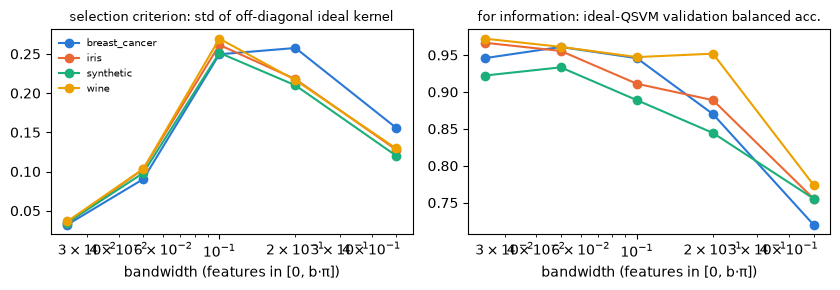

Configuration saved to configs/experiment_config.json


In [19]:
calib = calibrate_bandwidth(cfg)
calib.to_csv(os.path.join(OUT, "results", "bandwidth_calibration.csv"), index=False)
display(calib.round(3))
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.0))
for i, (ds, g) in enumerate(calib.groupby("dataset")):
    col = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"][i % 5]
    axes[0].plot(g.angle_scale, g.ideal_offdiag_std, marker="o", color=col, label=ds)
    axes[1].plot(g.angle_scale, g.val_score, marker="o", color=col, label=ds)
for ax, t in zip(axes, ["selection criterion: std of off-diagonal ideal kernel",
                        "for information: ideal-QSVM validation balanced acc."]):
    ax.set_xscale("log"); ax.set_xlabel("bandwidth (features in [0, b·π])"); ax.set_title(t, fontsize=9)
axes[0].legend(frameon=False, fontsize=7)
fig.tight_layout(); fig.savefig(os.path.join(OUT, "figures", "fig_bandwidth_calibration.png"), dpi=200)
plt.show()
cfg.save(os.path.join(OUT, "configs", "experiment_config.json"))
print("Configuration saved to configs/experiment_config.json")

## 7. Worked example on one split

One training kernel ($N$ = `n_train`) for the first dataset, the *medium* noise level and $S=64$ shots per entry:
ideal kernel, raw finite-shot noisy kernel, globally mitigated kernel, and the NA-QSVM training kernel, with
their errors relative to the ideal kernel. This illustrates §3.4: mitigation fixes the calibration
(scale and offset) but amplifies shot noise and creates negative eigenvalues; the noise-aware ridge restores PSD.

dataset=iris, noise=medium, simulator=aer (8.8s)  |  exact Λ=0.480, estimated Λ̂=0.473
implicit ridge of the raw kernel r_imp=(1-Λ)(1-1/d)/Λ = 1.015


,kernel,rel_fro_err,min_eig
0,raw (diag=1),0.4773,-0.2178
1,mitigated (avg),0.2102,-1.5061
2,NA-QSVM training kernel,0.1870,-0.0000


NA-QSVM on this split: {'balanced_accuracy': 0.8666666666666667, 'chosen': "{'c': 0.5, 'C': 1.0}", 'ridge_scale': 1.7718599733995402, 'ridge_used': 0.8859299866997701, 'n_sv': 52, 'total_shots': 468480}


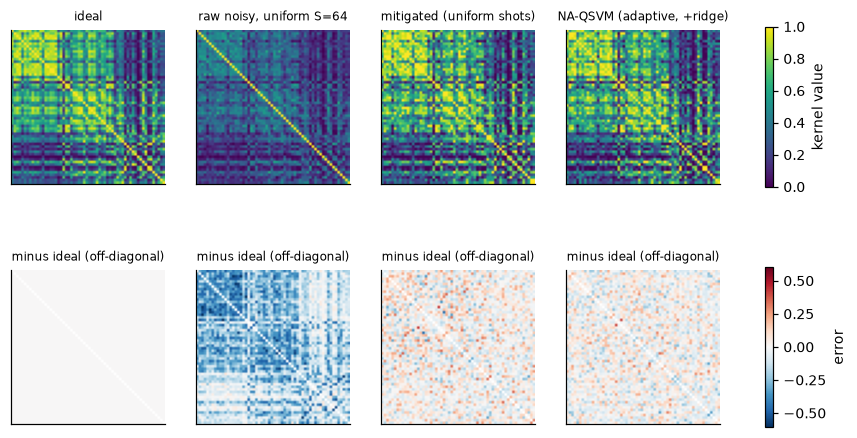

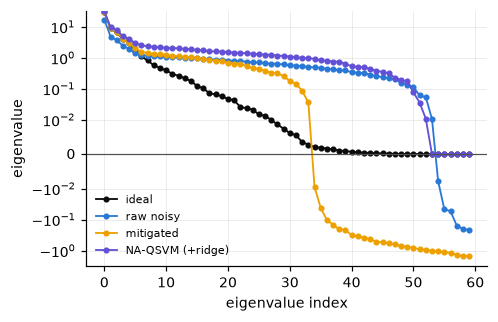

In [20]:
from naqsvm.methods import uniform_record, run_na_qsvm, _fill_sym
from naqsvm.experiment import _rng
ds0 = cfg.datasets[0]; seed0 = cfg.seeds[0]
noise0 = [n for n in cfg.noise_levels if n.name == "medium"][0]
X0, y0 = load_dataset(ds0)
sp0 = make_split(y0, cfg.n_train, cfg.n_val, cfg.n_test, seed0)
pr0 = prepare(X0, y0, sp0, cfg.n_qubits, angle_scale_for(cfg, ds0), seed0)
Kid = sims.ideal_kernel(pr0.A_train, pr0.A_train, cfg.reps, cfg.entanglement)
Kva = sims.ideal_kernel(pr0.A_val, pr0.A_train, cfg.reps, cfg.entanglement)
Kte = sims.ideal_kernel(pr0.A_test, pr0.A_train, cfg.reps, cfg.entanglement)
P0, used0, secs0, _ = compute_problem(pr0, noise0, cfg, BACKEND)
prob0 = QProblem(P0["P_tr"], P0["P_va"], P0["P_va_diag"], P0["P_te"], P0["P_te_diag"], Kid, Kva, Kte,
                 pr0.y_train, pr0.y_val, pr0.y_test, 2 ** cfg.n_qubits)
S0 = 64
rec = uniform_record(prob0, S0, _rng(0, "demo"))
Kraw = _fill_sym(len(Kid), rec["iu_off"], rec["tr_off"].estimate, 1.0)
lam0 = float(kx.survival_from_diag(rec["tr_diag"].estimate.mean(), prob0.d))
Kmit = kx.mitigate(Kraw, lam0, prob0.d); np.fill_diagonal(Kmit, 1.0)
na0 = run_na_qsvm(prob0, S0, _rng(0, "demo-na"), cfg, NA_VARIANTS[PROPOSED], PROPOSED, "proposed", return_kernels=True)
lam_true0 = float(kx.survival_from_diag(np.diag(P0["P_tr"]).mean(), prob0.d, 0))
print(f"dataset={ds0}, noise={noise0.name}, simulator={used0} ({secs0:.1f}s)  |  exact Λ={lam_true0:.3f}, estimated Λ̂={lam0:.3f}")
print(f"implicit ridge of the raw kernel r_imp=(1-Λ)(1-1/d)/Λ = {(1-lam_true0)*(1-1/prob0.d)/lam_true0:.3f}")
tab = pd.DataFrame([
    dict(kernel="raw (diag=1)", rel_fro_err=kx.rel_fro_error_offdiag(Kraw, Kid), min_eig=kx.min_eig(Kraw)),
    dict(kernel="mitigated (avg)", rel_fro_err=kx.rel_fro_error_offdiag(Kmit, Kid), min_eig=kx.min_eig(Kmit)),
    dict(kernel="NA-QSVM training kernel", rel_fro_err=na0["kernel_rel_fro_err"], min_eig=na0["min_eig_after"])])
display(tab.round(4))
print("NA-QSVM on this split:", {k: na0[k] for k in ["balanced_accuracy", "chosen", "ridge_scale", "ridge_used", "n_sv", "total_shots"]})
Kna_disp = na0["_K_train_used"]          # NA-QSVM training kernel (adaptive shots, mitigated, ridge, PSD)
npl.kernel_heatmaps([Kid, Kraw, Kmit, Kna_disp], ["ideal", f"raw noisy, uniform S={S0}", "mitigated (uniform shots)",
                                                  "NA-QSVM (adaptive, +ridge)"],
                    path=os.path.join(OUT, "figures", "fig_kernel_heatmaps.png"), diff_to=Kid)
plt.show()
fig, ax = plt.subplots(figsize=(4.6, 3.0))
for M, lab, col in [(Kid, "ideal", "#0b0b0b"), (Kraw, "raw noisy", "#2a78d6"), (Kmit, "mitigated", "#eda100"),
                    (Kna_disp, "NA-QSVM (+ridge)", "#6250d6")]:
    ax.plot(np.sort(np.linalg.eigvalsh(M))[::-1], marker=".", lw=1.2, color=col, label=lab)
ax.axhline(0, color="#52514e", lw=0.8); ax.set_yscale("symlog", linthresh=1e-2)
ax.set_xlabel("eigenvalue index"); ax.set_ylabel("eigenvalue"); ax.legend(frameon=False, fontsize=7)
fig.tight_layout(); fig.savefig(os.path.join(OUT, "figures", "fig_eigen_spectra.png"), dpi=200); plt.show()

*Note:* the NA-QSVM panel is the training kernel that method actually used. It comes from its own adaptive measurement
record with the same total budget, so its noise pattern differs from the uniformly measured panels. The ridge sits on the
diagonal, which the colour scale saturates at 1 and the error row hides.

## 8. Main experiment

For every dataset × seed: split → train-only preprocessing → ideal kernels → (per noise level) exact noisy
probabilities, simulated once and cached → (per shot budget) one shared uniform train/validation record for the
established methods, independent adaptive records for the prior-work allocators, and adaptive records for NA-QSVM and
its ablations (common random numbers across the NA variants). Every method then measures its own SV-restricted test
kernel with the same test budget. Failures are caught, logged to `results/failures.csv`, and do not stop the run.

In [21]:
t0 = time.perf_counter()
raw = run_grid(cfg, os.path.join(OUT, "results"), BACKEND, verbose=True, log_every=1)
GRID_SECONDS = time.perf_counter() - t0
print(f"grid finished in {GRID_SECONDS/60:.1f} min; {len(raw)} result rows")
fail_path = os.path.join(OUT, "results", "failures.csv")
n_fail = len(pd.read_csv(fail_path)) if os.path.exists(fail_path) else 0
print("logged failures:", n_fail)
simlog = pd.read_csv(os.path.join(OUT, "results", "simulation_log.csv"))
print("simulator backends used:", simlog.backend.value_counts().to_dict())

[  1/40] iris           seed=2000 elapsed    49.0s
[  2/40] iris           seed=2001 elapsed   100.0s
[  3/40] iris           seed=2002 elapsed   151.2s
[  4/40] iris           seed=2003 elapsed   202.1s
[  5/40] iris           seed=2004 elapsed   259.1s
[  6/40] iris           seed=2005 elapsed   313.6s
[  7/40] iris           seed=2006 elapsed   367.6s
[  8/40] iris           seed=2007 elapsed   423.2s
[  9/40] iris           seed=2008 elapsed   479.9s
[ 10/40] iris           seed=2009 elapsed   541.7s
[ 11/40] wine           seed=2000 elapsed   605.5s
[ 12/40] wine           seed=2001 elapsed   669.6s
[ 13/40] wine           seed=2002 elapsed   732.8s
[ 14/40] wine           seed=2003 elapsed   794.2s
[ 15/40] wine           seed=2004 elapsed   855.5s
[ 16/40] wine           seed=2005 elapsed   919.0s
[ 17/40] wine           seed=2006 elapsed   982.6s
[ 18/40] wine           seed=2007 elapsed  1045.1s
[ 19/40] wine           seed=2008 elapsed  1107.4s
[ 20/40] wine           seed=20

## 8b. Direct test of Theorem 1 (contribution C2)

For every split and noise setting we compare the decision values on the test set of
**A** = SVM on the raw noisy kernel (diag = 1, box $C=1$), **B** = SVM on the *ideal* kernel plus the hidden ridge
$r=(1-\Lambda)(1-1/d)/\Lambda$ (box $\Lambda C$), and **Z** = SVM on the ideal kernel without ridge (box $\Lambda C$, control).
Settings: an analytic **global** depolarizing channel at $\Lambda\in\{0.8,0.5,0.25\}$ (Theorem 1 must hold to solver precision),
the local gate-noise levels, and the non-unital thermal setting, each with exact probabilities and with finite shots.
$\Lambda$ is the exact mean diagonal survival (an oracle: this is an *explanation* of the noisy SVM, not a method).
Metric: relative difference of decision values $\|f_A-f_X\|/\|f_A\|$ (0 = identical classifier) and prediction agreement.

hidden-ridge check: iris done (210 rows)
hidden-ridge check: wine done (420 rows)
hidden-ridge check: breast_cancer done (630 rows)
hidden-ridge check: synthetic done (840 rows)


**Table 6. Hidden-ridge test** (means over datasets × seeds; B = ideal kernel + hidden ridge, Z = no-ridge control)

,noise,shots_per_entry,lam,hidden_ridge,B_decision_rel_diff,Z_decision_rel_diff,B_pred_agreement,Z_pred_agreement,acc_raw,acc_ideal_plus_ridge,acc_ideal_no_ridge
0,global Λ=0.8,exact,0.8000,0.2344,0.0000,0.0848,1.0000,0.9912,0.8504,0.8504,0.8492
1,global Λ=0.8,1024,0.8000,0.2344,0.0934,0.1269,0.9754,0.9733,0.8533,0.8504,0.8492
2,global Λ=0.8,64,0.8000,0.2344,0.3263,0.3230,0.9188,0.9150,0.8338,0.8504,0.8492
3,global Λ=0.5,exact,0.5000,0.9375,0.0000,0.2317,1.0000,0.9746,0.8438,0.8438,0.8342
4,global Λ=0.5,1024,0.5000,0.9375,0.1036,0.2540,0.9692,0.9596,0.8492,0.8438,0.8342
5,global Λ=0.5,64,0.5000,0.9375,0.3661,0.3907,0.9000,0.8946,0.8138,0.8438,0.8342
6,global Λ=0.25,exact,0.2500,2.8125,0.0000,0.4195,1.0000,0.9412,0.8342,0.8342,0.8012
7,global Λ=0.25,1024,0.2500,2.8125,0.1312,0.4514,0.9667,0.9329,0.8325,0.8342,0.8012
8,global Λ=0.25,64,0.2500,2.8125,0.4278,0.5749,0.8588,0.8567,0.7821,0.8342,0.8012
9,low,exact,0.7699,0.2802,0.0079,0.0979,0.9979,0.9900,0.8504,0.8500,0.8471


**Is the hidden-ridge model closer to the raw noisy SVM than the no-ridge control?** (difference Z − B of relative decision difference; Wilcoxon, Holm)

,noise,shots_per_entry,n,mean_improvement,frac_B_closer,p_wilcoxon,p_holm
0,global Λ=0.8,exact,40,0.0848,1.000,0.0000,0.0000
1,global Λ=0.8,1024,40,0.0335,1.000,0.0000,0.0000
2,global Λ=0.8,64,40,-0.0033,0.350,0.0548,0.1096
3,global Λ=0.5,exact,40,0.2317,1.000,0.0000,0.0000
4,global Λ=0.5,1024,40,0.1504,1.000,0.0000,0.0000
5,global Λ=0.5,64,40,0.0247,0.700,0.0001,0.0004
6,global Λ=0.25,exact,40,0.4195,1.000,0.0000,0.0000
7,global Λ=0.25,1024,40,0.3202,1.000,0.0000,0.0000
8,global Λ=0.25,64,40,0.1471,0.975,0.0000,0.0000
9,low,exact,40,0.0901,1.000,0.0000,0.0000


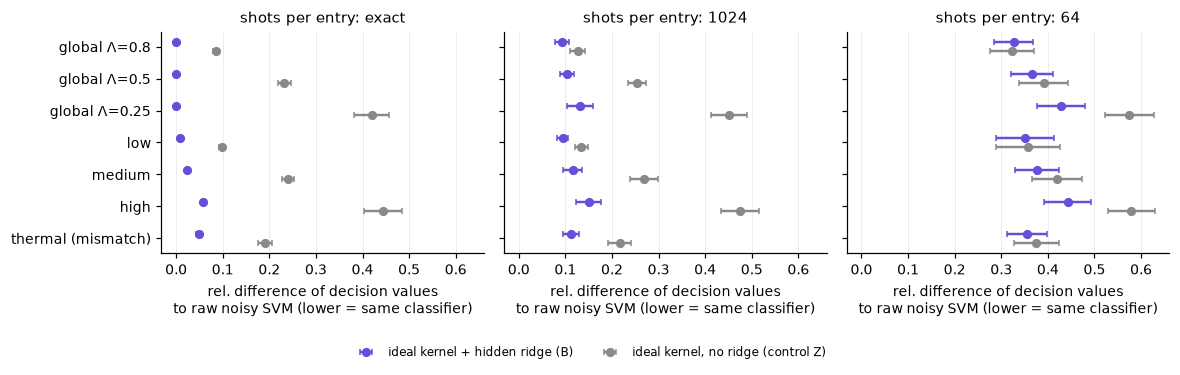

In [22]:
RES, FIG, TAB = (os.path.join(OUT, s_) for s_ in ("results", "figures", "tables"))
hr = run_hidden_ridge(cfg, os.path.join(OUT, "results"), BACKEND)
hr_ok = hr[hr.status == "ok"].copy()
hr_ok["shots_per_entry"] = hr_ok["shots_per_entry"].astype(str)
order_noise = list(dict.fromkeys(hr_ok.noise))
order_shots = list(dict.fromkeys(hr_ok.shots_per_entry))
hr_tab = (hr_ok.groupby(["noise", "shots_per_entry"], sort=False)
          [["lam", "hidden_ridge", "B_decision_rel_diff", "Z_decision_rel_diff", "B_pred_agreement", "Z_pred_agreement",
            "acc_raw", "acc_ideal_plus_ridge", "acc_ideal_no_ridge"]].mean().reset_index())
hr_tab.to_csv(os.path.join(TAB, "table6_hidden_ridge.csv"), index=False)
display(Markdown("**Table 6. Hidden-ridge test** (means over datasets × seeds; B = ideal kernel + hidden ridge, Z = no-ridge control)"))
display(hr_tab.round(4))
# paired test per (noise, shots): is B closer to the raw SVM than Z?
hr_stats = []
for (nz, S), g in hr_ok.groupby(["noise", "shots_per_entry"], sort=False):
    dd = (g.Z_decision_rel_diff - g.B_decision_rel_diff).values
    hr_stats.append(dict(noise=nz, shots_per_entry=S, n=len(dd), mean_improvement=float(np.mean(dd)),
                         frac_B_closer=float(np.mean(dd > 0)), p_wilcoxon=nst.wilcoxon_p(dd)))
hr_stats = pd.DataFrame(hr_stats)
hr_stats["p_holm"] = nst.holm(hr_stats.p_wilcoxon)
hr_stats.to_csv(os.path.join(TAB, "stats_hidden_ridge.csv"), index=False)
display(Markdown("**Is the hidden-ridge model closer to the raw noisy SVM than the no-ridge control?** (difference Z − B of relative decision difference; Wilcoxon, Holm)"))
display(hr_stats.round(4))
npl.hidden_ridge_plot(hr_ok, path=os.path.join(FIG, "fig_hidden_ridge_test.png")); plt.show()

## 9. Results: tables and figures

Statistical unit for CIs: a (dataset, seed) split, averaging over the cells inside it where stated. CIs are
95% Student-t intervals over units. Raw per-row results are in `results/raw_results.csv`.

In [23]:
RES, FIG, TAB = (os.path.join(OUT, s) for s in ("results", "figures", "tables"))
raw = pd.read_csv(os.path.join(RES, "raw_results.csv"))
ok = raw[raw.status == "ok"].copy()
refs = ok[ok.family == "reference"]
q = ok[ok.family != "reference"].copy()
for col in ["psd_after", "selected_kernel_needed_clip", "ridge_alone_psd_at_c1"]:   # CSV booleans -> 0/1
    q[col] = q[col].map({True: 1.0, False: 0.0, "True": 1.0, "False": 0.0}).astype(float)
METRICS = ["accuracy", "macro_f1", "balanced_accuracy", "kernel_rel_fro_err", "kernel_alignment_gap",
           "runtime_s", "total_shots"]
NOISES = [n.name for n in cfg.noise_levels]
MAIN = ESTABLISHED + ALLOCATION_BASELINES + [PROPOSED]
PLOT = npl.MAIN_METHODS                     # 7 series shown in line plots (all methods are in the tables)
ABL = [m for m in NA_VARIANTS if m != PROPOSED]
fmt = lambda m, lo, hi, nd=3: f"{m:.{nd}f} [{lo:.{nd}f}, {hi:.{nd}f}]" if np.isfinite(m) else "–"

# per-cell summary (dataset, noise, shots, method) over seeds
cell = nst.summarize(q, ["dataset", "noise", "shots_per_entry", "method"], METRICS)
cell.to_csv(os.path.join(RES, "summary_by_cell.csv"), index=False)

# unit-level (dataset, seed) means
def unit_means(df, extra=()):
    return df.groupby(["method", *extra, "dataset", "seed"], as_index=False)[METRICS].mean()

# Table 1: balanced accuracy by noise level (mean over datasets, seeds, shot budgets)
u = unit_means(q, ["noise"])
t1 = {}
for (m, nz), g in u.groupby(["method", "noise"]):
    t1.setdefault(m, {})[nz] = fmt(*nst.t_ci(g.balanced_accuracy))
ref_u = refs.groupby(["method", "dataset", "seed"], as_index=False).balanced_accuracy.mean()
for m, g in ref_u.groupby("method"):
    t1[m] = {nz: fmt(*nst.t_ci(g.balanced_accuracy)) for nz in NOISES}
order = MAIN + ABL + list(ref_u.method.unique())
table1 = pd.DataFrame(t1).T.reindex(order)[NOISES].reset_index().rename(columns={"index": "method"})
table1.to_csv(os.path.join(TAB, "table1_balanced_accuracy_by_noise.csv"), index=False)
with open(os.path.join(TAB, "table1_balanced_accuracy_by_noise.tex"), "w") as f:
    f.write(rep.df_to_latex(table1, "Test balanced accuracy, mean [95% CI] over dataset x seed units (shot budgets averaged). References do not depend on noise.", "tab:bacc_noise"))
display(Markdown("**Table 1. Test balanced accuracy by noise level** (mean [95% CI]; units = dataset × seed; shot budgets averaged)"))
display(table1)

**Table 1. Test balanced accuracy by noise level** (mean [95% CI]; units = dataset × seed; shot budgets averaged)

,method,noise-free,low,medium,high,thermal (mismatch)
0,QSVM-raw,"0.837 [0.808, 0.866]","0.833 [0.804, 0.863]","0.809 [0.778, 0.841]","0.777 [0.747, 0.807]","0.820 [0.790, 0.850]"
1,QSVM-clip,"0.837 [0.806, 0.869]","0.830 [0.800, 0.860]","0.816 [0.787, 0.846]","0.776 [0.747, 0.805]","0.811 [0.780, 0.842]"
2,QSVM-flip,"0.838 [0.808, 0.869]","0.829 [0.798, 0.860]","0.812 [0.782, 0.842]","0.781 [0.751, 0.811]","0.814 [0.784, 0.845]"
3,QSVM-shift,"0.833 [0.802, 0.864]","0.831 [0.802, 0.859]","0.815 [0.785, 0.844]","0.770 [0.740, 0.800]","0.818 [0.788, 0.847]"
4,QSVM-mitig(avg)+clip,"0.838 [0.808, 0.867]","0.825 [0.794, 0.856]","0.814 [0.784, 0.844]","0.768 [0.741, 0.794]","0.817 [0.787, 0.847]"
5,QSVM-mitig(split)+clip,"0.837 [0.806, 0.868]","0.831 [0.802, 0.860]","0.807 [0.777, 0.838]","0.764 [0.738, 0.789]","0.814 [0.784, 0.844]"
6,AQKA-Bernoulli+clip,"0.836 [0.806, 0.867]","0.830 [0.802, 0.858]","0.815 [0.785, 0.844]","0.777 [0.747, 0.806]","0.811 [0.779, 0.843]"
7,AQKA-SVM+clip,"0.838 [0.810, 0.866]","0.824 [0.793, 0.855]","0.810 [0.779, 0.840]","0.782 [0.751, 0.813]","0.812 [0.782, 0.841]"
8,MarginNeyman+clip (Miroszewski-style approx.),"0.837 [0.808, 0.867]","0.832 [0.805, 0.860]","0.813 [0.784, 0.842]","0.781 [0.753, 0.809]","0.820 [0.790, 0.850]"
9,NA-QSVM (proposed),"0.836 [0.806, 0.867]","0.829 [0.801, 0.858]","0.819 [0.789, 0.850]","0.781 [0.754, 0.808]","0.812 [0.782, 0.842]"


In [24]:
# Table 2: all metrics, averaged over everything (units = dataset x seed)
u_all = unit_means(q)
rows = []
for m in MAIN + ABL:
    g = u_all[u_all.method == m]
    r = {"method": m}
    for k in METRICS:
        r[k] = fmt(*nst.t_ci(g[k]), nd=(0 if k == "total_shots" else 4 if k == "runtime_s" else 3))
    rows.append(r)
for m, g in refs.groupby("method"):
    gg = g.groupby(["dataset", "seed"])[["accuracy", "macro_f1", "balanced_accuracy", "runtime_s"]].mean()
    rows.append({"method": m, **{k: fmt(*nst.t_ci(gg[k]), nd=4 if k == "runtime_s" else 3)
                                 for k in ["accuracy", "macro_f1", "balanced_accuracy", "runtime_s"]},
                 "kernel_rel_fro_err": "–", "kernel_alignment_gap": "–",
                 "total_shots": "exact (∞)" if "Ideal" in m else "0"})
table2 = pd.DataFrame(rows)
table2.to_csv(os.path.join(TAB, "table2_all_metrics.csv"), index=False)
with open(os.path.join(TAB, "table2_all_metrics.tex"), "w") as f:
    f.write(rep.df_to_latex(table2, "All metrics, mean [95% CI] over dataset x seed units (all noise levels and shot budgets averaged). runtime_s = classical post-processing + SVM time; circuit simulation time excluded.", "tab:all"))
display(Markdown("**Table 2. All metrics** (kernel errors use the training kernel; runtime = classical processing; total shots = train + val + test)"))
display(table2)

**Table 2. All metrics** (kernel errors use the training kernel; runtime = classical processing; total shots = train + val + test)

,method,accuracy,macro_f1,balanced_accuracy,kernel_rel_fro_err,kernel_alignment_gap,runtime_s,total_shots
0,QSVM-raw,"0.821 [0.792, 0.851]","0.815 [0.785, 0.845]","0.815 [0.786, 0.845]","0.375 [0.371, 0.378]","0.139 [0.133, 0.146]","0.0162 [0.0148, 0.0176]","2458200 [2458200, 2458200]"
1,QSVM-clip,"0.820 [0.790, 0.850]","0.814 [0.784, 0.844]","0.814 [0.785, 0.844]","0.367 [0.364, 0.370]","0.133 [0.127, 0.139]","0.0160 [0.0149, 0.0170]","2458200 [2458200, 2458200]"
2,QSVM-flip,"0.820 [0.790, 0.850]","0.815 [0.784, 0.845]","0.815 [0.785, 0.845]","0.367 [0.364, 0.370]","0.137 [0.131, 0.143]","0.0163 [0.0151, 0.0175]","2458200 [2458200, 2458200]"
3,QSVM-shift,"0.819 [0.790, 0.849]","0.813 [0.784, 0.843]","0.813 [0.784, 0.842]","0.375 [0.371, 0.378]","0.173 [0.164, 0.183]","0.0159 [0.0150, 0.0168]","2458200 [2458200, 2458200]"
4,QSVM-mitig(avg)+clip,"0.816 [0.787, 0.844]","0.810 [0.781, 0.839]","0.812 [0.784, 0.841]","0.144 [0.136, 0.153]","0.060 [0.057, 0.063]","0.0162 [0.0152, 0.0172]","2488800 [2488800, 2488800]"
5,QSVM-mitig(split)+clip,"0.814 [0.786, 0.843]","0.809 [0.780, 0.837]","0.810 [0.782, 0.839]","0.169 [0.160, 0.177]","0.065 [0.061, 0.068]","0.0162 [0.0152, 0.0172]","2488800 [2488800, 2488800]"
6,AQKA-Bernoulli+clip,"0.819 [0.789, 0.849]","0.814 [0.784, 0.843]","0.814 [0.785, 0.843]","0.367 [0.364, 0.371]","0.131 [0.126, 0.137]","0.0159 [0.0147, 0.0171]","2488800 [2488800, 2488800]"
7,AQKA-SVM+clip,"0.819 [0.789, 0.848]","0.813 [0.783, 0.843]","0.813 [0.784, 0.842]","0.377 [0.373, 0.381]","0.144 [0.138, 0.149]","0.0215 [0.0207, 0.0223]","2488800 [2488800, 2488800]"
8,MarginNeyman+clip (Miroszewski-style approx.),"0.823 [0.795, 0.852]","0.817 [0.788, 0.846]","0.817 [0.789, 0.845]","0.374 [0.370, 0.378]","0.140 [0.135, 0.146]","0.0174 [0.0165, 0.0183]","2488800 [2488800, 2488800]"
9,NA-QSVM (proposed),"0.820 [0.791, 0.849]","0.815 [0.786, 0.844]","0.816 [0.787, 0.844]","0.171 [0.163, 0.180]","0.115 [0.103, 0.127]","0.0661 [0.0626, 0.0696]","2488800 [2488800, 2488800]"


In [25]:
# Table 3: per dataset x shot budget at the 'medium' noise level (balanced accuracy)
nz = "medium" if "medium" in NOISES else NOISES[-1]
c = cell[(cell.noise == nz) & cell.method.isin(MAIN)]
c = c.assign(val=[fmt(a, b, d) for a, b, d in zip(c.balanced_accuracy_mean, c.balanced_accuracy_ci_lo, c.balanced_accuracy_ci_hi)])
table3 = c.pivot_table(index=["dataset", "shots_per_entry"], columns="method", values="val", aggfunc="first")[MAIN].reset_index()
table3.to_csv(os.path.join(TAB, f"table3_bacc_{nz}_by_dataset_shots.csv"), index=False)
display(Markdown(f"**Table 3. Balanced accuracy at noise = {nz}, per dataset and shot budget** (mean [95% CI] over seeds)"))
display(table3)

**Table 3. Balanced accuracy at noise = medium, per dataset and shot budget** (mean [95% CI] over seeds)

method,dataset,shots_per_entry,QSVM-raw,QSVM-clip,QSVM-flip,QSVM-shift,QSVM-mitig(avg)+clip,QSVM-mitig(split)+clip,AQKA-Bernoulli+clip,AQKA-SVM+clip,MarginNeyman+clip (Miroszewski-style approx.),NA-QSVM (proposed)
0,breast_cancer,16,"0.769 [0.730, 0.808]","0.782 [0.733, 0.830]","0.752 [0.701, 0.803]","0.769 [0.714, 0.824]","0.802 [0.752, 0.853]","0.779 [0.730, 0.828]","0.793 [0.739, 0.848]","0.800 [0.762, 0.837]","0.782 [0.725, 0.839]","0.782 [0.722, 0.842]"
1,breast_cancer,64,"0.805 [0.754, 0.855]","0.816 [0.765, 0.866]","0.797 [0.747, 0.848]","0.803 [0.761, 0.845]","0.812 [0.747, 0.876]","0.828 [0.777, 0.880]","0.807 [0.763, 0.850]","0.810 [0.766, 0.854]","0.797 [0.746, 0.848]","0.826 [0.774, 0.879]"
2,breast_cancer,256,"0.831 [0.775, 0.886]","0.829 [0.780, 0.877]","0.828 [0.784, 0.872]","0.833 [0.781, 0.885]","0.843 [0.807, 0.879]","0.807 [0.772, 0.842]","0.823 [0.779, 0.868]","0.823 [0.785, 0.861]","0.837 [0.790, 0.885]","0.866 [0.815, 0.918]"
3,breast_cancer,1024,"0.830 [0.784, 0.876]","0.816 [0.766, 0.866]","0.820 [0.769, 0.871]","0.826 [0.779, 0.873]","0.859 [0.816, 0.901]","0.848 [0.796, 0.900]","0.832 [0.781, 0.884]","0.830 [0.784, 0.875]","0.834 [0.786, 0.883]","0.843 [0.795, 0.891]"
4,iris,16,"0.823 [0.779, 0.868]","0.823 [0.779, 0.868]","0.838 [0.809, 0.868]","0.838 [0.803, 0.873]","0.837 [0.802, 0.871]","0.825 [0.794, 0.856]","0.822 [0.788, 0.855]","0.808 [0.775, 0.841]","0.818 [0.792, 0.845]","0.820 [0.793, 0.847]"
5,iris,64,"0.857 [0.821, 0.892]","0.875 [0.846, 0.904]","0.897 [0.877, 0.917]","0.870 [0.844, 0.896]","0.858 [0.838, 0.879]","0.857 [0.816, 0.897]","0.837 [0.800, 0.873]","0.857 [0.838, 0.875]","0.867 [0.827, 0.907]","0.855 [0.824, 0.886]"
6,iris,256,"0.887 [0.860, 0.913]","0.898 [0.866, 0.931]","0.895 [0.861, 0.929]","0.908 [0.878, 0.938]","0.890 [0.862, 0.918]","0.893 [0.860, 0.927]","0.895 [0.867, 0.923]","0.893 [0.857, 0.929]","0.895 [0.865, 0.925]","0.893 [0.861, 0.925]"
7,iris,1024,"0.905 [0.875, 0.935]","0.903 [0.872, 0.935]","0.905 [0.872, 0.938]","0.905 [0.870, 0.940]","0.888 [0.854, 0.923]","0.898 [0.865, 0.931]","0.902 [0.869, 0.935]","0.903 [0.873, 0.933]","0.903 [0.871, 0.936]","0.902 [0.876, 0.927]"
8,synthetic,16,"0.668 [0.564, 0.773]","0.690 [0.611, 0.769]","0.700 [0.622, 0.778]","0.652 [0.559, 0.744]","0.700 [0.612, 0.788]","0.643 [0.566, 0.721]","0.683 [0.589, 0.778]","0.627 [0.529, 0.724]","0.658 [0.567, 0.749]","0.655 [0.566, 0.744]"
9,synthetic,64,"0.687 [0.597, 0.776]","0.707 [0.631, 0.782]","0.678 [0.608, 0.749]","0.717 [0.637, 0.796]","0.677 [0.580, 0.773]","0.683 [0.605, 0.762]","0.713 [0.645, 0.782]","0.698 [0.615, 0.782]","0.708 [0.646, 0.771]","0.677 [0.589, 0.764]"


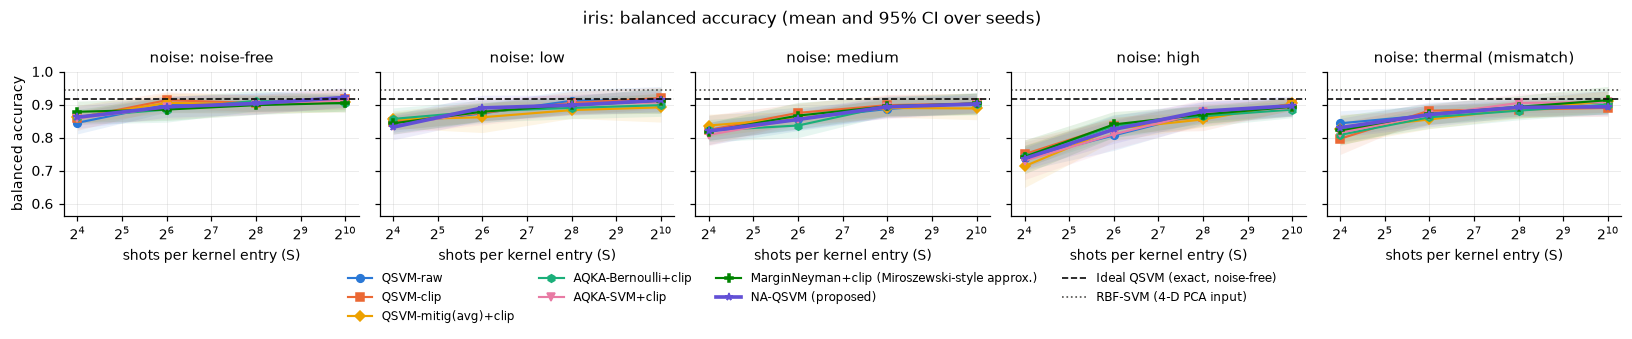

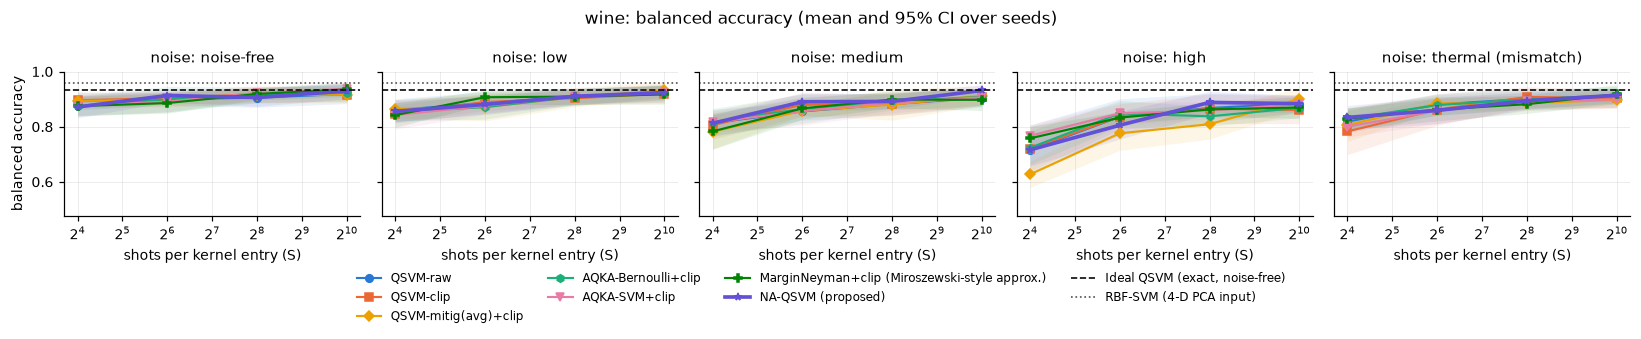

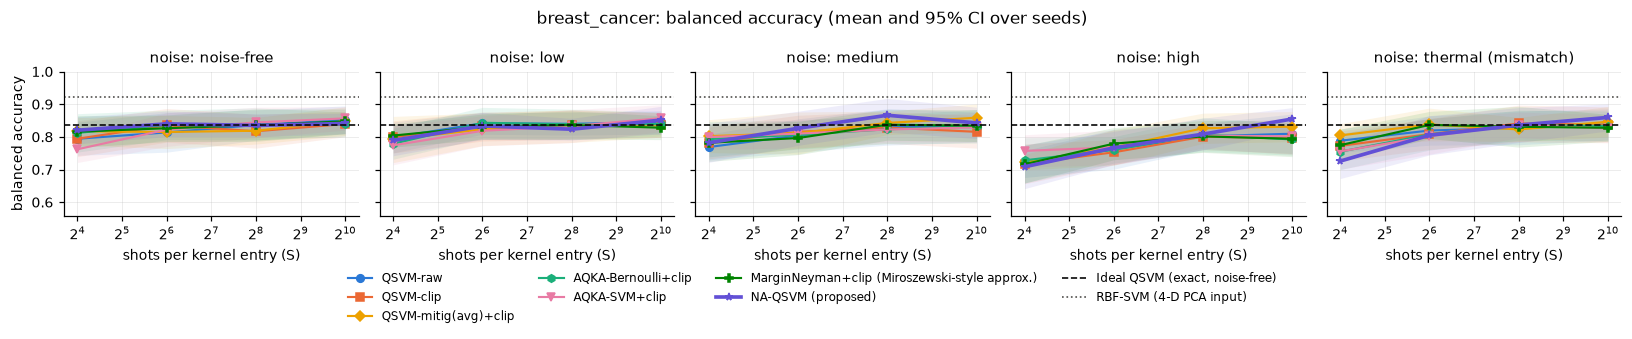

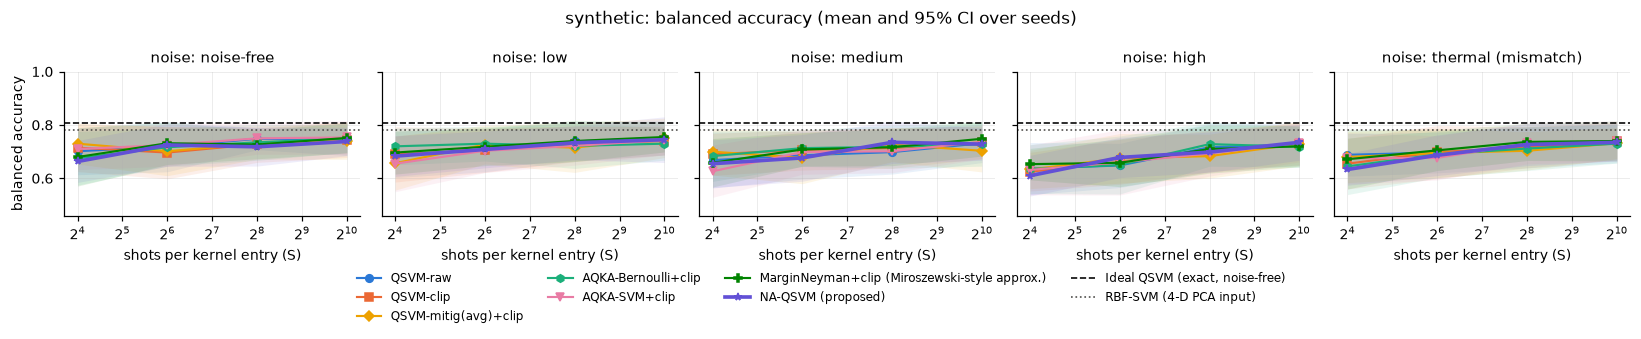

In [26]:
# Figures: balanced accuracy vs shots, one figure per dataset (all noise levels)
for ds in cfg.datasets:
    npl.metric_vs_shots(cell, refs, ds, "balanced_accuracy", NOISES, PLOT,
                        path=os.path.join(FIG, f"fig_bacc_vs_shots_{ds}.png"), ylabel="balanced accuracy")
    plt.show()

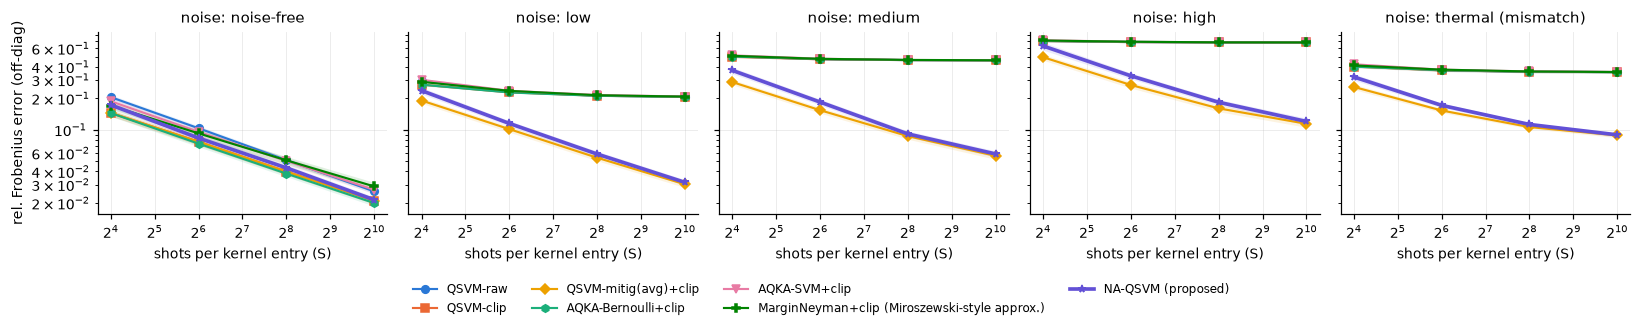

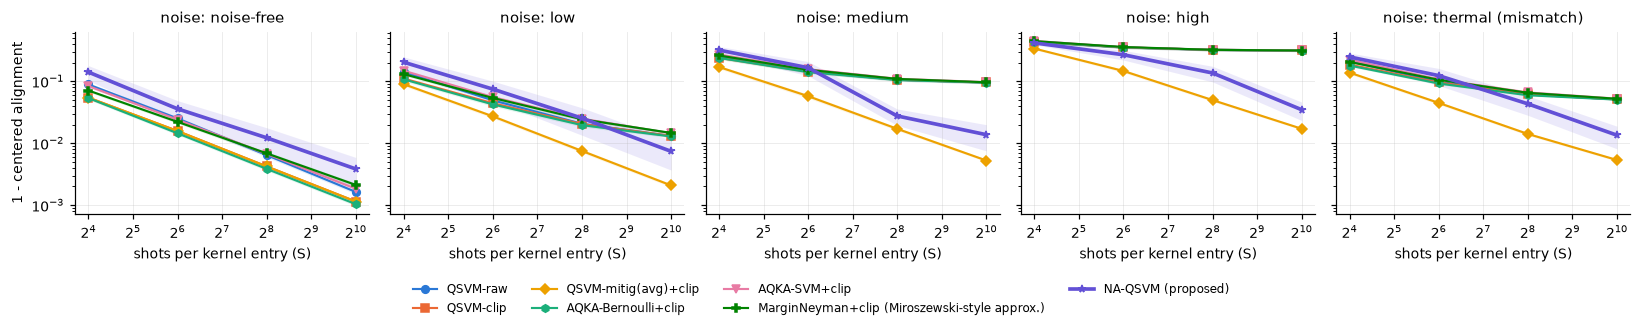

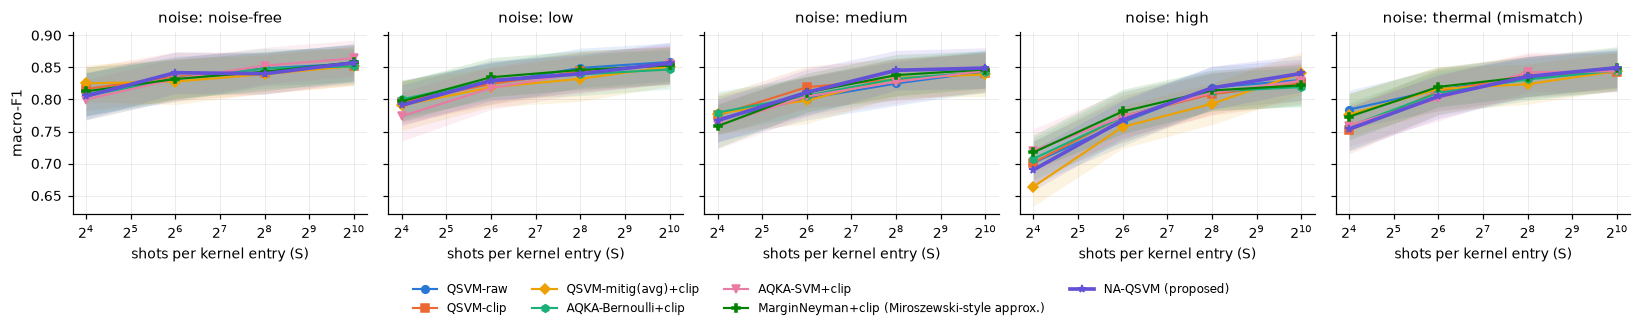

In [27]:
# Kernel-matrix error and macro-F1, averaged over datasets (units = dataset x seed)
uns = q.groupby(["method", "noise", "shots_per_entry", "dataset", "seed"], as_index=False)[METRICS].mean()
s_ns = nst.summarize(uns, ["noise", "shots_per_entry", "method"], METRICS)
s_ns.to_csv(os.path.join(RES, "summary_by_noise_shots.csv"), index=False)
npl.lines_by_noise(s_ns, "kernel_rel_fro_err", PLOT, NOISES, path=os.path.join(FIG, "fig_kernel_rel_fro_error.png"),
                   ylabel="rel. Frobenius error (off-diag)", logy=True); plt.show()
npl.lines_by_noise(s_ns, "kernel_alignment_gap", PLOT, NOISES, path=os.path.join(FIG, "fig_kernel_alignment_gap.png"),
                   ylabel="1 - centered alignment", logy=True); plt.show()
npl.lines_by_noise(s_ns, "macro_f1", PLOT, NOISES, path=os.path.join(FIG, "fig_macro_f1.png"), ylabel="macro-F1"); plt.show()

**Table 4. Fraction of training kernels indefinite before repair / PSD after repair**

indefinite_before                                             psd_after                                           
noise                                                      high    low medium noise-free thermal (mismatch)      high   low medium noise-free thermal (mismatch)
method                                                                                                                                                          
AQKA-Bernoulli+clip                                       0.250  0.731  0.481        1.0              0.588     1.000  1.00  1.000        1.0              1.000
AQKA-SVM+clip                                             0.419  0.912  0.538        1.0              0.688     1.000  1.00  1.000        1.0              1.000
Abl: SV-weighted train alloc                              1.000  1.000  1.000        1.0              1.000     1.000  1.00  1.000        1.0              1.000
Abl: no SV-restricted test                                1.000  1.000  1.000        1.0              1.000     1.000  1.00  1.000        1.0              1.000
Abl: no mitigation                                        0.256  0.731  0.494        1.0              0.606     1.000  1.00  1.000        1.0              1.000
Abl: no noise-aware ridge                                 1.000  1.000  1.000        1.0              1.000     1.000  1.00  1.000        1.0              1.000
Abl: ridge c=1 (untuned)                                  1.000  1.000  1.000        1.0              1.000     1.000  1.00  1.000        1.0              1.000
Abl: uniform shots                                        1.000  1.000  1.000        1.0              1.000     1.000  1.00  1.000        1.0              1.000
MarginNeyman+clip (Miroszewski-style approx.)             0.362  0.931  0.512        1.0              0.706     1.000  1.00  1.000        1.0              1.000
NA-QSVM (proposed)                                        1.000  1.000  1.000        1.0              1.000     1.000  1.00  1.000        1.0              1.000
QSVM-clip                                                 0.256  0.750  0.494        1.0              0.631     1.000  1.00  1.000        1.0              1.000
QSVM-flip                                                 0.256  0.750  0.494        1.0              0.631     1.000  1.00  1.000        1.0              1.000
QSVM-mitig(avg)+clip                                      1.000  1.000  1.000        1.0              1.000     1.000  1.00  1.000        1.0              1.000
QSVM-mitig(split)+clip                                    1.000  1.000  1.000        1.0              1.000     1.000  1.00  1.000        1.0              1.000
QSVM-raw                                                  0.256  0.750  0.494        1.0              0.631     0.744  0.25  0.506        0.0              0.369
QSVM-shift                                                0.256  0.750  0.494        1.0              0.631     1.000  1.00  1.000        1.0              1.000
Variant: shot-saving (SV test, S/entry)                   1.000  1.000  1.000        1.0              1.000     1.000  1.00  1.000        1.0              1.000

PSD violations after repair among methods that guarantee PSD: 0 rows
NA-QSVM: validation selected a ridge c > 0 in 50.5% of runs; the selected kernel was PSD without clipping in 27.1%; the ridge with c = 1 alone gave a PSD kernel in 99.9% of runs


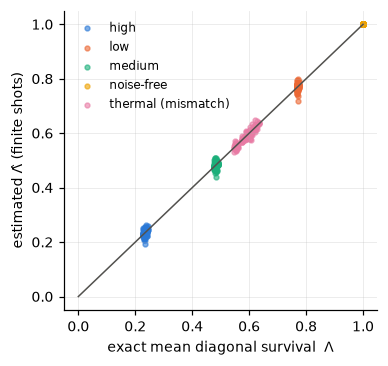

In [28]:
# PSD diagnostics: how often is the training kernel indefinite before repair, and is it PSD after?
psd = (q.assign(indefinite_before=q.min_eig_before < -1e-9)
         .groupby(["method", "noise"])[["indefinite_before", "psd_after"]].mean().unstack("noise"))
psd.to_csv(os.path.join(TAB, "table4_psd_diagnostics.csv"))
display(Markdown("**Table 4. Fraction of training kernels indefinite before repair / PSD after repair**"))
display(psd.round(3))
must_be_psd = [m for m in MAIN + ABL if m not in ("QSVM-raw",)]
viol = q[q.method.isin(must_be_psd) & (q.psd_after == 0)]
print(f"PSD violations after repair among methods that guarantee PSD: {len(viol)} rows")
assert len(viol) == 0, "a method that should return a PSD kernel did not"
na = q[q.method == PROPOSED]
print(f"NA-QSVM: validation selected a ridge c > 0 in {(na.ridge_used > 0).mean():.1%} of runs; "
      f"the selected kernel was PSD without clipping in {(1 - na.selected_kernel_needed_clip).mean():.1%}; "
      f"the ridge with c = 1 alone gave a PSD kernel in {na.ridge_alone_psd_at_c1.mean():.1%} of runs")
npl.scatter_lambda(na, path=os.path.join(FIG, "fig_lambda_estimate.png")); plt.show()

In [29]:
# Shots and runtime
sh = q.groupby("method")[["total_shots", "train_shots", "val_shots", "test_shots", "runtime_s", "n_sv"]].mean().reindex(MAIN + ABL)
sh.to_csv(os.path.join(TAB, "table5_shots_runtime.csv"))
display(Markdown("**Table 5. Mean shots per run (train/val/test), classical runtime (s) and support-vector count**"))
display(sh.round({"total_shots": 0, "train_shots": 0, "val_shots": 0, "test_shots": 0, "runtime_s": 4, "n_sv": 1}))
display(Markdown("Circuit-simulation time is shared by all quantum methods and is not a hardware runtime; see `results/simulation_log.csv`."))
display(simlog.groupby("noise")[["sim_seconds", "n_circuits", "lambda_true", "neyman_oracle_var_ratio", "exact_noisy_rel_err"]].mean().round(3))

**Table 5. Mean shots per run (train/val/test), classical runtime (s) and support-vector count**

,total_shots,train_shots,val_shots,test_shots,runtime_s,n_sv
method,,,,,,
QSVM-raw,2458200.0,601800.0,612000.0,1244400.0,0.0162,48.6
QSVM-clip,2458200.0,601800.0,612000.0,1244400.0,0.0160,50.4
QSVM-flip,2458200.0,601800.0,612000.0,1244400.0,0.0163,51.5
QSVM-shift,2458200.0,601800.0,612000.0,1244400.0,0.0159,53.0
QSVM-mitig(avg)+clip,2488800.0,622200.0,622200.0,1244400.0,0.0162,44.7
QSVM-mitig(split)+clip,2488800.0,622200.0,622200.0,1244400.0,0.0162,44.8
AQKA-Bernoulli+clip,2488800.0,622200.0,622200.0,1244400.0,0.0159,50.5
AQKA-SVM+clip,2488800.0,622200.0,622200.0,1244400.0,0.0215,50.3
MarginNeyman+clip (Miroszewski-style approx.),2488800.0,622200.0,622200.0,1244400.0,0.0174,50.6


Circuit-simulation time is shared by all quantum methods and is not a hardware runtime; see `results/simulation_log.csv`.

,sim_seconds,n_circuits,lambda_true,neyman_oracle_var_ratio,exact_noisy_rel_err
noise,,,,,
high,11.418,7320.0,0.234,0.963,0.683
low,11.382,7320.0,0.770,0.940,0.205
medium,11.388,7320.0,0.483,0.945,0.461
noise-free,8.143,7320.0,1.000,0.917,0.000
thermal (mismatch),11.220,7320.0,0.590,0.945,0.355


## 10. Statistical tests

**10.1 NA-QSVM vs every established and prior-adaptive method** on test balanced accuracy (fair SV test protocol for all).
Unit = (dataset, seed) split, averaging over noise levels and shot budgets (40 independent units in FULL mode).
Two-sided Wilcoxon signed-rank test (Pratt zero handling), Holm correction over the 9 comparisons, a bootstrap 95% CI of
the mean paired difference, and the matched-pairs rank-biserial effect size.
Secondary: the same analysis per noise level (averaging over shots), per shot budget, and for macro-F1 and accuracy;
Friedman test with mean ranks over (dataset, noise, shots) blocks. Secondary tests are exploratory.

**Primary test: NA-QSVM minus baseline, balanced accuracy** (units = dataset × seed)

,comparison,metric,n_units,mean_diff,median_diff,boot_ci_lo,boot_ci_hi,wins,ties,losses,rank_biserial,p_wilcoxon,p_holm,significant_0.05
0,NA-QSVM (proposed) vs QSVM-raw,balanced_accuracy,40,0.0002,0.0002,-0.0044,0.0048,20,1,19,0.0231,0.8984,1.0000,False
1,NA-QSVM (proposed) vs QSVM-clip,balanced_accuracy,40,0.0014,-0.0003,-0.0032,0.0059,20,0,20,0.1390,0.4436,1.0000,False
2,NA-QSVM (proposed) vs QSVM-flip,balanced_accuracy,40,0.0008,0.0004,-0.0034,0.0050,20,1,19,0.0256,0.8878,1.0000,False
3,NA-QSVM (proposed) vs QSVM-shift,balanced_accuracy,40,0.0024,0.0001,-0.0025,0.0073,20,1,19,0.1231,0.5144,1.0000,False
4,NA-QSVM (proposed) vs QSVM-mitig(avg)+clip,balanced_accuracy,40,0.0033,0.0026,-0.0018,0.0084,25,1,14,0.2103,0.2395,1.0000,False
5,NA-QSVM (proposed) vs QSVM-mitig(split)+clip,balanced_accuracy,40,0.0051,0.0066,0.0010,0.0093,26,1,13,0.4256,0.0204,0.1837,False
6,NA-QSVM (proposed) vs AQKA-Bernoulli+clip,balanced_accuracy,40,0.0018,0.0023,-0.0031,0.0065,23,0,17,0.1890,0.2975,1.0000,False
7,NA-QSVM (proposed) vs AQKA-SVM+clip,balanced_accuracy,40,0.0025,0.0046,-0.0016,0.0063,24,0,16,0.2915,0.1082,0.8656,False
8,NA-QSVM (proposed) vs MarginNeyman+clip (Miros...,balanced_accuracy,40,-0.0012,-0.0022,-0.0058,0.0036,17,0,23,-0.0951,0.6001,1.0000,False


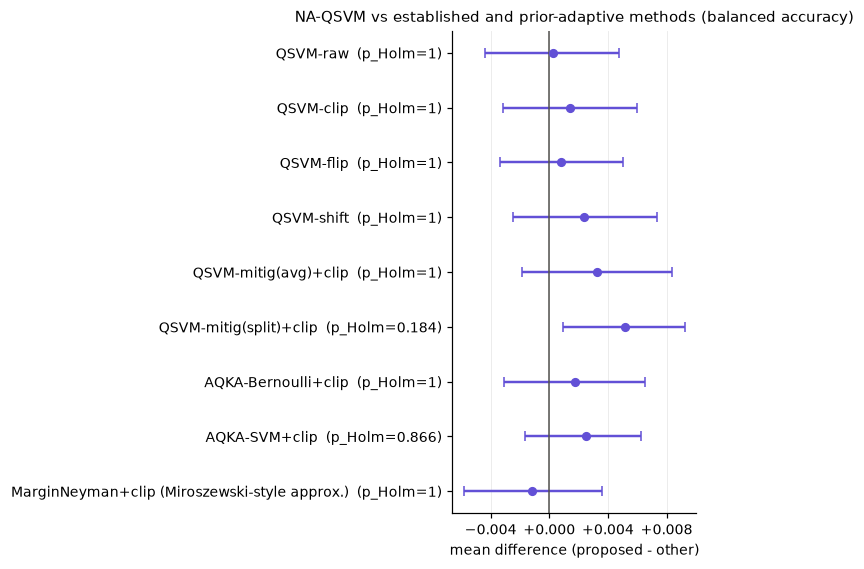

**Secondary (exploratory) tests** – Holm correction within each stratum

,stratum,comparison,metric,n_units,mean_diff,boot_ci_lo,boot_ci_hi,wins,ties,losses,p_holm
0,all,NA-QSVM (proposed) vs QSVM-raw,macro_f1,40,-0.0007,-0.0053,0.0038,18,0,22,1.0000
1,all,NA-QSVM (proposed) vs QSVM-clip,macro_f1,40,0.0006,-0.0041,0.0052,18,0,22,1.0000
2,all,NA-QSVM (proposed) vs QSVM-flip,macro_f1,40,0.0000,-0.0040,0.0041,20,0,20,1.0000
3,all,NA-QSVM (proposed) vs QSVM-shift,macro_f1,40,0.0013,-0.0037,0.0064,21,0,19,1.0000
4,all,NA-QSVM (proposed) vs QSVM-mitig(avg)+clip,macro_f1,40,0.0045,-0.0008,0.0099,26,0,14,1.0000
...,...,...,...,...,...,...,...,...,...,...,...
94,S=1024,NA-QSVM (proposed) vs QSVM-mitig(avg)+clip,balanced_accuracy,40,0.0050,0.0002,0.0099,26,2,12,0.3473
95,S=1024,NA-QSVM (proposed) vs QSVM-mitig(split)+clip,balanced_accuracy,40,0.0061,0.0005,0.0123,21,2,17,0.4884
96,S=1024,NA-QSVM (proposed) vs AQKA-Bernoulli+clip,balanced_accuracy,40,0.0111,0.0042,0.0181,28,2,10,0.0272
97,S=1024,NA-QSVM (proposed) vs AQKA-SVM+clip,balanced_accuracy,40,0.0048,-0.0022,0.0118,24,1,15,0.5236


In [30]:
COMPARE = ESTABLISHED + ALLOCATION_BASELINES
prim = nst.paired_comparison(q, PROPOSED, COMPARE, "balanced_accuracy", ["dataset", "seed"], ["noise", "shots_per_entry"])
prim.to_csv(os.path.join(TAB, "stats_primary_bacc.csv"), index=False)
display(Markdown("**Primary test: NA-QSVM minus baseline, balanced accuracy** (units = dataset × seed)"))
display(prim.round(4))
npl.forest(prim, "NA-QSVM vs established and prior-adaptive methods (balanced accuracy)", path=os.path.join(FIG, "fig_forest_primary.png")); plt.show()

sec = []
for metric in ["macro_f1", "accuracy"]:
    t = nst.paired_comparison(q, PROPOSED, COMPARE, metric, ["dataset", "seed"], ["noise", "shots_per_entry"])
    sec.append(t.assign(stratum="all"))
for nz in NOISES:
    t = nst.paired_comparison(q[q.noise == nz], PROPOSED, COMPARE, "balanced_accuracy", ["dataset", "seed"], ["shots_per_entry"])
    sec.append(t.assign(stratum=f"noise={nz}"))
for S in cfg.shots_per_entry:
    t = nst.paired_comparison(q[q.shots_per_entry == S], PROPOSED, COMPARE, "balanced_accuracy", ["dataset", "seed"], ["noise"])
    sec.append(t.assign(stratum=f"S={S}"))
secondary = pd.concat(sec, ignore_index=True)
secondary.to_csv(os.path.join(TAB, "stats_secondary.csv"), index=False)
display(Markdown("**Secondary (exploratory) tests** – Holm correction within each stratum"))
display(secondary[["stratum", "comparison", "metric", "n_units", "mean_diff", "boot_ci_lo", "boot_ci_hi",
                   "wins", "ties", "losses", "p_holm"]].round(4))

Friedman test over 80 blocks: chi2 = 8.859, p = 0.4504


,mean rank (1 = best)
MarginNeyman+clip (Miroszewski-style approx.),4.956
NA-QSVM (proposed),5.075
QSVM-raw,5.131
QSVM-clip,5.394
QSVM-flip,5.594
QSVM-shift,5.694
QSVM-mitig(split)+clip,5.750
QSVM-mitig(avg)+clip,5.781
AQKA-Bernoulli+clip,5.781
AQKA-SVM+clip,5.844


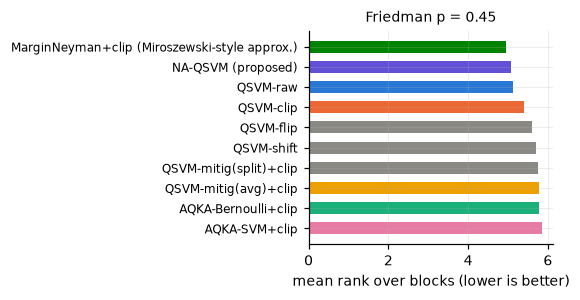

In [31]:
fr = nst.friedman(q.groupby(["dataset", "noise", "shots_per_entry", "method"], as_index=False).balanced_accuracy.mean(),
                  MAIN, "balanced_accuracy", ["dataset", "noise", "shots_per_entry"])
print(f"Friedman test over {fr['n_blocks']} blocks: chi2 = {fr['statistic']:.3f}, p = {fr['p_value']:.4g}")
ranks = pd.Series(fr["mean_ranks"]).rename("mean rank (1 = best)")
display(ranks.to_frame().round(3))
rep.save_json(fr, os.path.join(TAB, "stats_friedman.json"))
fig, ax = plt.subplots(figsize=(5.2, 2.8))
cols = [npl.STYLE.get(m, ("#888888", "o"))[0] for m in ranks.index]
ax.barh(range(len(ranks)), ranks.values, color=cols, height=0.6)
ax.set_yticks(range(len(ranks)), ranks.index, fontsize=8); ax.invert_yaxis()
ax.set_xlabel("mean rank over blocks (lower is better)")
ax.set_title(f"Friedman p = {fr['p_value']:.3g}", fontsize=9)
fig.tight_layout(); fig.savefig(os.path.join(FIG, "fig_mean_ranks.png"), dpi=200); plt.show()

### 10.2 Does diagonal-based mitigation help? (contribution C3, pre-declared for v2)
Paired comparisons with and without mitigation, everything else equal. Besides the Wilcoxon test for a difference, a
**TOST equivalence test** asks whether the accuracy difference lies within ±`cfg.equivalence_margin` (balanced accuracy).
"Mitigation does not help" is supported only if the difference is not significantly positive *and* equivalence (or a
significantly negative effect) is shown. The kernel-error change is reported alongside.

In [32]:
pairs = [("QSVM-mitig(avg)+clip", "QSVM-clip"), ("QSVM-mitig(split)+clip", "QSVM-clip"), (PROPOSED, "Abl: no mitigation")]
mit_rows = []
for a, b in pairs:
    for metric in ["balanced_accuracy", "kernel_rel_fro_err"]:
        piv = (q[q.method.isin([a, b])].groupby(["dataset", "seed", "method"])[metric].mean().unstack("method"))
        dd = (piv[a] - piv[b]).dropna().values
        lo, hi = nst.bootstrap_ci(dd)
        tt = nst.tost_paired(dd, cfg.equivalence_margin) if metric == "balanced_accuracy" else {}
        mit_rows.append(dict(comparison=f"{a} minus {b}", metric=metric, n_units=len(dd), mean_diff=float(np.mean(dd)),
                             boot_ci_lo=lo, boot_ci_hi=hi, p_wilcoxon=nst.wilcoxon_p(dd),
                             tost_margin=cfg.equivalence_margin if tt else np.nan,
                             p_tost=tt.get("p_tost", np.nan), equivalent=tt.get("equivalent", np.nan)))
mit = pd.DataFrame(mit_rows)
mit["p_holm"] = np.nan
for metric in mit.metric.unique():
    m_ = mit.metric == metric
    mit.loc[m_, "p_holm"] = nst.holm(mit.loc[m_, "p_wilcoxon"])
mit.to_csv(os.path.join(TAB, "stats_mitigation_effect.csv"), index=False)
display(Markdown("**Effect of mitigation** (units = dataset × seed; accuracy: Wilcoxon + TOST; kernel error: Wilcoxon)"))
display(mit.round(4))

**Effect of mitigation** (units = dataset × seed; accuracy: Wilcoxon + TOST; kernel error: Wilcoxon)

,comparison,metric,n_units,mean_diff,boot_ci_lo,boot_ci_hi,p_wilcoxon,tost_margin,p_tost,equivalent,p_holm
0,QSVM-mitig(avg)+clip minus QSVM-clip,balanced_accuracy,40,-0.0019,-0.0060,0.0023,0.2560,0.01,0.0003,True,0.5120
1,QSVM-mitig(avg)+clip minus QSVM-clip,kernel_rel_fro_err,40,-0.2229,-0.2288,-0.2163,0.0000,NaN,NaN,NaN,0.0000
2,QSVM-mitig(split)+clip minus QSVM-clip,balanced_accuracy,40,-0.0037,-0.0075,-0.0000,0.0916,0.01,0.0012,True,0.2749
3,QSVM-mitig(split)+clip minus QSVM-clip,kernel_rel_fro_err,40,-0.1984,-0.2042,-0.1919,0.0000,NaN,NaN,NaN,0.0000
4,NA-QSVM (proposed) minus Abl: no mitigation,balanced_accuracy,40,0.0018,-0.0011,0.0049,0.3714,0.01,0.0000,True,0.5120
5,NA-QSVM (proposed) minus Abl: no mitigation,kernel_rel_fro_err,40,-0.1998,-0.2064,-0.1931,0.0000,NaN,NaN,NaN,0.0000


## 11. Ablation studies

Each ablation removes or changes one component of NA-QSVM and keeps everything else (including the random-number
stream). Positive differences mean the full method is better. The *shot-saving* variant is not an ablation: it trades
test shots for accuracy, and its total-shot reduction is reported separately.

**Ablations: NA-QSVM minus variant, balanced accuracy**

,comparison,metric,n_units,mean_diff,median_diff,boot_ci_lo,boot_ci_hi,wins,ties,losses,rank_biserial,p_wilcoxon,p_holm,significant_0.05
0,NA-QSVM (proposed) vs Abl: uniform shots,balanced_accuracy,40,0.0005,-0.0017,-0.0033,0.0044,18,1,21,0.0128,0.9625,1.0000,False
1,NA-QSVM (proposed) vs Abl: no noise-aware ridge,balanced_accuracy,40,0.0030,0.0025,-0.0008,0.0066,27,2,11,0.3765,0.0365,0.1827,False
2,NA-QSVM (proposed) vs Abl: no mitigation,balanced_accuracy,40,0.0018,0.0017,-0.0011,0.0049,23,0,17,0.1622,0.3714,1.0000,False
3,NA-QSVM (proposed) vs Abl: no SV-restricted test,balanced_accuracy,40,0.0078,0.0078,0.0044,0.0111,31,0,9,0.6829,0.0002,0.0010,True
4,NA-QSVM (proposed) vs Abl: ridge c=1 (untuned),balanced_accuracy,40,-0.0025,-0.0019,-0.0058,0.0006,16,1,23,-0.3321,0.0738,0.2952,False
5,NA-QSVM (proposed) vs Abl: SV-weighted train a...,balanced_accuracy,40,0.0016,0.0017,-0.0021,0.0054,22,1,17,0.1269,0.4846,1.0000,False
6,NA-QSVM (proposed) vs Variant: shot-saving (SV...,balanced_accuracy,40,0.0084,0.0050,0.0051,0.0119,31,2,7,0.7530,0.0000,0.0003,True


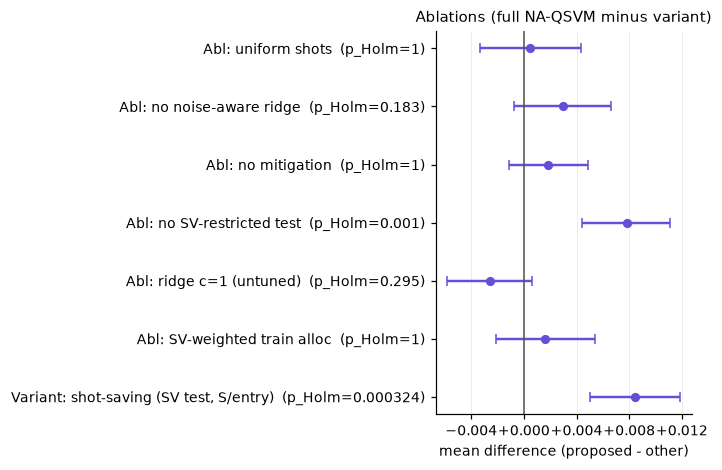

**Ablations: kernel error** (negative = full method has lower kernel error)

,comparison,mean_diff,boot_ci_lo,boot_ci_hi,p_holm
0,NA-QSVM (proposed) vs Abl: uniform shots,0.0001,-0.0031,0.0034,1.0
1,NA-QSVM (proposed) vs Abl: no noise-aware ridge,0.0269,0.0236,0.0303,0.0
2,NA-QSVM (proposed) vs Abl: no mitigation,-0.1998,-0.2064,-0.1931,0.0
3,NA-QSVM (proposed) vs Abl: no SV-restricted test,0.0000,0.0000,0.0000,1.0
4,NA-QSVM (proposed) vs Abl: ridge c=1 (untuned),-0.0288,-0.0324,-0.0252,0.0
5,NA-QSVM (proposed) vs Abl: SV-weighted train a...,-0.0087,-0.0114,-0.0061,0.0
6,NA-QSVM (proposed) vs Variant: shot-saving (SV...,0.0000,0.0000,0.0000,1.0


shot-saving variant uses 85.1% of the proposed method's total shots on average


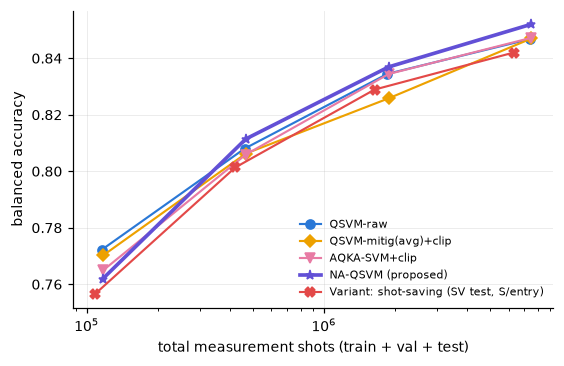

In [33]:
abl = nst.paired_comparison(q, PROPOSED, ABL, "balanced_accuracy", ["dataset", "seed"], ["noise", "shots_per_entry"])
abl.to_csv(os.path.join(TAB, "stats_ablation_bacc.csv"), index=False)
display(Markdown("**Ablations: NA-QSVM minus variant, balanced accuracy**"))
display(abl.round(4))
npl.forest(abl, "Ablations (full NA-QSVM minus variant)", path=os.path.join(FIG, "fig_forest_ablation.png")); plt.show()
abl_k = nst.paired_comparison(q, PROPOSED, ABL, "kernel_rel_fro_err", ["dataset", "seed"], ["noise", "shots_per_entry"])
abl_k.to_csv(os.path.join(TAB, "stats_ablation_kernel_error.csv"), index=False)
display(Markdown("**Ablations: kernel error** (negative = full method has lower kernel error)"))
display(abl_k[["comparison", "mean_diff", "boot_ci_lo", "boot_ci_hi", "p_holm"]].round(4))
saving = "Variant: shot-saving (SV test, S/entry)"
ratio = (q[q.method == saving].total_shots.mean() / q[q.method == PROPOSED].total_shots.mean())
print(f"shot-saving variant uses {ratio:.1%} of the proposed method's total shots on average")
npl.acc_vs_total_shots(q, ["QSVM-raw", "QSVM-mitig(avg)+clip", "AQKA-SVM+clip", PROPOSED, saving],
                       path=os.path.join(FIG, "fig_bacc_vs_total_shots.png")); plt.show()

## 12. Auto-generated findings

The text below is produced from the computed tables with fixed wording rules: a difference is called *significant*
only if the Holm-adjusted p < 0.05, and its direction comes from the sign of the mean paired difference.
Nothing here is edited by hand.

In [34]:
def verdict(r):
    if not np.isfinite(r.p_holm):
        return "test not computable"
    if r.p_holm < 0.05:
        return ("significantly **higher**" if r.mean_diff > 0 else "significantly **lower**") + f" (Holm p = {r.p_holm:.3g})"
    return f"no significant difference (Holm p = {r.p_holm:.3g})"

lines = [f"*Run: {cfg.mode} mode, simulator `{BACKEND}`, {len(cfg.datasets)} datasets × {len(cfg.seeds)} seeds {cfg.seeds[0]}–{cfg.seeds[-1]} × "
         f"{len(NOISES)} noise settings × {len(cfg.shots_per_entry)} shot budgets; {len(raw)} result rows; {n_fail} logged failures.*", ""]
# C1/C2 hidden ridge
lines.append("**C1/C2 – Hidden-ridge test** (relative decision difference to the raw noisy SVM; B = ideal kernel + hidden ridge, Z = no-ridge control):")
for _, r in hr_tab.iterrows():
    st_ = hr_stats[(hr_stats.noise == r.noise) & (hr_stats.shots_per_entry == r.shots_per_entry)].iloc[0]
    lines.append(f"- {r.noise}, shots={r.shots_per_entry}: Λ={r.lam:.3f}, r={r.hidden_ridge:.3f}; B {r.B_decision_rel_diff:.4f} vs Z {r.Z_decision_rel_diff:.4f}; "
                 f"prediction agreement B {r.B_pred_agreement:.3f} vs Z {r.Z_pred_agreement:.3f}; B closer in {st_.frac_B_closer:.0%} of splits (Holm p = {st_.p_holm:.3g})")
# C3 mitigation
lines += ["", "**C3 – Effect of diagonal-based mitigation** (paired, units = dataset × seed):"]
for _, r in mit.iterrows():
    if r.metric == "balanced_accuracy":
        eq = ("equivalent within ±%.3f (TOST p = %.3g)" % (r.tost_margin, r.p_tost)) if r.equivalent else ("equivalence NOT shown (TOST p = %.3g)" % r.p_tost)
        sig = ("significantly %s (Holm p = %.3g)" % ("higher" if r.mean_diff > 0 else "lower", r.p_holm)) if r.p_holm < 0.05 else ("no significant difference (Holm p = %.3g)" % r.p_holm)
        lines.append(f"- accuracy, {r.comparison}: {r.mean_diff:+.4f} [{r.boot_ci_lo:+.4f}, {r.boot_ci_hi:+.4f}] → {sig}; {eq}")
    else:
        lines.append(f"- kernel error, {r.comparison}: {r.mean_diff:+.4f} [{r.boot_ci_lo:+.4f}, {r.boot_ci_hi:+.4f}] (Holm p = {r.p_holm:.3g})")
# C4 / benchmark
lines += ["", "**C4 – NA-QSVM vs established and prior-adaptive methods** (balanced accuracy, NA-QSVM minus other; fair SV test protocol):"]
for _, r in prim.iterrows():
    lines.append(f"- vs {r.comparison.split(' vs ')[-1]}: {r.mean_diff:+.4f} [{r.boot_ci_lo:+.4f}, {r.boot_ci_hi:+.4f}], "
                 f"W/T/L = {r.wins}/{r.ties}/{r.losses} → {verdict(r)}")
lines += ["", "**Ablations (full NA-QSVM minus variant):**"]
for _, r in abl.iterrows():
    lines.append(f"- {r.comparison.split(' vs ')[-1]}: {r.mean_diff:+.4f} [{r.boot_ci_lo:+.4f}, {r.boot_ci_hi:+.4f}] → {verdict(r)}")
ke = u_all.groupby("method").kernel_rel_fro_err.mean()
lines += ["", "**Kernel-matrix error (rel. off-diagonal Frobenius, mean over units):** " +
          ", ".join(f"{m}: {ke.get(m, np.nan):.3f}" for m in MAIN)]
ideal_b = refs[refs.method.str.startswith("Ideal")].balanced_accuracy.mean()
rbf_b = refs[refs.method.str.contains("4-D")].balanced_accuracy.mean()
best_noisy = u_all.groupby("method").balanced_accuracy.mean()[MAIN]
lines += ["", f"**References:** ideal QSVM (exact, noise-free) balanced accuracy {ideal_b:.3f}; RBF-SVM on the same 4-D input {rbf_b:.3f}; "
          f"best finite-shot noisy quantum method on average: {best_noisy.idxmax()} ({best_noisy.max():.3f}). "
          + ("The classical RBF-SVM matches or exceeds the ideal quantum kernel on these data, so **no quantum advantage is indicated**."
             if rbf_b >= ideal_b - 1e-9 else
             "The ideal quantum kernel scores above the RBF-SVM on average here, but this is a small-scale simulation with a tuned classical baseline on 4 features and is **not evidence of quantum advantage**.")]
lines += ["", f"**Friedman test** over {fr['n_blocks']} blocks: p = {fr['p_value']:.3g}; mean ranks: " +
          ", ".join(f"{k} {v:.2f}" for k, v in fr["mean_ranks"].items())]
FINDINGS = "\n".join(lines)
with open(os.path.join(OUT, "FINDINGS.md"), "w") as f:
    f.write("# Auto-generated findings\n\n" + FINDINGS + "\n")
display(Markdown(FINDINGS))

*Run: FULL mode, simulator `aer`, 4 datasets × 10 seeds 2000–2009 × 5 noise settings × 4 shot budgets; 13720 result rows; 0 logged failures.*

**C1/C2 – Hidden-ridge test** (relative decision difference to the raw noisy SVM; B = ideal kernel + hidden ridge, Z = no-ridge control):
- global Λ=0.8, shots=exact: Λ=0.800, r=0.234; B 0.0000 vs Z 0.0848; prediction agreement B 1.000 vs Z 0.991; B closer in 100% of splits (Holm p = 3.82e-11)
- global Λ=0.8, shots=1024: Λ=0.800, r=0.234; B 0.0934 vs Z 0.1269; prediction agreement B 0.975 vs Z 0.973; B closer in 100% of splits (Holm p = 3.82e-11)
- global Λ=0.8, shots=64: Λ=0.800, r=0.234; B 0.3263 vs Z 0.3230; prediction agreement B 0.919 vs Z 0.915; B closer in 35% of splits (Holm p = 0.11)
- global Λ=0.5, shots=exact: Λ=0.500, r=0.938; B 0.0000 vs Z 0.2317; prediction agreement B 1.000 vs Z 0.975; B closer in 100% of splits (Holm p = 3.82e-11)
- global Λ=0.5, shots=1024: Λ=0.500, r=0.938; B 0.1036 vs Z 0.2540; prediction agreement B 0.969 vs Z 0.960; B closer in 100% of splits (Holm p = 3.82e-11)
- global Λ=0.5, shots=64: Λ=0.500, r=0.938; B 0.3661 vs Z 0.3907; prediction agreement B 0.900 vs Z 0.895; B closer in 70% of splits (Holm p = 0.000378)
- global Λ=0.25, shots=exact: Λ=0.250, r=2.812; B 0.0000 vs Z 0.4195; prediction agreement B 1.000 vs Z 0.941; B closer in 100% of splits (Holm p = 3.82e-11)
- global Λ=0.25, shots=1024: Λ=0.250, r=2.812; B 0.1312 vs Z 0.4514; prediction agreement B 0.967 vs Z 0.933; B closer in 100% of splits (Holm p = 3.82e-11)
- global Λ=0.25, shots=64: Λ=0.250, r=2.812; B 0.4278 vs Z 0.5749; prediction agreement B 0.859 vs Z 0.857; B closer in 98% of splits (Holm p = 3.82e-11)
- low, shots=exact: Λ=0.770, r=0.280; B 0.0079 vs Z 0.0979; prediction agreement B 0.998 vs Z 0.990; B closer in 100% of splits (Holm p = 3.82e-11)
- low, shots=1024: Λ=0.770, r=0.280; B 0.0940 vs Z 0.1338; prediction agreement B 0.978 vs Z 0.975; B closer in 100% of splits (Holm p = 3.82e-11)
- low, shots=64: Λ=0.770, r=0.280; B 0.3510 vs Z 0.3579; prediction agreement B 0.905 vs Z 0.902; B closer in 60% of splits (Holm p = 0.115)
- medium, shots=exact: Λ=0.483, r=1.006; B 0.0240 vs Z 0.2406; prediction agreement B 0.993 vs Z 0.975; B closer in 100% of splits (Holm p = 3.82e-11)
- medium, shots=1024: Λ=0.483, r=1.006; B 0.1154 vs Z 0.2685; prediction agreement B 0.968 vs Z 0.962; B closer in 100% of splits (Holm p = 3.82e-11)
- medium, shots=64: Λ=0.483, r=1.006; B 0.3771 vs Z 0.4186; prediction agreement B 0.893 vs Z 0.895; B closer in 90% of splits (Holm p = 1.88e-09)
- high, shots=exact: Λ=0.234, r=3.064; B 0.0586 vs Z 0.4448; prediction agreement B 0.988 vs Z 0.936; B closer in 100% of splits (Holm p = 3.82e-11)
- high, shots=1024: Λ=0.234, r=3.064; B 0.1501 vs Z 0.4743; prediction agreement B 0.964 vs Z 0.922; B closer in 100% of splits (Holm p = 3.82e-11)
- high, shots=64: Λ=0.234, r=3.064; B 0.4422 vs Z 0.5794; prediction agreement B 0.867 vs Z 0.853; B closer in 98% of splits (Holm p = 3.82e-11)
- thermal (mismatch), shots=exact: Λ=0.590, r=0.655; B 0.0489 vs Z 0.1912; prediction agreement B 0.985 vs Z 0.982; B closer in 100% of splits (Holm p = 3.82e-11)
- thermal (mismatch), shots=1024: Λ=0.590, r=0.655; B 0.1122 vs Z 0.2165; prediction agreement B 0.968 vs Z 0.963; B closer in 98% of splits (Holm p = 3.82e-11)
- thermal (mismatch), shots=64: Λ=0.590, r=0.655; B 0.3556 vs Z 0.3753; prediction agreement B 0.910 vs Z 0.908; B closer in 72% of splits (Holm p = 0.00181)

**C3 – Effect of diagonal-based mitigation** (paired, units = dataset × seed):
- accuracy, QSVM-mitig(avg)+clip minus QSVM-clip: -0.0019 [-0.0060, +0.0023] → no significant difference (Holm p = 0.512); equivalent within ±0.010 (TOST p = 0.000309)
- kernel error, QSVM-mitig(avg)+clip minus QSVM-clip: -0.2229 [-0.2288, -0.2163] (Holm p = 5.46e-12)
- accuracy, QSVM-mitig(split)+clip minus QSVM-clip: -0.0037 [-0.0075, -0.0000] → no significant difference (Holm p = 0.275); equivalent within ±0.010 (TOST p = 0.00124)
- kernel error, QSVM-mitig(split)+clip minus QSVM-clip: -0.1984 [-0.2042, -0.1919] (Holm p = 5.46e-12)
- accuracy, NA-QSVM (proposed) minus Abl: no mitigation: +0.0018 [-0.0011, +0.0049] → no significant difference (Holm p = 0.512); equivalent within ±0.010 (TOST p = 1.95e-06)
- kernel error, NA-QSVM (proposed) minus Abl: no mitigation: -0.1998 [-0.2064, -0.1931] (Holm p = 5.46e-12)

**C4 – NA-QSVM vs established and prior-adaptive methods** (balanced accuracy, NA-QSVM minus other; fair SV test protocol):
- vs QSVM-raw: +0.0002 [-0.0044, +0.0048], W/T/L = 20/1/19 → no significant difference (Holm p = 1)
- vs QSVM-clip: +0.0014 [-0.0032, +0.0059], W/T/L = 20/0/20 → no significant difference (Holm p = 1)
- vs QSVM-flip: +0.0008 [-0.0034, +0.0050], W/T/L = 20/1/19 → no significant difference (Holm p = 1)
- vs QSVM-shift: +0.0024 [-0.0025, +0.0073], W/T/L = 20/1/19 → no significant difference (Holm p = 1)
- vs QSVM-mitig(avg)+clip: +0.0033 [-0.0018, +0.0084], W/T/L = 25/1/14 → no significant difference (Holm p = 1)
- vs QSVM-mitig(split)+clip: +0.0051 [+0.0010, +0.0093], W/T/L = 26/1/13 → no significant difference (Holm p = 0.184)
- vs AQKA-Bernoulli+clip: +0.0018 [-0.0031, +0.0065], W/T/L = 23/0/17 → no significant difference (Holm p = 1)
- vs AQKA-SVM+clip: +0.0025 [-0.0016, +0.0063], W/T/L = 24/0/16 → no significant difference (Holm p = 0.866)
- vs MarginNeyman+clip (Miroszewski-style approx.): -0.0012 [-0.0058, +0.0036], W/T/L = 17/0/23 → no significant difference (Holm p = 1)

**Ablations (full NA-QSVM minus variant):**
- Abl: uniform shots: +0.0005 [-0.0033, +0.0044] → no significant difference (Holm p = 1)
- Abl: no noise-aware ridge: +0.0030 [-0.0008, +0.0066] → no significant difference (Holm p = 0.183)
- Abl: no mitigation: +0.0018 [-0.0011, +0.0049] → no significant difference (Holm p = 1)
- Abl: no SV-restricted test: +0.0078 [+0.0044, +0.0111] → significantly **higher** (Holm p = 0.001)
- Abl: ridge c=1 (untuned): -0.0025 [-0.0058, +0.0006] → no significant difference (Holm p = 0.295)
- Abl: SV-weighted train alloc: +0.0016 [-0.0021, +0.0054] → no significant difference (Holm p = 1)
- Variant: shot-saving (SV test, S/entry): +0.0084 [+0.0051, +0.0119] → significantly **higher** (Holm p = 0.000324)

**Kernel-matrix error (rel. off-diagonal Frobenius, mean over units):** QSVM-raw: 0.375, QSVM-clip: 0.367, QSVM-flip: 0.367, QSVM-shift: 0.375, QSVM-mitig(avg)+clip: 0.144, QSVM-mitig(split)+clip: 0.169, AQKA-Bernoulli+clip: 0.367, AQKA-SVM+clip: 0.377, MarginNeyman+clip (Miroszewski-style approx.): 0.374, NA-QSVM (proposed): 0.171

**References:** ideal QSVM (exact, noise-free) balanced accuracy 0.873; RBF-SVM on the same 4-D input 0.902; best finite-shot noisy quantum method on average: MarginNeyman+clip (Miroszewski-style approx.) (0.817). The classical RBF-SVM matches or exceeds the ideal quantum kernel on these data, so **no quantum advantage is indicated**.

**Friedman test** over 80 blocks: p = 0.45; mean ranks: MarginNeyman+clip (Miroszewski-style approx.) 4.96, NA-QSVM (proposed) 5.08, QSVM-raw 5.13, QSVM-clip 5.39, QSVM-flip 5.59, QSVM-shift 5.69, QSVM-mitig(split)+clip 5.75, QSVM-mitig(avg)+clip 5.78, AQKA-Bernoulli+clip 5.78, AQKA-SVM+clip 5.84

## 13. Literature-review checklist (novelty audit)

Written to `LITERATURE_CHECKLIST.md`. It lists the closest prior work found in the Oct 2026 audit (including a full reading of Heyraud et al. 2022), the status of
each component, search strings, and decision rules for what can be claimed.

In [35]:
%%writefile noise_aware_qsvm_research/LITERATURE_CHECKLIST.md
# Literature-review checklist and novelty audit (v2, 15 Oct 2026)

**Status of this audit.** Items marked [read in full] were read completely. Items marked [checked online] were checked
through their arXiv abstract or HTML pages on 15 Oct 2026; some HTML pages were incomplete, as noted. Other bibliographic
details were written from memory. **Verify every entry against the publisher or arXiv record before citing it.**
No experimental result in this package depends on these references.

## A. Closest prior work and how this paper relates to it

| # | Reference | What it does | Overlap with this paper | How to position |
|---|---|---|---|---|
| A1 | J. Xu, C. Li, D. Zeng, J. Paisley, Q. Zhao, "AQKA: Active Quantum Kernel Acquisition Under a Shot Budget", arXiv:2605.14672 (2026) [checked online] | Adaptive shot allocation over kernel entries. Closed-form rules for KRR and SVM: Prop. 4, $s_{ij}\propto\|\eta_i\eta_j\|\sqrt{K_{ij}(1-K_{ij})}$. Its "bernoulli-only" baseline is $s\propto\sqrt{K(1-K)}$. IBM hardware runs. No error mitigation. | **Very high** for allocation. NA-QSVM's pilot + Neyman step *is* AQKA's bernoulli-only baseline. | Do not claim allocation. Use AQKA-Bernoulli and AQKA-SVM as baselines (done, re-implemented). Ask the authors for code. |
| A2 | A. Miroszewski, "Adaptive Measurement Allocation for Learning Kernelized SVMs Under Noisy Observations", arXiv:2605.22275 (2026), with the ShotWise package [checked online; algorithm sections not retrievable] | Neyman-type allocation for kernel SVMs combining margin sensitivity $\alpha_i\alpha_j$, margin-violation probability $P_i$, and variance including a physical-noise term. Early stopping on dual-coefficient stability. IBM hardware runs. | **Very high** for SVM-aware allocation. | Baseline (an approximation from the published equations is included). Replace it with official ShotWise before submission. |
| A3 | A. Shastry, A. Jayakumar, A. Patel, C. Bhattacharyya, "Shot-frugal and Robust quantum kernel classifiers", arXiv:2210.06971 [checked online] | Chance-constrained SOCP (ShofaR). The shot-noise-derived diagonal shift $(c/2\sqrt N)\kappa(\delta)I$ in the regulariser avoids PSD clipping. Notes that prediction needs only kernels to the support vectors. | **High** for the noise-calibrated ridge (C4) and the SV-restricted test. | C4 differs only in calibrating the ridge *after* depolarizing mitigation (variance ×1/Λ²). Present C4 as a practical variant, not a headline. Consider ShofaR as an extra baseline. |
| A4 | V. Heyraud, Z. Li, Z. Denis, A. Le Boité, C. Ciuti, "Noisy quantum kernel machines", Phys. Rev. A 106, 052421 (2022) [read in full] | Dissipative spin-chain kernels Tr[ρρ′] with least-squares training. Decoherence lowers the kernel trace (average purity), which tightens a Rademacher bound, giving "implicit regularization". Gaussian measurement noise ≡ λ→λ+σ². An intercept ≡ centred kernel. | **Medium–high** in spirit for C1. | They give no exact equivalence, do not fix the diagonal to 1, and use no fidelity kernel, hinge loss or mitigation. C1 is an exact sharpening for the standard QSVM pipeline. Cite prominently. |
| A5 | T. Hubregtsen, D. Wierichs, E. Gil-Fuster, P.-J. H. S. Derks, P. K. Faehrmann, J. J. Meyer, "Training quantum embedding kernels on near-term quantum computers", Phys. Rev. A 106, 042431 (2022) | Diagonal-based depolarizing mitigation (single / average / split channel) and PSD regularisation. | Established component and baselines. | Cite as the source of the mitigation that C1 analyses. |
| A6 | S. Govender, I. Sinayskiy, "The Cross-Kernel Margin: A Robustness Measure for Quantum Kernel Methods", arXiv:2601.23084 (2026) [checked online] | Local vs global depolarizing models for QSVMs; Tikhonov-stabilised SVM dual; margin-based robustness bounds. | Medium (Tikhonov term; local vs global noise). | Read Section on Tikhonov stabilisation; check that it does not state C1. |
| A7 | G. Lo Monaco et al., "Who can sample forever? Shot noise effects in quantum linear regression", arXiv:2610.12015 (2026) [checked online] | Shot noise in fidelity-kernel / ELM regression; notes an implicit Tikhonov term from shot noise. | Low–medium (regression, shot noise only). | Cite in related work. |
| A8 | V. Scavino, "Decision Kernels for Quantum Error Mitigation", arXiv:2607.02888 (2026) [checked online] | Argues that mitigation accuracy gains need not improve downstream decisions; shift-invariant decisions. Not about kernels or SVMs. | Low (same moral, different object). | Cite as supporting context for "accuracy ≠ decision". |
| A9 | G. Gentinetta, A. Thomsen, D. Sutter, S. Woerner, "The complexity of quantum support vector machines", Quantum 8, 1225 (2024) [checked online] | Shot complexity of QSVM training (dual and primal). | Background. | Cite for shot-cost motivation. |

## B. Foundational and established methods (cite for the parts labelled "established")
- V. Havlíček et al., Nature (2019): ZZ feature map and quantum-kernel SVM.
- M. Schuld, N. Killoran, Phys. Rev. Lett. (2019): quantum feature Hilbert spaces.
- S. Thanasilp, S. Wang, M. Cerezo, Z. Holmes, Nature Communications (2024): exponential concentration and shot cost.
- X. Wang, Y. Du, Y. Luo, D. Tao, Quantum (2021): quantum kernels in the NISQ era (noise and finite shots).
- R. Shaydulin, S. M. Wild, Phys. Rev. A (2022): kernel bandwidth.
- N. J. Higham, Linear Algebra Appl. (1988): nearest PSD matrix (eigenvalue clipping).
- Y. Chen, E. K. Garcia, M. R. Gupta, A. Rahimi, L. Cazzanti, JMLR (2009): clip/flip/shift for indefinite kernels.
- C. Cortes, M. Mohri, A. Rostamizadeh, JMLR (2012): centered kernel alignment.
- J. Neyman, J. R. Stat. Soc. (1934): optimal allocation.
- A. S. Bandeira, R. van Handel, Ann. Probab. (2016): spectral norm of random matrices with independent entries.
- J. Demšar, JMLR (2006): statistical comparison of classifiers.
- D. Lakens, Social Psychological and Personality Science (2017): equivalence testing (TOST).

## C. Component status after this audit

| Component | Status |
|---|---|
| Fidelity kernel, binomial shot model, PSD repair, diagonal mitigation | Established |
| Adaptive shot allocation (pilot + Neyman / Bernoulli) | **Published** (A1, A2): baseline only |
| SV-restricted test measurement | Standard SVM property (A3 notes it): applied to all methods, not claimed |
| Noise-calibrated ridge (C4) | **Largely covered** by A3; only the post-mitigation calibration is new; minor claim |
| Hidden-ridge theorem (C1) | **Not found in A1–A9**; closest is A4 (implicit regularisation via a bound). Claimable as an exact sharpening, after reading A6 fully |
| Direct test of C1 (C2), fair equal-budget benchmark with TOST (C3) | Not found; claimable as empirical contributions |

## D. Remaining checks before submission
1. Read A6 (cross-kernel margin) in full: does its Tikhonov-stabilised dual coincide with the hidden ridge?
2. Obtain the full A2 text and the ShotWise code; replace the approximation.
3. Ask the A1 authors for code or confirm the AQKA-SVM re-implementation details (solver, rounding).
4. Search again just before submission using the queries below (the field is moving fast: A1, A2, A6–A8 all appeared in 2026).

Query strings (arXiv quant-ph / cs.LG, Google Scholar, IEEE Xplore, Scopus):
1. "quantum kernel" AND (mitigation OR "depolarizing") AND (SVM OR "support vector") AND (regularization OR ridge)
2. "quantum kernel" AND "diagonal" AND (depolarizing OR "noise rate")
3. "quantum kernel" AND ("shot allocation" OR "measurement allocation" OR "shot budget")
4. "noisy quantum kernel" AND ("implicit regularization" OR Tikhonov)
5. Forward citations of A4, A5, A1, A2.

## E. Decision rules
- Claim C1 only as an exact result *for the stated noise model*, cite A4 as the conceptual predecessor, and report §8b's
  approximation quality under local noise.
- Claim C3's "mitigation does not help" only where the TOST equivalence test (or a significantly negative effect) supports it.
- Do not claim allocation or the SV-restricted test as contributions.
- Never claim quantum advantage; the RBF-SVM reference is reported for that reason.

Writing noise_aware_qsvm_research/LITERATURE_CHECKLIST.md


In [36]:
display(Markdown(open(os.path.join(OUT, "LITERATURE_CHECKLIST.md")).read()))

# Literature-review checklist and novelty audit (v2, 15 Oct 2026)

**Status of this audit.** Items marked [read in full] were read completely. Items marked [checked online] were checked
through their arXiv abstract or HTML pages on 15 Oct 2026; some HTML pages were incomplete, as noted. Other bibliographic
details were written from memory. **Verify every entry against the publisher or arXiv record before citing it.**
No experimental result in this package depends on these references.

## A. Closest prior work and how this paper relates to it

| # | Reference | What it does | Overlap with this paper | How to position |
|---|---|---|---|---|
| A1 | J. Xu, C. Li, D. Zeng, J. Paisley, Q. Zhao, "AQKA: Active Quantum Kernel Acquisition Under a Shot Budget", arXiv:2605.14672 (2026) [checked online] | Adaptive shot allocation over kernel entries. Closed-form rules for KRR and SVM: Prop. 4, $s_{ij}\propto\|\eta_i\eta_j\|\sqrt{K_{ij}(1-K_{ij})}$. Its "bernoulli-only" baseline is $s\propto\sqrt{K(1-K)}$. IBM hardware runs. No error mitigation. | **Very high** for allocation. NA-QSVM's pilot + Neyman step *is* AQKA's bernoulli-only baseline. | Do not claim allocation. Use AQKA-Bernoulli and AQKA-SVM as baselines (done, re-implemented). Ask the authors for code. |
| A2 | A. Miroszewski, "Adaptive Measurement Allocation for Learning Kernelized SVMs Under Noisy Observations", arXiv:2605.22275 (2026), with the ShotWise package [checked online; algorithm sections not retrievable] | Neyman-type allocation for kernel SVMs combining margin sensitivity $\alpha_i\alpha_j$, margin-violation probability $P_i$, and variance including a physical-noise term. Early stopping on dual-coefficient stability. IBM hardware runs. | **Very high** for SVM-aware allocation. | Baseline (an approximation from the published equations is included). Replace it with official ShotWise before submission. |
| A3 | A. Shastry, A. Jayakumar, A. Patel, C. Bhattacharyya, "Shot-frugal and Robust quantum kernel classifiers", arXiv:2210.06971 [checked online] | Chance-constrained SOCP (ShofaR). The shot-noise-derived diagonal shift $(c/2\sqrt N)\kappa(\delta)I$ in the regulariser avoids PSD clipping. Notes that prediction needs only kernels to the support vectors. | **High** for the noise-calibrated ridge (C4) and the SV-restricted test. | C4 differs only in calibrating the ridge *after* depolarizing mitigation (variance ×1/Λ²). Present C4 as a practical variant, not a headline. Consider ShofaR as an extra baseline. |
| A4 | V. Heyraud, Z. Li, Z. Denis, A. Le Boité, C. Ciuti, "Noisy quantum kernel machines", Phys. Rev. A 106, 052421 (2022) [read in full] | Dissipative spin-chain kernels Tr[ρρ′] with least-squares training. Decoherence lowers the kernel trace (average purity), which tightens a Rademacher bound, giving "implicit regularization". Gaussian measurement noise ≡ λ→λ+σ². An intercept ≡ centred kernel. | **Medium–high** in spirit for C1. | They give no exact equivalence, do not fix the diagonal to 1, and use no fidelity kernel, hinge loss or mitigation. C1 is an exact sharpening for the standard QSVM pipeline. Cite prominently. |
| A5 | T. Hubregtsen, D. Wierichs, E. Gil-Fuster, P.-J. H. S. Derks, P. K. Faehrmann, J. J. Meyer, "Training quantum embedding kernels on near-term quantum computers", Phys. Rev. A 106, 042431 (2022) | Diagonal-based depolarizing mitigation (single / average / split channel) and PSD regularisation. | Established component and baselines. | Cite as the source of the mitigation that C1 analyses. |
| A6 | S. Govender, I. Sinayskiy, "The Cross-Kernel Margin: A Robustness Measure for Quantum Kernel Methods", arXiv:2601.23084 (2026) [checked online] | Local vs global depolarizing models for QSVMs; Tikhonov-stabilised SVM dual; margin-based robustness bounds. | Medium (Tikhonov term; local vs global noise). | Read Section on Tikhonov stabilisation; check that it does not state C1. |
| A7 | G. Lo Monaco et al., "Who can sample forever? Shot noise effects in quantum linear regression", arXiv:2610.12015 (2026) [checked online] | Shot noise in fidelity-kernel / ELM regression; notes an implicit Tikhonov term from shot noise. | Low–medium (regression, shot noise only). | Cite in related work. |
| A8 | V. Scavino, "Decision Kernels for Quantum Error Mitigation", arXiv:2607.02888 (2026) [checked online] | Argues that mitigation accuracy gains need not improve downstream decisions; shift-invariant decisions. Not about kernels or SVMs. | Low (same moral, different object). | Cite as supporting context for "accuracy ≠ decision". |
| A9 | G. Gentinetta, A. Thomsen, D. Sutter, S. Woerner, "The complexity of quantum support vector machines", Quantum 8, 1225 (2024) [checked online] | Shot complexity of QSVM training (dual and primal). | Background. | Cite for shot-cost motivation. |

## B. Foundational and established methods (cite for the parts labelled "established")
- V. Havlíček et al., Nature (2019): ZZ feature map and quantum-kernel SVM.
- M. Schuld, N. Killoran, Phys. Rev. Lett. (2019): quantum feature Hilbert spaces.
- S. Thanasilp, S. Wang, M. Cerezo, Z. Holmes, Nature Communications (2024): exponential concentration and shot cost.
- X. Wang, Y. Du, Y. Luo, D. Tao, Quantum (2021): quantum kernels in the NISQ era (noise and finite shots).
- R. Shaydulin, S. M. Wild, Phys. Rev. A (2022): kernel bandwidth.
- N. J. Higham, Linear Algebra Appl. (1988): nearest PSD matrix (eigenvalue clipping).
- Y. Chen, E. K. Garcia, M. R. Gupta, A. Rahimi, L. Cazzanti, JMLR (2009): clip/flip/shift for indefinite kernels.
- C. Cortes, M. Mohri, A. Rostamizadeh, JMLR (2012): centered kernel alignment.
- J. Neyman, J. R. Stat. Soc. (1934): optimal allocation.
- A. S. Bandeira, R. van Handel, Ann. Probab. (2016): spectral norm of random matrices with independent entries.
- J. Demšar, JMLR (2006): statistical comparison of classifiers.
- D. Lakens, Social Psychological and Personality Science (2017): equivalence testing (TOST).

## C. Component status after this audit

| Component | Status |
|---|---|
| Fidelity kernel, binomial shot model, PSD repair, diagonal mitigation | Established |
| Adaptive shot allocation (pilot + Neyman / Bernoulli) | **Published** (A1, A2): baseline only |
| SV-restricted test measurement | Standard SVM property (A3 notes it): applied to all methods, not claimed |
| Noise-calibrated ridge (C4) | **Largely covered** by A3; only the post-mitigation calibration is new; minor claim |
| Hidden-ridge theorem (C1) | **Not found in A1–A9**; closest is A4 (implicit regularisation via a bound). Claimable as an exact sharpening, after reading A6 fully |
| Direct test of C1 (C2), fair equal-budget benchmark with TOST (C3) | Not found; claimable as empirical contributions |

## D. Remaining checks before submission
1. Read A6 (cross-kernel margin) in full: does its Tikhonov-stabilised dual coincide with the hidden ridge?
2. Obtain the full A2 text and the ShotWise code; replace the approximation.
3. Ask the A1 authors for code or confirm the AQKA-SVM re-implementation details (solver, rounding).
4. Search again just before submission using the queries below (the field is moving fast: A1, A2, A6–A8 all appeared in 2026).

Query strings (arXiv quant-ph / cs.LG, Google Scholar, IEEE Xplore, Scopus):
1. "quantum kernel" AND (mitigation OR "depolarizing") AND (SVM OR "support vector") AND (regularization OR ridge)
2. "quantum kernel" AND "diagonal" AND (depolarizing OR "noise rate")
3. "quantum kernel" AND ("shot allocation" OR "measurement allocation" OR "shot budget")
4. "noisy quantum kernel" AND ("implicit regularization" OR Tikhonov)
5. Forward citations of A4, A5, A1, A2.

## E. Decision rules
- Claim C1 only as an exact result *for the stated noise model*, cite A4 as the conceptual predecessor, and report §8b's
  approximation quality under local noise.
- Claim C3's "mitigation does not help" only where the TOST equivalence test (or a significantly negative effect) supports it.
- Do not claim allocation or the SV-restricted test as contributions.
- Never claim quantum advantage; the RBF-SVM reference is reported for that reason.


## 14. Limitations and threats to validity

* **Simulation only.** Noise is a parametrised model (local depolarizing, T1/T2 relaxation, symmetric readout).
  Real devices add crosstalk, coherent errors, drift and correlated readout errors. Results may not transfer.
* **Small scale.** 4 qubits, $N=60$ training points, 4 small tabular datasets. Kernel concentration, shot cost and the
  relative value of each component can change with qubit count and $N$.
* **Global-depolarizing assumption.** Mitigation assumes a global depolarizing channel. Local and non-unital noise
  (the thermal setting) violate it on purpose, which tests robustness but does not cover every hardware error.
* **Adaptive pooling bias.** Pooling pilot and phase-2 counts after a data-dependent allocation gives an $O(1/S)$ bias. It is
  included in the reported kernel errors but is not corrected.
* **Hyper-parameter freedom.** NA-QSVM tunes one extra parameter ($c$). The ablation "ridge c=1 (untuned)" shows how much
  depends on that tuning. Validation sets are small (30 points), so selection is noisy for every method.
* **Dependence between rows.** Rows of one split share data. Primary tests therefore use the split as the unit; per-cell
  CIs over 10 seeds are wide.
* **Bandwidth.** Chosen by a label-free rule. Other bandwidths or feature maps can change the ranking.
* **Runtime.** Reported runtimes are classical post-processing on a CPU. Shot counts are the hardware-relevant cost; circuit
  latency on real devices is not modelled.
* **Prior-work baselines are re-implementations.** AQKA-SVM follows Prop. 4 and the paper's default hyper-parameters, but
  the paper leaves the dual-coefficient solver and rounding unspecified. The margin-aware Neyman rule is only an
  approximation of Miroszewski (2026), whose full algorithm and ShotWise code were not available here. Replace both with the
  authors' code before submission if possible.
* **Theorem 1 is exact only under global depolarizing noise.** §8b quantifies the approximation under local and non-unital
  noise; hardware noise may deviate further. Λ in §8b is an oracle quantity.
* **Design after seeing v1.** The v2 additions were designed after the v1 results; they are evaluated on fresh seeds, but
  the datasets are the same.
* **Novelty.** See Section 13: adaptive shot allocation and shot-robust kernel SVMs have direct prior art.

## 15. Save everything and build `noise_aware_qsvm_research.zip`

Writes the environment and dependency information, the README (with the auto-generated findings) and the ZIP. The ZIP
contains the source package, configuration, raw CSV results, summary tables (CSV and LaTeX), figures (PNG and PDF),
self-check results, the literature checklist and, if found next to it, this notebook. The exact-probability cache is excluded.

In [37]:
env = rep.environment_info(dict(run_mode=cfg.mode, simulator_backend=BACKEND, qiskit_crosscheck=QISKIT_CROSSCHECK,
                                grid_minutes=round(GRID_SECONDS / 60, 2)))
rep.save_json(env, os.path.join(OUT, "environment.json"))
rep.write_requirements(os.path.join(OUT, "requirements.txt"), env)
cfg.save(os.path.join(OUT, "configs", "experiment_config.json"))
rep.save_json({k: v for k, v in NA_VARIANTS.items()}, os.path.join(OUT, "configs", "method_variants.json"))

readme = f'''# Why error mitigation does not help quantum-kernel SVMs: research package (v2)

Paper (working title): *Why Error Mitigation Does Not Help Quantum-Kernel SVMs: An Equal-Shot-Budget Analysis and a Noise-Calibrated Alternative*
(earlier title: *A Noise-Aware Hybrid Quantum Support Vector Machine for Robust Classification on Near-Term Quantum Devices*)

Generated automatically by `noise_aware_qsvm_research.ipynb` on {env["timestamp_utc"]}
({cfg.mode} mode, simulator backend `{BACKEND}`, Qiskit cross-check: {QISKIT_CROSSCHECK}).

## What is in this folder
| Path | Content |
|---|---|
| `src/naqsvm/` | complete source code (importable package) |
| `configs/experiment_config.json` | every setting of this run (datasets, seeds, noise, shots, grids, bandwidths) |
| `configs/method_variants.json` | options of the proposed method and its ablations |
| `results/raw_results.csv` | one row per dataset × seed × noise × shots × method (all metrics) |
| `results/hidden_ridge_check.csv` | per split × noise × shots results of the Theorem-1 test (§8b) |
| `results/simulation_log.csv` | per-block simulator backend, time, exact Λ, Neyman oracle efficiency |
| `results/split_indices.csv` | exact train/val/test row indices (reproducibility, leakage audit) |
| `results/self_checks.csv` | outcome of all correctness checks |
| `results/summary_*.csv`, `results/bandwidth_calibration.csv` | aggregated results |
| `tables/` | Tables 1–6 and statistical tests incl. mitigation TOST (CSV; LaTeX for Tables 1–2) |
| `figures/` | all figures (PNG and PDF) |
| `FINDINGS.md` | auto-generated findings (numbers only) |
| `LITERATURE_CHECKLIST.md` | novelty audit: closest prior work, search protocol, decision rules |
| `environment.json`, `requirements.txt` | software and hardware environment of this run |

## Contributions and their status
* C1 Hidden-ridge theorem (exact under global depolarizing noise): fixing diag(K)=1 ≡ ideal kernel + ridge (1−Λ)(1−1/d)/Λ with box ΛC;
  mitigation removes this ridge. Sharpens Heyraud et al. (PRA 2022).
* C2 Direct test of C1 under global, local, non-unital noise and finite shots (`results/hidden_ridge_check.csv`).
* C3 Equal-shot-budget benchmark, fair SV-restricted test protocol for every method, mitigation equivalence tests (TOST).
* C4 NA-QSVM: explicit ridge calibrated to shot noise after mitigation (close to ShofaR in spirit; not a headline claim).
* Established: fidelity-kernel QSVM, binomial shot model, PSD clip/flip/shift, depolarizing mitigation (Hubregtsen et al. 2022).
* Prior work re-implemented as baselines: AQKA-Bernoulli and AQKA-SVM (Xu et al. 2026); margin-aware Neyman approximating Miroszewski (2026).

## How to reproduce
1. Open `noise_aware_qsvm_research.ipynb` in Google Colab or Jupyter and run all cells
   (`RUN_MODE="QUICK"` for a smoke test). Python ≥ 3.10.
2. Or, from Python: `sys.path.insert(0, "src")`, then use `naqsvm.experiment.run_grid`.
Seeds: evaluation {cfg.seeds}; bandwidth pilot {cfg.pilot_seeds}. All random streams are derived from these seeds.

## Findings of this run
{FINDINGS}

## Limitations
Simulation only (parametrised noise, 4 qubits, N = {cfg.n_train} training points); no hardware runs; no claim of quantum advantage;
novelty must be confirmed with `LITERATURE_CHECKLIST.md`. See Section 14 of the notebook for the full list.
'''
with open(os.path.join(OUT, "README.md"), "w") as f:
    f.write(readme)

nb_candidates = [p for p in ["noise_aware_qsvm_research.ipynb", "/content/noise_aware_qsvm_research.ipynb"] if os.path.exists(p)]
files = rep.make_zip(OUT, "noise_aware_qsvm_research.zip", extra_files=nb_candidates)
print(f"ZIP written: {os.path.abspath('noise_aware_qsvm_research.zip')}  ({os.path.getsize('noise_aware_qsvm_research.zip')/1e6:.2f} MB, {len(files)} files)")
print("notebook included:", bool(nb_candidates))
try:
    from google.colab import files as colab_files     # offer the download in Colab
    colab_files.download("noise_aware_qsvm_research.zip")
except Exception:
    pass

ZIP written: /Users/atultripathi/Library/CloudStorage/OneDrive-manit.ac.in/IEEE_ACCESS_2/noise_aware_qsvm_research.zip  (3.97 MB, 72 files)
notebook included: False
